# Análisis y optimización de estrategias en Batalla Naval mediante funciones de probabilidad

Este proyecto implementa y compara distintas estrategias para resolver el juego de Batalla Naval desde una perspectiva probabilística y computacional.

El objetivo principal es estudiar cómo cambia la eficiencia del juego cuando la selección de cada disparo utiliza diferentes niveles de información sobre el estado observable del tablero. Para ello se comparan estrategias heurísticas tradicionales, como Paridad y Hunt/Target, con una estrategia basada en el conteo de encajes consistentes, definida mediante la función \(C_t(v)\).

La idea central consiste en representar, en cada instante \(t\), toda la información disponible después de los disparos realizados y utilizarla para determinar qué posiciones siguen siendo compatibles con los barcos que aún no han sido hundidos. A partir de estos encajes posibles se construye un mapa de puntuaciones sobre el tablero y se selecciona como siguiente disparo una celda perteneciente al máximo de dicho mapa.

El proyecto se desarrolla en varias etapas:

1. Definición formal de las reglas, el tablero y la flota.
2. Construcción del motor de simulación de Batalla Naval.
3. Implementación de las estrategias de disparo.
4. Construcción de los encajes consistentes y del mapa \(C_t(v)\).
5. Simulación de partidas mediante métodos de Monte Carlo.
6. Comparación estadística de las estrategias.
7. Evaluación de la eficiencia en número de disparos y costo computacional.
8. Análisis de estabilidad, robustez y convergencia de los resultados.

La unidad experimental corresponde a una configuración válida de la flota. Para garantizar comparaciones justas, cada estrategia es evaluada sobre las mismas configuraciones de barcos, permitiendo analizar las diferencias de desempeño de manera pareada.

La principal variable de respuesta es el número total de disparos necesarios para hundir completamente la flota, de manera que una estrategia se considera más eficiente cuando requiere, en promedio, un menor número de disparos.

Todo el código busca mantener correspondencia directa con la notación matemática y la metodología desarrolladas en la tesis, de modo que la implementación computacional pueda interpretarse como una traducción del modelo teórico.

### 1. Librerías y reproducibilidad

En esta sección se importan las herramientas necesarias para construir el motor de Batalla Naval, implementar las estrategias, ejecutar las simulaciones de Monte Carlo y analizar sus resultados. Además, se fija una semilla aleatoria para garantizar que los experimentos puedan reproducirse bajo las mismas condiciones.

In [ ]:
# ============================================================
# 1 LIBRERÍAS
# ============================================================
import copy                                                                     #Permite crear copias independientes de las flotas para comparar estrategias.
import random                                                                   #Permite generar configuraciones aleatorias y controlar la reproducibilidad.
import time                                                                     #Permite medir el tiempo de ejecución de simulaciones y estrategias.


# --- Cálculo manejo de datos ---

import numpy as np                                                              #Permite realizar operaciones numéricas y trabajar con matrices.
import pandas as pd                                                             #Permite organizar y analizar los resultados de las simulaciones.
import math                                                                     #Permite redondear hacia arriba el tamaño de muestra requerido.
from scipy.stats import t                                                       #Importa la distribución t para construir los intervalos de confianza.


# --- Visualización ---

import matplotlib.pyplot as plt                                                 #Permite construir los gráficos utilizados en el análisis de resultados.
import seaborn as sns                                                           #Importa funciones estadísticas para gráficos de distribución.
from matplotlib.animation import FuncAnimation, PillowWriter                    #Importa las herramientas necesarias para crear el GIF.
from IPython.display import Image, display                                     #Importa la herramienta para visualizar el GIF.
import ipywidgets as widgets                                                     #Importa los componentes interactivos utilizados para construir el tablero.
from IPython.display import display, clear_output                                #Importa las herramientas de visualización del entorno Jupyter.


# --- Ejecución paralela ---

from multiprocessing import Pool, cpu_count                                     #Permite distribuir simulaciones entre varios núcleos del procesador.


# --- Visualización dentro del notebook ---

from IPython.display import display                                             #Permite mostrar tablas y objetos de forma estructurada dentro del notebook.


# ============================================================
# REPRODUCIBILIDAD
# ============================================================

SEMILLA = 2026                                                                 #Define la semilla general utilizada para reproducir los experimentos.

random.seed(SEMILLA)                                                           #Fija la semilla del generador aleatorio estándar de Python.

np.random.seed(SEMILLA)                                                        #Fija la semilla del generador aleatorio de NumPy.


print("Semilla inicial:", SEMILLA)                                              #Muestra la semilla utilizada en la ejecución.

print("Núcleos disponibles:", cpu_count())                                     #Muestra el número de núcleos disponibles para procesamiento paralelo.

Semilla inicial: 2026
Núcleos disponibles: 2


## 2. Reglas del modelo

En esta sección se definen las condiciones generales bajo las cuales se desarrollarán todas las simulaciones.

El tablero utilizado es de tamaño $10 \times 10$ y la flota está compuesta por
barcos de longitudes \(5, 4, 3, 3\) y \(2\). Cada barco puede ubicarse horizontal o verticalmente.

Las reglas adoptadas para este proyecto son:

- Los barcos no pueden solaparse.
- Se permite que dos barcos ocupen celdas adyacentes.
- No se permiten disparos repetidos sobre una misma celda.
- Los posibles resultados de un disparo son `agua`, `tocado` o `hundido`.
- Cuando una estrategia tiene varias celdas con la misma prioridad, el desempate se realiza aleatoriamente.

Estas reglas permanecen constantes para todas las estrategias, de manera que cualquier diferencia observada en los resultados dependa únicamente de la política utilizada para seleccionar los disparos.

In [ ]:
# ============================================================
# 2 REGLAS
# ============================================================

TAMANO_TABLERO = 10

FLOTA_ESTANDAR = [5, 4, 3, 3, 2]                                           #Define las longitudes de los barcos de la flota estándar.
LONGITUDES_FLOTA = list(FLOTA_ESTANDAR)                                    #Crea una copia independiente de las longitudes de la flota estándar.

ORIENTACIONES = ["H", "V"]
RESULTADOS_DISPARO = ["agua", "tocado", "hundido"]

PERMITIR_SOLAPE = False
PERMITIR_ADYACENCIA = True
PERMITIR_DISPAROS_REPETIDOS = False

REGLA_DESEMPATE = "aleatorio"
MAXIMO_INTENTOS_COLOCACION = 1000

## 3. Representación del tablero

En esta sección se define la estructura computacional utilizada para representar el tablero de Batalla Naval y las coordenadas que lo componen.

El tablero se modela como una cuadrícula de tamaño $10 \times 10$, donde cada posición se identifica mediante una coordenada $(fila, columna)$. Esta representación permite trabajar de forma directa con las ubicaciones de los barcos, los disparos realizados y la información observable durante la partida.

La estructura del tablero servirá como base para:

- ubicar las celdas ocupadas por cada barco;
- registrar los disparos realizados;
- identificar celdas disponibles;
- construir los estados observables de la partida;
- calcular posteriormente los mapas de puntuación asociados a las estrategias probabilísticas.



In [ ]:
# ============================================================
# 3. TABLERO
# ============================================================

def crear_tablero(tamano_tablero=TAMANO_TABLERO):                               #Crea un tablero vacío de tamaño N x N.
    return np.zeros((tamano_tablero, tamano_tablero), dtype=int)


def celda_dentro_tablero(celda, tamano_tablero=TAMANO_TABLERO):                 #Verifica si una celda pertenece al tablero
    fila, columna = celda
    return 0 <= fila < tamano_tablero and 0 <= columna < tamano_tablero


def obtener_todas_las_celdas(tamano_tablero=TAMANO_TABLERO):                    #Devuelve todas las celdas del tablero
    celdas = []
    for fila in range(tamano_tablero):
        for columna in range(tamano_tablero):
            celdas.append((fila, columna))
    return celdas


## 4. Barcos y generación de la flota

En esta sección se define cómo se representa cada barco y cómo se construye una configuración válida de la flota sobre el tablero.

Cada barco queda determinado por su longitud, orientación y conjunto de celdas ocupadas. Para una longitud $L$, un barco puede ubicarse horizontal o verticalmente siempre que todas sus celdas permanezcan dentro de los límites del tablero.

La generación de la flota se realiza de forma aleatoria, respetando las reglas establecidas previamente.

El proceso de generación se repite hasta obtener una configuración válida. Esta configuración representa el estado oculto de la partida y será utilizada posteriormente como escenario común para evaluar las diferentes estrategias de disparo.

Mantener separada la generación de la flota de las estrategias es fundamental para garantizar que ninguna política tenga acceso a información que no estaría disponible durante una partida real.

In [ ]:
# ============================================================
#  4. GENERACIÓN DE LA FLOTA
# ============================================================

def generar_celdas_barco(fila_inicial, columna_inicial, longitud, orientacion):    #Genera las celdas ocupadas por un barco según su posición inicial y orientación.
    celdas = set()                                                                 #Inicializa el conjunto de celdas ocupadas por el barco.

    for desplazamiento in range(longitud):                                         #Recorre cada segmento del barco.
        if orientacion == "H":                                                      #Verifica si el barco tiene orientación horizontal.
            celda = (fila_inicial, columna_inicial + desplazamiento)                #Calcula la celda horizontal correspondiente.
        else:                                                                       #Ejecuta el caso de orientación vertical.
            celda = (fila_inicial + desplazamiento, columna_inicial)                #Calcula la celda vertical correspondiente.

        celdas.add(celda)                                                           #Agrega la celda calculada al conjunto del barco.

    return celdas                                                                   #Devuelve todas las celdas ocupadas por el barco.


def celdas_dentro_tablero(celdas, tamano_tablero=TAMANO_TABLERO):                  #Verifica que todas las celdas de un barco pertenezcan al tablero.
    for fila, columna in celdas:                                                    #Recorre todas las celdas que se desean validar.
        if not (0 <= fila < tamano_tablero and 0 <= columna < tamano_tablero):      #Verifica si alguna celda queda fuera de los límites.
            return False                                                            #Indica que la colocación no es válida.

    return True                                                                     #Indica que todas las celdas se encuentran dentro del tablero.


def existe_solape(celdas_barco, celdas_ocupadas):                                  #Verifica si un barco comparte alguna celda con barcos ya colocados.
    return not celdas_barco.isdisjoint(celdas_ocupadas)                            #Devuelve True cuando existe al menos una celda compartida.


def generar_flota_valida():                                                        #Genera una configuración válida de la flota estándar sin solapamientos.
    flota = []                                                                      #Inicializa la lista que almacenará los barcos generados.
    celdas_ocupadas = set()                                                         #Inicializa el conjunto de celdas ya ocupadas por barcos.

    for id_barco, longitud in enumerate(FLOTA_ESTANDAR):                            #Recorre cada barco de la flota estándar respetando su multiplicidad.
        colocado = False                                                            #Indica si el barco actual ya fue colocado correctamente.
        intentos = 0                                                                #Inicializa el contador de intentos de colocación.

        while not colocado:                                                         #Continúa hasta encontrar una colocación válida para el barco.
            intentos += 1                                                           #Incrementa el número de intentos realizados.

            if intentos > MAXIMO_INTENTOS_COLOCACION:                               #Verifica si se superó el máximo de intentos permitido.
                raise RuntimeError("No fue posible generar una flota válida.")       #Detiene la generación si no se encuentra una configuración válida.

            orientacion = random.choice(ORIENTACIONES)                              #Selecciona aleatoriamente la orientación del barco.

            if orientacion == "H":                                                  #Verifica si la orientación seleccionada es horizontal.
                fila_inicial = random.randrange(TAMANO_TABLERO)                     #Selecciona aleatoriamente una fila válida.
                columna_inicial = random.randrange(TAMANO_TABLERO - longitud + 1)   #Selecciona una columna inicial que permita alojar todo el barco.
            else:                                                                   #Ejecuta el caso de orientación vertical.
                fila_inicial = random.randrange(TAMANO_TABLERO - longitud + 1)      #Selecciona una fila inicial que permita alojar todo el barco.
                columna_inicial = random.randrange(TAMANO_TABLERO)                  #Selecciona aleatoriamente una columna válida.

            celdas_barco = generar_celdas_barco(                                    #Construye las celdas correspondientes a la colocación propuesta.
                fila_inicial,
                columna_inicial,
                longitud,
                orientacion
            )

            if not celdas_dentro_tablero(celdas_barco):                             #Verifica que la colocación permanezca dentro del tablero.
                continue                                                             #Descarta la colocación si alguna celda queda fuera del tablero.

            if not PERMITIR_SOLAPE and existe_solape(celdas_barco, celdas_ocupadas):    #Verifica la restricción de no solapamiento.
                continue                                                                 #Descarta la colocación si comparte celdas con otro barco.

            barco = {                                                               #Construye la representación interna del barco colocado.
                "id_barco": id_barco,                                               #Asigna un identificador único dentro de la flota.
                "longitud": longitud,                                               #Registra la longitud del barco.
                "orientacion": orientacion,                                         #Registra la orientación del barco.
                "celdas": celdas_barco                                              #Registra las celdas ocupadas por el barco.
            }

            flota.append(barco)                                                     #Agrega el barco válido a la configuración de flota.
            celdas_ocupadas.update(celdas_barco)                                    #Actualiza el conjunto de celdas ocupadas.
            colocado = True                                                         #Indica que el barco actual quedó colocado correctamente.

    return flota                                                                    #Devuelve una configuración completa y válida de la flota estándar.


def obtener_celdas_flota(flota):                                                   #Obtiene todas las celdas ocupadas por una configuración completa de flota.
    celdas_flota = set()                                                           #Inicializa el conjunto total de celdas ocupadas.

    for barco in flota:                                                            #Recorre cada barco de la configuración.
        celdas_flota.update(barco["celdas"])                                       #Agrega las celdas ocupadas por el barco actual.

    return celdas_flota                                                            #Devuelve el conjunto total de celdas ocupadas.

### 4.1 Ejemplo del modelo: generación de una flota válida

A continuación se genera una configuración de la flota utilizando las reglas y funciones definidas anteriormente. La visualización permite observar el tablero de $10\times10$, la ubicación de los cinco barcos y las 17 celdas ocupadas por la flota estándar.

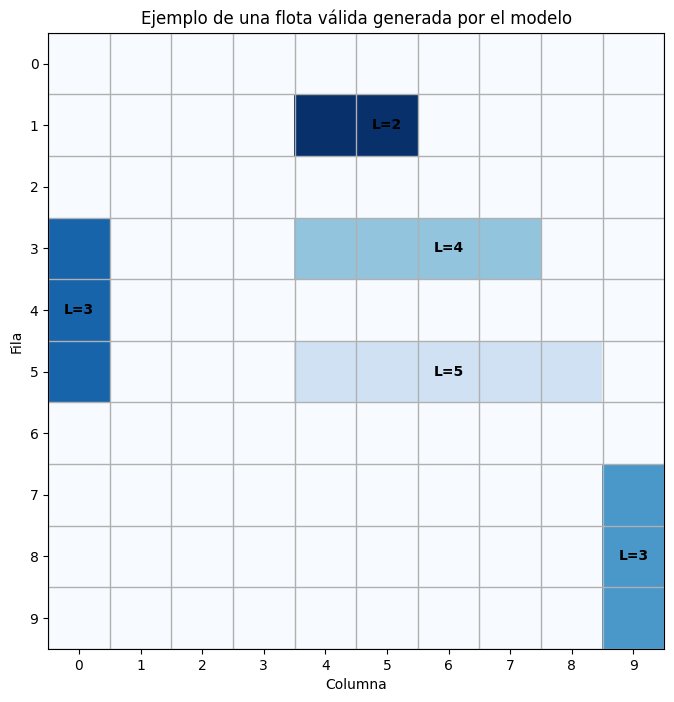

In [ ]:
# 4. 1 Inicialización del ejemplo: se reutilizan las funciones del modelo.
flota_ejemplo = generar_flota_valida()
tablero_ejemplo = crear_tablero()
for barco in flota_ejemplo:
    for fila, columna in barco["celdas"]:
        tablero_ejemplo[fila, columna] = barco["id_barco"] + 1

plt.figure(figsize=(8, 8))                                                     #Crea una figura cuadrada para conservar la proporción real del tablero.

plt.imshow(                                                                    #Representa el tablero generado sin modificar su contenido.
    tablero_ejemplo,
    cmap="Blues",
    vmin=0,
    vmax=len(FLOTA_ESTANDAR),
    interpolation="none",
    extent=(-0.5, TAMANO_TABLERO - 0.5, TAMANO_TABLERO - 0.5, -0.5)
)

plt.xticks(range(TAMANO_TABLERO))                                              #Ubica cada número de columna en el centro de su celda.
plt.yticks(range(TAMANO_TABLERO))                                              #Ubica cada número de fila en el centro de su celda.

plt.gca().set_xticks(                                                          #Define los límites verticales exactos entre las celdas.
    np.arange(-0.5, TAMANO_TABLERO, 1),
    minor=True
)

plt.gca().set_yticks(                                                          #Define los límites horizontales exactos entre las celdas.
    np.arange(-0.5, TAMANO_TABLERO, 1),
    minor=True
)

plt.grid(                                                                      #Dibuja únicamente las líneas que separan las celdas.
    which="minor",
    linewidth=1
)

plt.tick_params(                                                               #Oculta las marcas utilizadas exclusivamente para construir la cuadrícula.
    which="minor",
    bottom=False,
    left=False
)

plt.xlabel("Columna")                                                          #Identifica las columnas del tablero.
plt.ylabel("Fila")                                                             #Identifica las filas del tablero.
plt.title("Ejemplo de una flota válida generada por el modelo")                #Describe la configuración que se está mostrando.

for barco in flota_ejemplo:                                                    #Utiliza directamente los barcos producidos por generar_flota_valida().
    celdas_ordenadas = sorted(barco["celdas"])                                 #Ordena sus celdas únicamente para ubicar la etiqueta.
    fila, columna = celdas_ordenadas[len(celdas_ordenadas) // 2]               #Selecciona una de las celdas centrales del barco.

    plt.text(                                                                  #Muestra la longitud real del barco sobre la visualización.
        columna,
        fila,
        f"L={barco['longitud']}",
        ha="center",
        va="center",
        fontweight="bold"
    )

plt.xlim(-0.5, TAMANO_TABLERO - 0.5)                                          #Hace coincidir exactamente el ancho del gráfico con las diez columnas.
plt.ylim(TAMANO_TABLERO - 0.5, -0.5)                                          #Hace coincidir exactamente la altura del gráfico con las diez filas.
plt.gca().set_aspect("equal")                                                  #Garantiza que cada celda tenga exactamente el mismo ancho y alto.

plt.show()                                                                     #Muestra el tablero generado.

# 5. Conteo de encajes consistentes

En esta sección se implementa la estrategia principal propuesta en el proyecto: seleccionar el siguiente disparo a partir del número de configuraciones de barcos que siguen siendo compatibles con la información observada durante la partida.

Para cada longitud de barco $L$, se construye primero el conjunto $P_L$ de todos los encajes posibles dentro del tablero, considerando orientaciones horizontales y verticales.

A medida que avanza la partida, la información disponible permite descartar encajes incompatibles. De esta forma se obtiene el conjunto $P_{L,t}$, formado únicamente por las posiciones posibles de un barco de longitud $L$ que no contradicen el estado observable en el instante $t$.

A partir de estos encajes consistentes se construye el mapa de conteo $C_t(v)$, donde cada celda $v$ recibe una puntuación igual al número de encajes consistentes que la contienen, teniendo en cuenta todos los barcos que permanecen activos.

Finalmente, la estrategia selecciona como siguiente disparo una celda perteneciente a

$$
\operatorname*{arg\,max}_{v \notin D_t} C_t(v),
$$

donde $D_t$ representa el conjunto de celdas que ya han sido atacadas.

Si varias celdas alcanzan la misma puntuación máxima, se aplica la regla de desempate definida previamente. De esta manera, la política prioriza las posiciones que aparecen con mayor frecuencia entre las configuraciones todavía compatibles con la evidencia disponible.

In [ ]:
# ============================================================
# 5. CONTEO DE ENCAJES CONSISTENTES
# ============================================================


# ============================================================
# 5.1 GENERACIÓN DE ENCAJES POSIBLES P_L
# ============================================================

def generar_encajes(longitud, tamano_tablero=TAMANO_TABLERO):                  #Genera el conjunto P_L de encajes posibles para un barco de longitud L.
    encajes = []                                                               #Inicializa la lista que almacenará los encajes posibles.

    for fila in range(tamano_tablero):                                         #Recorre cada fila para construir los encajes horizontales.
        for columna_inicial in range(tamano_tablero - longitud + 1):           #Recorre las columnas donde el barco puede iniciar sin salir del tablero.
            celdas = {                                                         #Construye las L celdas consecutivas del encaje horizontal.
                (fila, columna_inicial + desplazamiento)
                for desplazamiento in range(longitud)
            }

            encajes.append({                                                   #Agrega el encaje horizontal al conjunto P_L.
                "orientacion": "H",                                            #Registra la orientación horizontal del encaje.
                "celdas": celdas                                               #Registra las celdas ocupadas por el encaje.
            })

    for columna in range(tamano_tablero):                                      #Recorre cada columna para construir los encajes verticales.
        for fila_inicial in range(tamano_tablero - longitud + 1):              #Recorre las filas donde el barco puede iniciar sin salir del tablero.
            celdas = {                                                         #Construye las L celdas consecutivas del encaje vertical.
                (fila_inicial + desplazamiento, columna)
                for desplazamiento in range(longitud)
            }

            encajes.append({                                                   #Agrega el encaje vertical al conjunto P_L.
                "orientacion": "V",                                            #Registra la orientación vertical del encaje.
                "celdas": celdas                                               #Registra las celdas ocupadas por el encaje.
            })

    return encajes                                                             #Devuelve todos los elementos del conjunto P_L.


ENCAJES_POR_LONGITUD = {                                                       #Precalcula P_L para cada longitud distinta presente en la flota.
    longitud: generar_encajes(longitud)                                        #Genera todos los encajes posibles para la longitud evaluada.
    for longitud in set(LONGITUDES_FLOTA)                                      #Recorre una sola vez cada longitud diferente de la flota.
}

# ============================================================
# 5.2 OBTENCIÓN DE ENCAJES CONSISTENTES
# ============================================================

def obtener_encajes_consistentes(longitud, M_t, A_t, S_t, encajes_por_longitud):    #Obtiene P_{L,t}, los encajes de longitud L compatibles con la evidencia observable.
    encajes_consistentes = []                                                       #Inicializa la lista que almacenará los encajes pertenecientes a P_{L,t}.

    for encaje in encajes_por_longitud[longitud]:                                  #Recorre todos los encajes pertenecientes al conjunto P_L.
        celdas_encaje = encaje["celdas"]                                            #Obtiene las celdas ocupadas por el encaje que está siendo evaluado.

        if not celdas_encaje.isdisjoint(M_t):                                       #Verifica si el encaje ocupa alguna celda conocida como agua.
            continue                                                                #Descarta el encaje porque contradice la evidencia contenida en M_t.

        if not celdas_encaje.isdisjoint(S_t):                                       #Verifica si el encaje ocupa alguna celda de un barco previamente hundido.
            continue                                                                #Descarta el encaje porque las celdas de S_t ya pertenecen a barcos retirados de R_t.

        if A_t and celdas_encaje.isdisjoint(A_t):                                   #Verifica si existen impactos activos y el encaje no explica ninguno de ellos.
            continue                                                                #Descarta el encaje porque no contiene ningún impacto activo observado.

        encajes_consistentes.append(encaje)                                         #Conserva el encaje porque no contradice la evidencia observable.

    return encajes_consistentes                                                     #Devuelve el conjunto P_{L,t} de encajes consistentes para la longitud L.

# ============================================================
# 5.3 CONSTRUCCIÓN DEL MAPA C_t(v)
# ============================================================

def construir_mapa_conteo(D_t, M_t, A_t, S_t, R_t, encajes_por_longitud, tamano_tablero=TAMANO_TABLERO):    #Construye el mapa C_t(v) mediante el conteo de encajes consistentes.
    C_t = np.zeros((tamano_tablero, tamano_tablero), dtype=int)                                           #Inicializa en cero la puntuación de cada celda del tablero.

    for longitud in R_t:                                                                                   #Recorre cada longitud restante conservando la multiplicidad del multiconjunto R_t.
        encajes_consistentes = obtener_encajes_consistentes(                                              #Obtiene el conjunto P_{L,t} compatible con la evidencia observable.
            longitud,
            M_t,
            A_t,
            S_t,
            encajes_por_longitud
        )

        for encaje in encajes_consistentes:                                                               #Recorre cada encaje consistente correspondiente a la longitud actual.
            celdas_encaje = encaje["celdas"]                                                              #Obtiene las celdas ocupadas por el encaje evaluado.

            for fila, columna in celdas_encaje:                                                           #Recorre cada celda contenida en el encaje consistente.
                celda = (fila, columna)                                                                    #Construye la coordenada de la celda evaluada.

                if celda in D_t:                                                                           #Verifica si la celda ya fue atacada anteriormente.
                    continue                                                                                #Evita asignar puntuación a una celda perteneciente a D_t.

                C_t[fila, columna] += 1                                                                    #Incrementa en uno el número de encajes consistentes que contienen la celda.

    return C_t                                                                                             #Devuelve el mapa de puntuaciones C_t(v).

# ============================================================
# 5.4 SELECCIÓN MIÓPEMENTE ÓPTIMA
# ============================================================

def seleccionar_disparo_conteo(D_t, M_t, A_t, S_t, R_t, encajes_por_longitud, tamano_tablero=TAMANO_TABLERO):    #Selecciona una celda perteneciente al argmax del mapa C_t(v).
    C_t = construir_mapa_conteo(                                                                                 #Construye el mapa de puntuaciones utilizando la evidencia observable.
        D_t,
        M_t,
        A_t,
        S_t,
        R_t,
        encajes_por_longitud,
        tamano_tablero
    )

    mejor_puntuacion = -1                                                                                        #Inicializa la mayor puntuación encontrada.
    mejores_celdas = []                                                                                          #Inicializa la lista de celdas que pertenecen al argmax de C_t(v).

    for fila in range(tamano_tablero):                                                                           #Recorre cada fila del tablero.
        for columna in range(tamano_tablero):                                                                    #Recorre cada columna del tablero.
            celda = (fila, columna)                                                                              #Construye la coordenada de la celda evaluada.

            if celda in D_t:                                                                                     #Verifica si la celda ya fue disparada anteriormente.
                continue                                                                                          #Descarta la celda porque no puede volver a ser seleccionada.

            puntuacion = C_t[fila, columna]                                                                      #Obtiene la puntuación C_t(v) de la celda actual.

            if puntuacion > mejor_puntuacion:                                                                    #Verifica si se encontró una puntuación superior a la máxima actual.
                mejor_puntuacion = puntuacion                                                                    #Actualiza el valor máximo encontrado.
                mejores_celdas = [celda]                                                                         #Reinicia el conjunto argmax con la nueva mejor celda.

            elif puntuacion == mejor_puntuacion:                                                                 #Verifica si la celda empata con la máxima puntuación actual.
                mejores_celdas.append(celda)                                                                     #Agrega la celda al conjunto de máximos.

    if not mejores_celdas:                                                                                       #Verifica si no quedan celdas disponibles para disparar.
        return None, C_t                                                                                          #Devuelve None cuando el tablero ya no contiene acciones posibles.

    if mejor_puntuacion == 0:                                                                                    #Verifica si ningún encaje consistente asigna puntuación positiva a las celdas disponibles.
        mejores_celdas = [                                                                                       #Construye una lista con todas las celdas todavía no disparadas.
            (fila, columna)
            for fila in range(tamano_tablero)
            for columna in range(tamano_tablero)
            if (fila, columna) not in D_t
        ]

    if REGLA_DESEMPATE == "aleatorio":                                                                           #Verifica si el experimento utiliza desempate aleatorio.
        a_t = random.choice(mejores_celdas)                                                                      #Selecciona aleatoriamente una celda perteneciente al argmax.

    else:                                                                                                        #Ejecuta el desempate determinista cuando no se utiliza selección aleatoria.
        a_t = min(mejores_celdas)                                                                                #Selecciona la primera celda según orden lexicográfico.

    return a_t, C_t                                                                                              #Devuelve la celda seleccionada y el mapa de conteo C_t(v).

### 5.5 Ejemplo del Conteo de Encajes Consistentes
# Sección nueva
El siguiente ejemplo utiliza directamente las funciones definidas anteriormente para mostrar cómo la evidencia disponible modifica los encajes posibles y conduce a la selección del siguiente disparo.

Se considera un estado intermedio de la partida con algunas celdas conocidas como agua y un impacto activo. A partir de esta información se obtienen los encajes consistentes, se construye el mapa $C_t(v)$ y se selecciona una celda perteneciente a su máximo.

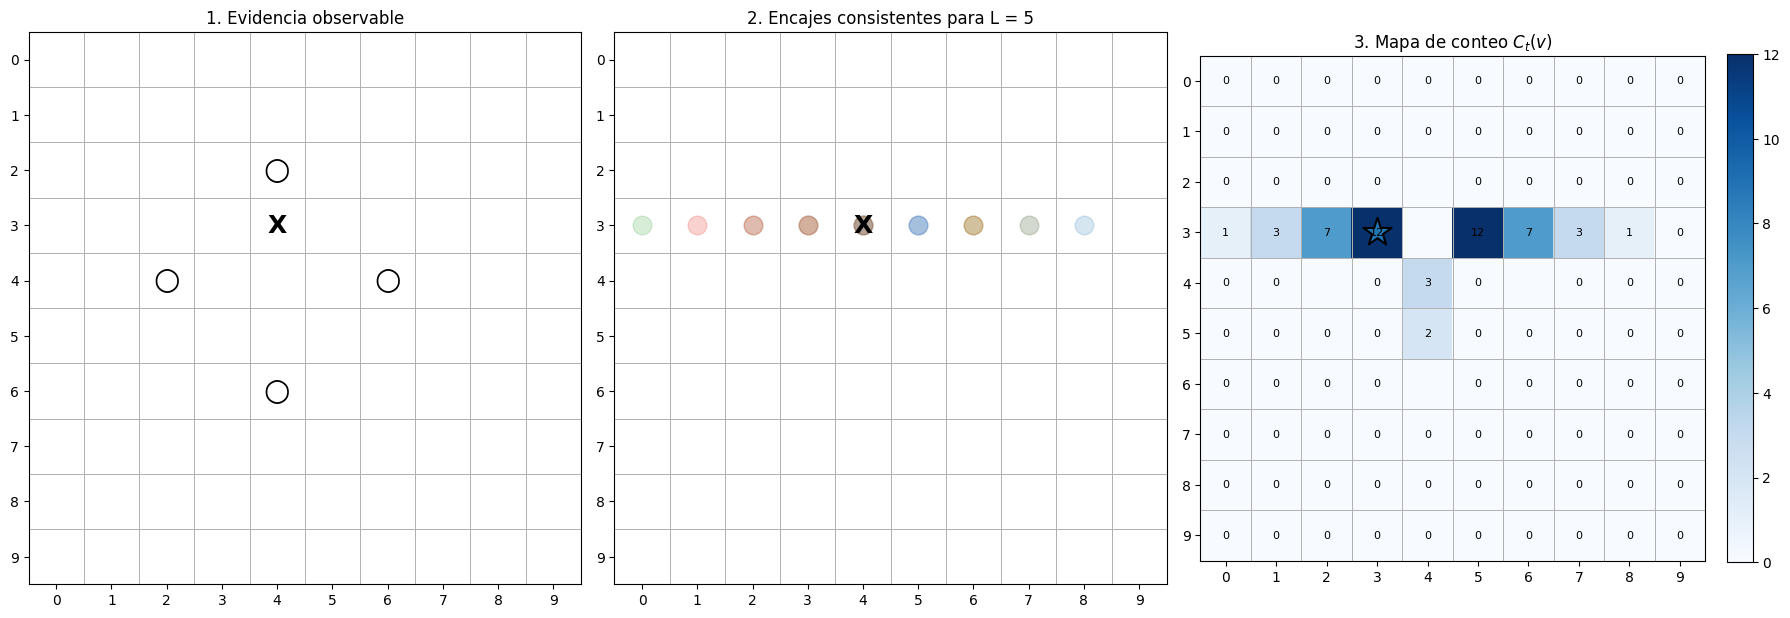

RESUMEN DEL EJEMPLO
───────────────────────────────────────────────────────
Encajes posibles para L = 5:      120
Encajes consistentes para L = 5:  5
Máxima puntuación C_t(v):         12
Celda seleccionada:               (3, 3)


In [ ]:
# ============================================================
# 5.5 EJEMPLO: CONTEO DE ENCAJES CONSISTENTES
# ============================================================

M_ejemplo = {(2, 4), (4, 2), (4, 6), (6, 4)}                                  #Define cuatro disparos conocidos como agua alrededor de la zona analizada.
A_ejemplo = {(3,4)}                                                          #Define una celda conocida como impacto activo.
S_ejemplo = set()                                                             #Indica que todavía no existen barcos hundidos en este ejemplo.
D_ejemplo = M_ejemplo | A_ejemplo                                             #Construye el conjunto de todas las celdas disparadas hasta el momento.
R_ejemplo = FLOTA_ESTANDAR.copy()                                             #Mantiene los cinco barcos como longitudes todavía pendientes de hundir.


encajes_L5_totales = ENCAJES_POR_LONGITUD[5]                                  #Obtiene directamente todos los encajes posibles P_5 precalculados por el modelo.

encajes_L5_consistentes = obtener_encajes_consistentes(                       #Aplica la evidencia observable para obtener únicamente los encajes consistentes.
    5,
    M_ejemplo,
    A_ejemplo,
    S_ejemplo,
    ENCAJES_POR_LONGITUD
)


C_ejemplo = construir_mapa_conteo(                                            #Construye el mapa C_t(v) utilizando exactamente el algoritmo definido anteriormente.
    D_ejemplo,
    M_ejemplo,
    A_ejemplo,
    S_ejemplo,
    R_ejemplo,
    ENCAJES_POR_LONGITUD
)


disparo_ejemplo, _ = seleccionar_disparo_conteo(                              #Utiliza la política de Conteo para seleccionar el siguiente disparo.
    D_ejemplo,
    M_ejemplo,
    A_ejemplo,
    S_ejemplo,
    R_ejemplo,
    ENCAJES_POR_LONGITUD
)


fig, axes = plt.subplots(1, 3, figsize=(18, 6))                                #Crea tres paneles para mostrar las etapas principales del algoritmo.


axes[0].set_xlim(-0.5, TAMANO_TABLERO - 0.5)                                  #Establece los límites horizontales del tablero de evidencia.
axes[0].set_ylim(TAMANO_TABLERO - 0.5, -0.5)                                  #Establece los límites verticales conservando la orientación matricial.
axes[0].set_xticks(range(TAMANO_TABLERO))                                      #Muestra las coordenadas correspondientes a las columnas.
axes[0].set_yticks(range(TAMANO_TABLERO))                                      #Muestra las coordenadas correspondientes a las filas.
axes[0].set_xticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)             #Define los límites verticales de cada celda.
axes[0].set_yticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)             #Define los límites horizontales de cada celda.
axes[0].grid(which="minor", linewidth=0.7)                                     #Dibuja la cuadrícula del tablero.
axes[0].tick_params(which="minor", bottom=False, left=False)                   #Oculta las marcas auxiliares utilizadas para construir la cuadrícula.
axes[0].set_aspect("equal")                                                    #Mantiene todas las celdas con forma cuadrada.
axes[0].set_title("1. Evidencia observable")                                   #Identifica la información disponible antes de calcular los encajes.


for fila, columna in M_ejemplo:                                                #Recorre las celdas conocidas como agua.
    axes[0].text(columna, fila, "○", ha="center", va="center", fontsize=22)    #Representa cada fallo mediante un círculo.


for fila, columna in A_ejemplo:                                                #Recorre las celdas correspondientes a impactos activos.
    axes[0].text(columna, fila, "X", ha="center", va="center", fontsize=18, fontweight="bold") #Representa cada impacto activo mediante una X.


axes[1].set_xlim(-0.5, TAMANO_TABLERO - 0.5)                                  #Establece los límites horizontales del tablero de encajes.
axes[1].set_ylim(TAMANO_TABLERO - 0.5, -0.5)                                  #Establece los límites verticales del tablero de encajes.
axes[1].set_xticks(range(TAMANO_TABLERO))                                      #Muestra las coordenadas de las columnas.
axes[1].set_yticks(range(TAMANO_TABLERO))                                      #Muestra las coordenadas de las filas.
axes[1].set_xticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)             #Define los límites verticales de las celdas.
axes[1].set_yticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)             #Define los límites horizontales de las celdas.
axes[1].grid(which="minor", linewidth=0.7)                                     #Dibuja la cuadrícula utilizada para observar los encajes.
axes[1].tick_params(which="minor", bottom=False, left=False)                   #Oculta las marcas auxiliares de la cuadrícula.
axes[1].set_aspect("equal")                                                    #Mantiene las celdas con proporciones iguales.
axes[1].set_title("2. Encajes consistentes para L = 5")                        #Identifica los encajes que sobreviven a la evidencia.


for encaje in encajes_L5_consistentes:                                        #Recorre únicamente los encajes conservados por obtener_encajes_consistentes().
    for fila, columna in encaje["celdas"]:                                    #Recorre las cinco celdas pertenecientes a cada encaje consistente.
        axes[1].scatter(columna, fila, s=180, alpha=0.18)                      #Superpone los encajes para mostrar dónde se concentran las posibilidades.


for fila, columna in A_ejemplo:                                                #Recorre nuevamente los impactos activos del ejemplo.
    axes[1].text(columna, fila, "X", ha="center", va="center", fontsize=18, fontweight="bold") #Marca el impacto que restringe los encajes posibles.


imagen_conteo = axes[2].imshow(                                                #Representa directamente el mapa C_t(v) producido por el algoritmo.
    C_ejemplo,
    cmap="Blues",
    interpolation="none",
    extent=(-0.5, TAMANO_TABLERO - 0.5, TAMANO_TABLERO - 0.5, -0.5)
)

axes[2].set_xticks(range(TAMANO_TABLERO))                                      #Muestra las coordenadas correspondientes a las columnas.
axes[2].set_yticks(range(TAMANO_TABLERO))                                      #Muestra las coordenadas correspondientes a las filas.
axes[2].set_xticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)             #Define los límites verticales exactos de las celdas.
axes[2].set_yticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)             #Define los límites horizontales exactos de las celdas.
axes[2].grid(which="minor", linewidth=0.7)                                     #Dibuja la cuadrícula sobre el mapa de conteo.
axes[2].tick_params(which="minor", bottom=False, left=False)                   #Oculta las marcas auxiliares de la cuadrícula.
axes[2].set_aspect("equal")                                                    #Mantiene las cien celdas con las mismas dimensiones.
axes[2].set_title("3. Mapa de conteo $C_t(v)$")                               #Identifica el resultado del conteo de encajes consistentes.


for fila in range(TAMANO_TABLERO):                                             #Recorre todas las filas del mapa de conteo.
    for columna in range(TAMANO_TABLERO):                                      #Recorre todas las columnas del mapa de conteo.
        if (fila, columna) not in D_ejemplo:                                   #Evita mostrar puntuaciones en celdas que ya fueron disparadas.
            axes[2].text(columna, fila, C_ejemplo[fila, columna], ha="center", va="center", fontsize=8) #Muestra el valor C_t(v) calculado para la celda.


fila_disparo, columna_disparo = disparo_ejemplo                                #Separa las coordenadas de la acción elegida por la estrategia.

axes[2].scatter(                                                               #Destaca sobre el mapa la celda seleccionada por la política.
    columna_disparo,
    fila_disparo,
    marker="*",
    s=450,
    edgecolors="black",
    linewidths=1.5
)


plt.colorbar(imagen_conteo, ax=axes[2], fraction=0.046, pad=0.04)              #Añade una escala para interpretar la intensidad del mapa de conteo.
plt.tight_layout()                                                            #Ajusta automáticamente el espacio disponible entre los tres paneles.
plt.show()                                                                     #Muestra el proceso completo del ejemplo.


print("RESUMEN DEL EJEMPLO")                                                   #Presenta numéricamente los elementos principales de la demostración.
print("─" * 55)                                                               #Separa visualmente el encabezado de los resultados.
print(f"Encajes posibles para L = 5:      {len(encajes_L5_totales)}")          #Muestra el tamaño del conjunto P_5 antes de considerar la evidencia.
print(f"Encajes consistentes para L = 5:  {len(encajes_L5_consistentes)}")     #Muestra cuántos encajes sobreviven después de aplicar la evidencia.
print(f"Máxima puntuación C_t(v):         {C_ejemplo.max()}")                  #Muestra la puntuación máxima obtenida en el mapa.
print(f"Celda seleccionada:               {disparo_ejemplo}")                  #Muestra la acción elegida por seleccionar_disparo_conteo().

# 6. Distribución posterior uniforme sobre $X_t$

En esta sección se modela la incertidumbre sobre las posibles configuraciones completas de la flota que permanecen compatibles con la evidencia observada durante la partida.

Sea $X_t$ el conjunto de colocaciones válidas que no contradicen la información disponible en el instante $t$. Bajo el supuesto de una distribución uniforme sobre dicho conjunto, todas las configuraciones consistentes reciben el mismo peso posterior.

La distribución se define como

$$
p_t(x)=\frac{1}{|X_t|}
$$

para toda colocación $x \in X_t$.

Por tanto, el procedimiento requiere primero determinar el tamaño de $X_t$ y posteriormente asignar a cada configuración consistente una probabilidad igual a $1/|X_t|$.

Esta representación permite formular una distribución posterior explícita sobre los estados posibles de la flota y constituye la base para calcular probabilidades de ocupación de las celdas cuando se trabaja con la enumeración completa de configuraciones consistentes.

In [ ]:
# ============================================================
# 6. DISTRIBUCIÓN POSTERIOR UNIFORME p_t(x)
# ============================================================

def contar_colocaciones_consistentes(M_t, A_t, S_t):
    """
    Calcula |X_t|, es decir, el número de colocaciones
    válidas consistentes con la evidencia observada.
    """
    return sum(
        1
        for _ in iterar_colocaciones_consistentes(M_t, A_t, S_t)
    )


def calcular_peso_posterior(n_X_t):
    """
    Implementa:
        p_t(x) = 1 / |X_t|

    para toda colocación x perteneciente a X_t.
    """
    if n_X_t == 0:
        raise ValueError(
            "La evidencia observada produce un conjunto X_t vacío."
        )

    return 1.0 / n_X_t

## 7. Mapa bayesiano de ocupación $H_t(v)$

En esta sección se calcula, para cada celda aún no atacada, la probabilidad posterior de estar ocupada por al menos un barco dada la evidencia disponible en el instante $t$.

A partir del conjunto $X_t$ de colocaciones completas consistentes, se recorre cada configuración posible y se contabiliza cuántas veces aparece ocupada cada celda del tablero. Si $|X_t|$ representa el número total de configuraciones consistentes, entonces para una celda $v$ se define

$$
H_t(v)=\frac{\#\{x\in X_t:\ v\text{ está ocupada en }x\}}{|X_t|}.
$$

De esta forma, $H_t(v)$ puede interpretarse como la probabilidad posterior de ocupación de la celda $v$ bajo el supuesto de una distribución uniforme sobre $X_t$.

El mapa resultante resume la información contenida en todas las configuraciones compatibles con la evidencia observada y permite identificar las celdas con mayor probabilidad posterior de contener parte de un barco.

In [ ]:
# ============================================================
# 7.MAPA BAYESIANO DE OCUPACIÓN H_t(v)
# ============================================================

def construir_mapa_posterior(M_t, A_t, S_t, D_t):
    conteos = {(f, c): 0 for f in range(TAMANO_TABLERO)
                         for c in range(TAMANO_TABLERO)
                         if (f, c) not in D_t}

    n_X_t = 0

    for x in iterar_colocaciones_consistentes(M_t, A_t, S_t):
        n_X_t += 1
        ocupadas = obtener_ocupadas(x)

        for v in conteos:
            if v in ocupadas:
                conteos[v] += 1

    if n_X_t == 0:
        raise ValueError("La evidencia observada produce un conjunto X_t vacío.")

    H_t = {
        v: conteos[v] / n_X_t
        for v in conteos
    }

    return H_t, n_X_t

## 8. Política bayesiana miope basada en $H_t(v)$

En esta sección se define la política de decisión asociada al mapa posterior de ocupación $H_t(v)$.

La estrategia selecciona, entre todas las celdas que aún no han sido atacadas, aquella con mayor probabilidad posterior de estar ocupada por algún barco. Por tanto, la acción elegida en el instante $t$ se define como

$$
a_t \in \operatorname*{arg\,max}_{v \notin D_t} H_t(v).
$$

Esta política es miope porque toma la decisión utilizando únicamente la probabilidad inmediata de éxito del siguiente disparo, sin considerar de manera explícita el efecto que ese disparo podría tener sobre decisiones futuras.

Cuando varias celdas alcanzan la misma probabilidad máxima, el procedimiento aplica una regla de desempate determinista mediante orden lexicográfico.

La función devuelve la celda seleccionada, el mapa posterior completo $H_t(v)$ y el número de configuraciones consistentes $|X_t|$ utilizadas en el cálculo.

In [ ]:
# ============================================================
# 8. POLÍTICA BAYESIANA MIOPE BASADA EN $H_t(v)$
# ============================================================

def seleccionar_disparo_bayesiano(M_t, A_t, S_t, D_t):
    H_t, n_X_t = construir_mapa_posterior(M_t, A_t, S_t, D_t)

    maximo = max(H_t.values())

    mejores_celdas = [
        v for v, probabilidad in H_t.items()
        if probabilidad == maximo
    ]

    # Desempate determinista: orden lexicográfico
    a_t = min(mejores_celdas)

    return a_t, H_t, n_X_t

## 9. Estado observable y dinámica de la partida

En esta sección se define cómo se representa y actualiza la información disponible para las estrategias durante una partida.

El estado observable en el instante $t$ se describe mediante cinco componentes:

- $D_t$: conjunto de celdas que ya han recibido un disparo.
- $M_t$: conjunto de celdas conocidas como agua.
- $A_t$: conjunto de impactos activos correspondientes a barcos que todavía no han sido hundidos.
- $S_t$: conjunto de celdas pertenecientes a barcos ya hundidos.
- $R_t$: multiconjunto de longitudes de los barcos que permanecen activos.

A partir de esta representación se implementa la dinámica de cada disparo. Cuando se selecciona una celda, el motor consulta la configuración real de la flota y actualiza el estado observable según el resultado obtenido.

Si el disparo no impacta ningún barco, la celda se incorpora a $M_t$. Si impacta un barco que todavía permanece activo, la celda se agrega a $A_t$. Cuando todas las celdas de un barco han sido atacadas, sus posiciones se trasladan de $A_t$ a $S_t$ y se elimina una ocurrencia de su longitud en $R_t$.

La partida finaliza cuando $R_t$ queda vacío, es decir, cuando todos los barcos han sido hundidos.


In [ ]:

# ============================================================
# 9. ESTADO OBSERVABLE DE LA PARTIDA
# ============================================================

def crear_estado_partida():                                                     #Crea el estado observable inicial de una partida.
    estado_partida = {}                                                         #Inicializa el diccionario que almacenará el estado de la partida.
    estado_partida["D_t"] = set()                                               #D_t contiene todas las celdas disparadas hasta el turno t.
    estado_partida["M_t"] = set()                                               #M_t contiene las celdas cuyo resultado observado fue agua.
    estado_partida["A_t"] = set()                                               #A_t contiene los impactos activos de barcos todavía no hundidos.
    estado_partida["S_t"] = set()                                               #S_t contiene las celdas pertenecientes a barcos ya hundidos.
    estado_partida["R_t"] = list(FLOTA_ESTANDAR)                                #R_t contiene las longitudes de los barcos que permanecen sin hundir.
    return estado_partida                                                       #Devuelve el estado observable inicial de la partida.



def buscar_barco_en_celda(celda, flota):                                      #Busca el barco de la flota real que ocupa una celda determinada.
    for indice_barco, barco in enumerate(flota):                              #Recorre todos los barcos de la configuración verdadera.
        if celda in barco["celdas"]:                                          #Verifica si la celda pertenece al barco evaluado.
            return indice_barco, barco                                        #Devuelve el índice y la información del barco encontrado.

    return None, None                                                         #Devuelve None si la celda no pertenece a ningún barco.

def barco_hundido(barco, D_t):                                                #Determina si todas las celdas de un barco ya fueron disparadas.
    return barco["celdas"].issubset(D_t)                                      #Devuelve True cuando todas las celdas del barco pertenecen a D_t.


def disparar(celda, flota, estado_partida):                                   #Ejecuta un disparo sobre la flota real y actualiza el estado observable.
    D_t = estado_partida["D_t"]                                               #Obtiene el conjunto de disparos realizados.
    M_t = estado_partida["M_t"]                                               #Obtiene el conjunto de celdas observadas como agua.
    A_t = estado_partida["A_t"]                                               #Obtiene el conjunto de impactos activos.
    S_t = estado_partida["S_t"]                                               #Obtiene el conjunto de celdas de barcos hundidos.
    R_t = estado_partida["R_t"]                                               #Obtiene el multiconjunto de longitudes restantes.

    if celda in D_t:                                                          #Verifica si la celda ya fue disparada anteriormente.
        raise ValueError("La celda ya fue disparada.")                        #Evita repetir disparos sobre una misma posición.

    D_t.add(celda)                                                            #Agrega la celda seleccionada al conjunto D_t.

    indice_barco, barco = buscar_barco_en_celda(celda, flota)                 #Consulta en la flota real si la celda pertenece a algún barco.

    if barco is None:                                                         #Verifica si el disparo no impactó ningún barco.
        M_t.add(celda)                                                        #Agrega la celda al conjunto de observaciones de agua M_t.
        return "agua"                                                         #Devuelve el resultado observable del disparo.

    A_t.add(celda)                                                            #Registra la celda como impacto activo.

    if barco_hundido(barco, D_t):                                             #Verifica si el impacto completó el hundimiento del barco.
        for celda_barco in barco["celdas"]:                                   #Recorre todas las celdas del barco recién hundido.
            A_t.discard(celda_barco)                                          #Elimina sus celdas del conjunto de impactos activos.
            S_t.add(celda_barco)                                              #Agrega sus celdas al conjunto de barcos hundidos S_t.

        longitud_barco = barco["longitud"]                                    #Obtiene la longitud del barco que acaba de hundirse.

        if longitud_barco in R_t:                                             #Verifica que la longitud permanezca registrada en R_t.
            R_t.remove(longitud_barco)                                        #Elimina una sola ocurrencia de la longitud hundida.

        return "hundido"                                                      #Devuelve el resultado observable de hundimiento.

    return "tocado"                                                           #Devuelve tocado cuando el barco fue impactado pero sigue activo.


def todos_los_barcos_hundidos(estado_partida):                                #Determina si ya no quedan barcos activos en la partida.
    return len(estado_partida["R_t"]) == 0                                     #Devuelve True cuando el multiconjunto R_t está vacío.

def obtener_impactos_activos(estado_partida):                                 #Obtiene las celdas que continúan asociadas a barcos no hundidos.
    return set(estado_partida["A_t"])                                          #Devuelve una copia del conjunto de impactos activos A_t.


In [ ]:

# ============================================================
# 9.1 Ejemplo del estado observable de la parida.
# ============================================================
N_DEMO = 5                                                                       #Define un tablero de cinco filas y cinco columnas.
FLOTA_DEMO = [3, 2, 2]                                                           #Define tres barcos con longitudes de tres, dos y dos casillas.

def generar_flota_demo():                                                        #Define la función encargada de generar una flota válida para el tablero.
    barcos = []                                                                  #Inicializa la lista que almacenará los barcos generados.
    ocupadas = set()                                                             #Inicializa el conjunto de casillas ocupadas por los barcos colocados.

    for longitud in FLOTA_DEMO:                                                  #Recorre las longitudes de los barcos que deben ubicarse en el tablero.
        opciones = []                                                            #Inicializa la lista de encajes posibles para el barco actual.

        for fila in range(N_DEMO):                                               #Recorre las filas del tablero.
            for columna in range(N_DEMO):                                        #Recorre las columnas del tablero.

                if columna + longitud <= N_DEMO:                                 #Verifica que el barco pueda colocarse horizontalmente sin salir del tablero.
                    celdas = {                                                   #Construye el conjunto de casillas del encaje horizontal.
                        (fila, columna + k)
                        for k in range(longitud)
                    }

                    if not (celdas & ocupadas):                                   #Comprueba que el encaje no se superponga con barcos previamente ubicados.
                        opciones.append(celdas)                                  #Agrega el encaje horizontal a las opciones válidas.

                if fila + longitud <= N_DEMO:                                    #Verifica que el barco pueda colocarse verticalmente sin salir del tablero.
                    celdas = {                                                   #Construye el conjunto de casillas del encaje vertical.
                        (fila + k, columna)
                        for k in range(longitud)
                    }

                    if not (celdas & ocupadas):                                   #Comprueba que el encaje vertical no se superponga con barcos existentes.
                        opciones.append(celdas)                                  #Agrega el encaje vertical a las opciones válidas.

        if not opciones:                                                         #Comprueba si no existen posiciones disponibles para el barco actual.
            return generar_flota_demo()                                          #Reinicia la generación cuando no puede completarse válidamente.

        barco = random.choice(opciones)                                          #Selecciona aleatoriamente uno de los encajes válidos disponibles.
        barcos.append(barco)                                                     #Incorpora el barco seleccionado a la flota oculta.
        ocupadas.update(barco)                                                   #Actualiza el conjunto de casillas ocupadas.

    return barcos                                                                #Devuelve la flota completa sin superposición entre barcos.

def crear_estado_demo():                                                         #Define la función que inicializa el estado observable de una nueva partida.
    return {
        "t": 0,                                                                   #Establece el turno inicial de la partida en cero.
        "D_t": set(),                                                             #Inicializa vacío el conjunto de casillas donde se han realizado disparos.
        "M_t": set(),                                                             #Inicializa vacío el conjunto de disparos que resultaron en agua.
        "A_t": set(),                                                             #Inicializa vacío el conjunto de impactos activos sobre barcos no hundidos.
        "S_t": set(),                                                             #Inicializa vacío el conjunto de impactos pertenecientes a barcos hundidos.
        "flota_oculta": generar_flota_demo()                                      #Genera la configuración real de barcos que permanecerá oculta al jugador.
    }

estado_demo = crear_estado_demo()                                                #Construye el estado inicial de la demostración en el turno cero.

titulo_demo = widgets.HTML()                                                     #Crea el componente que mostrará el título y el turno actual.
mensaje_demo = widgets.HTML()                                                    #Crea el componente que mostrará el resultado de cada disparo.
estadisticas_demo = widgets.HTML()                                               #Crea el componente que mostrará las cantidades de elementos de cada conjunto.
conjuntos_demo = widgets.HTML()                                                  #Crea el componente que mostrará los conjuntos matemáticos completos.
salida_demo = widgets.Output()                                                   #Crea un área de salida para la interfaz interactiva.
botones_demo = {}                                                                #Inicializa el diccionario que relacionará cada casilla con su botón visual.

def formatear_conjunto(conjunto):                                                #Define la función que convierte un conjunto de coordenadas en texto legible.
    if not conjunto:                                                             #Comprueba si el conjunto recibido está vacío.
        return "∅"                                                               #Representa el conjunto vacío mediante el símbolo matemático correspondiente.

    return "{" + ", ".join(                                                       #Construye una representación textual de las coordenadas del conjunto.
        str(celda) for celda in sorted(conjunto)
    ) + "}"

def actualizar_visualizacion_demo():                                             #Define la función que actualiza el tablero y los conjuntos después de cada disparo.
    D = estado_demo["D_t"]                                                        #Obtiene el conjunto actual de todas las casillas disparadas.
    M = estado_demo["M_t"]                                                        #Obtiene el conjunto actual de disparos que dieron agua.
    A = estado_demo["A_t"]                                                        #Obtiene el conjunto actual de impactos activos.
    S = estado_demo["S_t"]                                                        #Obtiene el conjunto actual de impactos de barcos hundidos.

    titulo_demo.value = f"""                                                      #Actualiza el encabezado de la demostración con el número de turno.
    <h3>Batalla Naval 5 × 5 — Turno {estado_demo['t']}</h3>
    <p>Flota oculta: barcos de longitudes 3, 2 y 2.</p>
    """

    for celda, boton in botones_demo.items():                                    #Recorre todas las casillas y sus respectivos botones interactivos.
        if celda in M:                                                           #Verifica si la casilla corresponde a un disparo que dio agua.
            boton.description = "○"                                              #Representa visualmente el resultado de agua mediante un círculo.
            boton.button_style = "info"                                          #Aplica el estilo visual azul a la casilla de agua.
            boton.disabled = True                                                #Impide volver a disparar sobre la misma casilla.

        elif celda in A:                                                         #Verifica si la casilla corresponde a un impacto activo.
            boton.description = "X"                                              #Representa el impacto activo mediante una X.
            boton.button_style = "danger"                                        #Aplica el estilo visual rojo a la casilla impactada.
            boton.disabled = True                                                #Impide repetir el disparo sobre la casilla impactada.

        elif celda in S:                                                         #Verifica si la casilla pertenece a un barco que ya fue hundido.
            boton.description = "✓"                                              #Representa el impacto de un barco hundido mediante una marca de verificación.
            boton.button_style = "success"                                       #Aplica el estilo visual verde a la casilla del barco hundido.
            boton.disabled = True                                                #Impide volver a disparar sobre una casilla ya descubierta.

        else:                                                                    #Identifica las casillas que todavía no han recibido disparos.
            boton.description = "+"                                              #Representa las casillas desconocidas mediante el símbolo positivo.
            boton.button_style = ""                                              #Mantiene el estilo visual neutro para las casillas no exploradas.
            boton.disabled = False                                               #Permite seleccionar las casillas que aún no han sido disparadas.

    estadisticas_demo.value = f"""                                                #Construye el panel visual que muestra las cardinalidades de los conjuntos.
    <div style="
        display:grid;
        grid-template-columns:1fr 1fr;
        gap:10px;
        max-width:400px;
        margin-top:15px;
    ">

        <div style="padding:12px;background:#eeeeee;border-radius:8px;color:#222;">
            <b>Dₜ — Disparos</b><br>
            <span style="font-size:24px;">{len(D)}</span>
        </div>

        <div style="padding:12px;background:#eeeeee;border-radius:8px;color:#222;">
            <b>Mₜ — Agua</b><br>
            <span style="font-size:24px;">{len(M)}</span>
        </div>

        <div style="padding:12px;background:#eeeeee;border-radius:8px;color:#222;">
            <b>Aₜ — Impactos activos</b><br>
            <span style="font-size:24px;">{len(A)}</span>
        </div>

        <div style="padding:12px;background:#eeeeee;border-radius:8px;color:#222;">
            <b>Sₜ — Barcos hundidos</b><br>
            <span style="font-size:24px;">{len(S)}</span>
        </div>

    </div>
    """

    conjuntos_demo.value = f"""                                                  #Construye el panel que muestra las coordenadas almacenadas en cada conjunto.
    <div style="
        margin-top:15px;
        padding:12px;
        background:#f5f5f5;
        color:#222;
        border-radius:8px;
        max-width:650px;
        overflow-wrap:anywhere;
    ">

        <b>Estado observable del turno {estado_demo['t']}</b>

        <p><b>Dₜ:</b> {formatear_conjunto(D)}</p>
        <p><b>Mₜ:</b> {formatear_conjunto(M)}</p>
        <p><b>Aₜ:</b> {formatear_conjunto(A)}</p>
        <p><b>Sₜ:</b> {formatear_conjunto(S)}</p>

        <hr>

        <b>Verificación:</b><br>
        Dₜ = Mₜ ∪ Aₜ ∪ Sₜ :
        {D == (M | A | S)}

    </div>
    """

def procesar_disparo_demo(celda):                                                #Define la función que procesa el resultado de un disparo sobre una casilla.
    D = estado_demo["D_t"]                                                        #Obtiene el conjunto de casillas disparadas.
    M = estado_demo["M_t"]                                                        #Obtiene el conjunto de resultados de agua.
    A = estado_demo["A_t"]                                                        #Obtiene el conjunto de impactos activos.
    S = estado_demo["S_t"]                                                        #Obtiene el conjunto de impactos de barcos hundidos.

    if celda in D:                                                               #Comprueba si la casilla ya fue disparada anteriormente.
        return                                                                  #Finaliza la operación para evitar repetir un disparo.

    estado_demo["t"] += 1                                                        #Incrementa en una unidad el contador de turnos.
    D.add(celda)                                                                 #Agrega la casilla seleccionada al conjunto de disparos realizados.

    barco_impactado = None                                                       #Inicializa la variable que almacenará el barco alcanzado, si existe.

    for barco in estado_demo["flota_oculta"]:                                    #Recorre los barcos que forman la configuración real oculta.
        if celda in barco:                                                       #Comprueba si la casilla seleccionada pertenece al barco examinado.
            barco_impactado = barco                                              #Registra el barco alcanzado por el disparo.
            break                                                                #Detiene la búsqueda al encontrar el barco impactado.

    if barco_impactado is None:                                                  #Determina si el disparo no alcanzó ningún barco.
        M.add(celda)                                                             #Agrega la casilla al conjunto M_t de disparos que dieron agua.

        mensaje = (                                                              #Construye el mensaje que informa el resultado del disparo.
            f"Turno {estado_demo['t']}: "
            f"Disparo en {celda} → AGUA."
        )

    else:                                                                        #Procesa el caso en el que el disparo alcanzó un barco.
        A.add(celda)                                                             #Agrega inicialmente la casilla al conjunto A_t de impactos activos.

        if barco_impactado.issubset(D):                                          #Verifica si todas las casillas del barco alcanzado ya fueron disparadas.
            A.difference_update(barco_impactado)                                 #Retira de A_t todas las casillas correspondientes al barco recién hundido.
            S.update(barco_impactado)                                            #Incorpora a S_t las casillas del barco que acaba de hundirse.

            mensaje = (                                                          #Construye el mensaje que informa el hundimiento del barco.
                f"Turno {estado_demo['t']}: "
                f"Disparo en {celda} → "
                f"¡BARCO HUNDIDO de longitud "
                f"{len(barco_impactado)}!"
            )

        else:                                                                    #Procesa el caso en el que el barco recibió un impacto pero todavía no está hundido.
            mensaje = (                                                          #Construye el mensaje que informa que el disparo fue un impacto activo.
                f"Turno {estado_demo['t']}: "
                f"Disparo en {celda} → TOCADO."
            )

    mensaje_demo.value = f"""                                                     #Actualiza el panel visual con el resultado del disparo realizado.
    <div style="
        margin-top:10px;
        padding:10px;
        border-radius:8px;
        background:#e8f0fe;
        color:#222;
    ">
        <b>{mensaje}</b>
    </div>
    """

    actualizar_visualizacion_demo()                                              #Actualiza el tablero y las representaciones de los conjuntos observables.

    todas_ocupadas = set().union(                                                #Construye el conjunto de todas las casillas ocupadas por la flota real.
        *estado_demo["flota_oculta"]
    )

    if S == todas_ocupadas:                                                      #Comprueba si todas las casillas de la flota pertenecen al conjunto de hundidos.
        mensaje_demo.value += f"""                                                #Agrega un mensaje de victoria cuando se han hundido todos los barcos.
        <h3 style="color:green;">
            ¡Felicidades! Hundiste toda la flota
            en {estado_demo['t']} disparos.
        </h3>
        """

        for boton in botones_demo.values():                                      #Recorre todos los botones del tablero después de finalizar la partida.
            boton.disabled = True                                                #Deshabilita los disparos una vez que toda la flota ha sido hundida.

def crear_tablero_demo():                                                        #Define la función que construye visualmente la cuadrícula interactiva.
    botones_demo.clear()                                                         #Elimina las referencias anteriores a botones para crear el tablero.
    filas_widgets = []                                                           #Inicializa la lista que almacenará las filas visuales del tablero.

    for fila in range(N_DEMO):                                                   #Recorre las cinco filas que componen el tablero.
        botones_fila = []                                                        #Inicializa la lista de botones correspondientes a la fila actual.

        for columna in range(N_DEMO):                                            #Recorre las cinco columnas de la fila actual.
            celda = (fila, columna)                                              #Construye la coordenada de la casilla en formato fila y columna.

            boton = widgets.Button(                                              #Crea un botón interactivo que representa la casilla del tablero.
                description="+",
                layout=widgets.Layout(
                    width="55px",
                    height="55px"
                )
            )

            def al_hacer_clic(b, posicion=celda):                                #Define la acción que se ejecutará cuando el usuario seleccione una casilla.
                procesar_disparo_demo(posicion)                                   #Procesa el disparo utilizando las coordenadas asociadas al botón.

            boton.on_click(al_hacer_clic)                                         #Asocia el evento de selección del botón con la función de disparo.
            botones_demo[celda] = boton                                          #Relaciona la coordenada con su botón dentro del diccionario.
            botones_fila.append(boton)                                           #Incorpora el botón a la fila visual correspondiente.

        filas_widgets.append(                                                    #Incorpora la fila completa de botones al tablero interactivo.
            widgets.HBox(
                botones_fila,
                layout=widgets.Layout(gap="3px")
            )
        )

    return widgets.VBox(                                                         #Devuelve la cuadrícula formada por las filas de botones.
        filas_widgets,
        layout=widgets.Layout(gap="3px")
    )

tablero_demo = crear_tablero_demo()                                              #Construye el tablero interactivo de cinco por cinco.

boton_reiniciar_demo = widgets.Button(                                           #Crea el botón que permitirá iniciar una nueva partida.
    description="Reiniciar partida",
    button_style="warning",
    icon="refresh"
)

def reiniciar_partida_demo(b):                                                   #Define la función que restablece el tablero y los conjuntos al turno cero.
    global estado_demo                                                          #Permite reemplazar el estado global utilizado por la demostración.
    estado_demo = crear_estado_demo()                                            #Genera una nueva flota oculta y reinicializa los conjuntos observables.

    mensaje_demo.value = """                                                     #Muestra un mensaje indicando que la partida ha sido reiniciada.
    <p>Partida reiniciada. Turno cero.</p>
    """

    actualizar_visualizacion_demo()                                              #Actualiza los botones y los indicadores para reflejar el estado inicial.

boton_reiniciar_demo.on_click(reiniciar_partida_demo)                             #Asocia el botón de reinicio con la función que crea una nueva partida.

mensaje_demo.value = """                                                         #Muestra las instrucciones iniciales antes del primer disparo.
<p>Turno cero: selecciona una casilla para disparar.</p>
"""

actualizar_visualizacion_demo()                                                  #Inicializa la representación visual del tablero y los conjuntos vacíos.

interfaz_demo = widgets.VBox([                                                   #Organiza los componentes de la demostración en una interfaz vertical.
    titulo_demo,
    tablero_demo,
    boton_reiniciar_demo,
    mensaje_demo,
    estadisticas_demo,
    conjuntos_demo
])

display(interfaz_demo)                                                           #Muestra el tablero interactivo completo en la salida de la celda.

## 10. Validación del estado observable

En esta sección se comprueba que el estado de la partida conserve en todo momento las relaciones lógicas y matemáticas definidas para el modelo.

La validación garantiza que los conjuntos $M_t$, $A_t$ y $S_t$ estén contenidos en $D_t$, ya que toda celda clasificada como agua, impacto activo o parte de un barco hundido debe haber sido disparada previamente.

También se verifica que estos conjuntos sean disjuntos entre sí, de modo que una misma celda no pueda pertenecer simultáneamente a categorías incompatibles.

Además, se comprueba que

$$
D_t = M_t \cup A_t \cup S_t,
$$

lo que asegura que todo disparo realizado tenga exactamente una clasificación observable.

Por último, se valida la consistencia de $R_t$, comprobando que únicamente contenga longitudes pertenecientes a la flota original y que la multiplicidad de cada longitud no exceda la definida inicialmente.


In [ ]:
# ============================================================
# 10.VALIDACIÓN DEL ESTADO OBSERVABLE
# ============================================================

def validar_estado_partida(estado_partida):                                    #Verifica que el estado observable cumpla las relaciones definidas en la tesis.

    D_t = estado_partida["D_t"]                                                #Obtiene el conjunto de todas las celdas disparadas.
    M_t = estado_partida["M_t"]                                                #Obtiene las celdas conocidas como agua.
    A_t = estado_partida["A_t"]                                                #Obtiene los impactos pertenecientes a barcos todavía activos.
    S_t = estado_partida["S_t"]                                                #Obtiene las celdas pertenecientes a barcos ya hundidos.
    R_t = estado_partida["R_t"]                                                #Obtiene el multiconjunto de longitudes todavía activas.

    assert M_t.issubset(D_t)                                                   #Comprueba matemáticamente que M_t ⊆ D_t.
    assert A_t.issubset(D_t)                                                   #Comprueba matemáticamente que A_t ⊆ D_t.
    assert S_t.issubset(D_t)                                                   #Comprueba matemáticamente que S_t ⊆ D_t.

    assert M_t.isdisjoint(A_t)                                                 #Comprueba que una celda no pueda ser simultáneamente agua e impacto activo.
    assert M_t.isdisjoint(S_t)                                                 #Comprueba que una celda de agua no pueda pertenecer a un barco hundido.
    assert A_t.isdisjoint(S_t)                                                 #Comprueba que un impacto activo no pueda pertenecer simultáneamente a un barco hundido.

    assert D_t == M_t | A_t | S_t                                             #Comprueba que todo disparo tenga exactamente una clasificación observable.

    assert len(D_t) <= TAMANO_TABLERO ** 2                                    #Comprueba que no existan más disparos distintos que celdas en el tablero.

    for longitud in R_t:                                                       #Recorre las longitudes de los barcos todavía activos.
        assert longitud in FLOTA_ESTANDAR                                      #Comprueba que cada longitud corresponda a un barco válido de la flota.

    for longitud in set(FLOTA_ESTANDAR):                                       #Recorre cada longitud diferente presente en la flota original.
        assert R_t.count(longitud) <= FLOTA_ESTANDAR.count(longitud)           #Comprueba que R_t no pueda contener más barcos que la flota inicial.

    return True                                                                #Indica que todas las invariantes del estado fueron satisfechas.

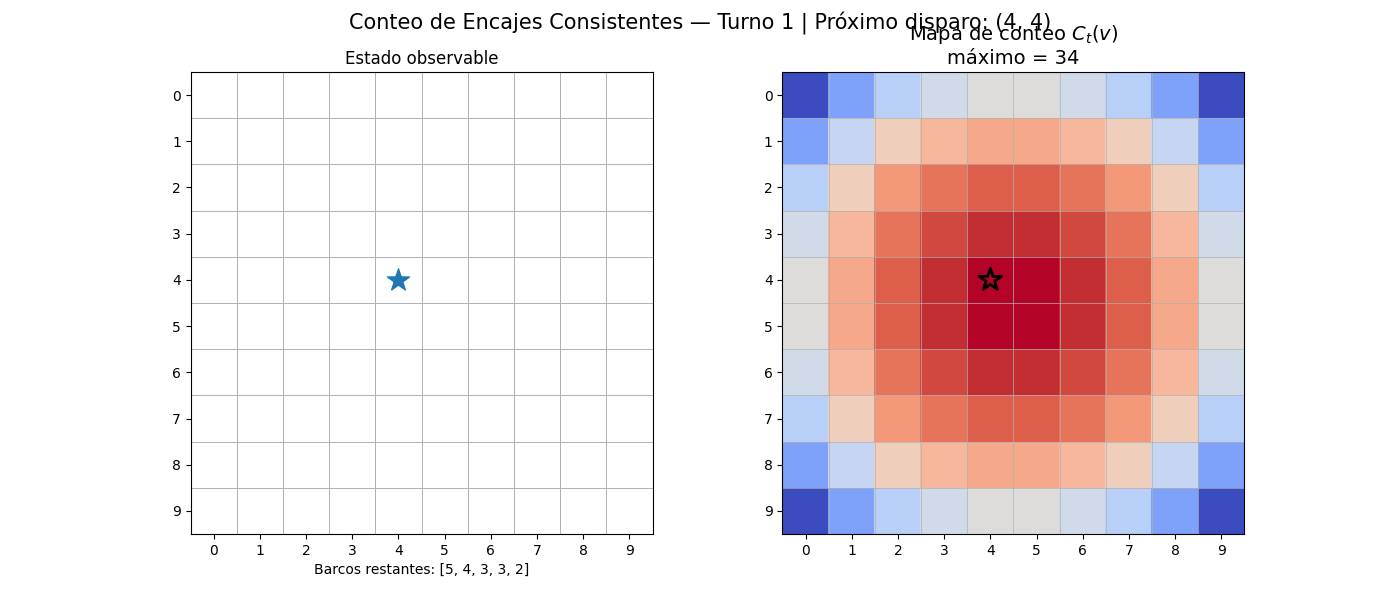

In [ ]:
# ============================================================
# 10.1 GIF: EVOLUCIÓN DEL MAPA DE CONTEO C_t(v)
# ============================================================
flota_conteo = generar_flota_valida()                                         #Genera una flota válida para el ejemplo.
estado_conteo = crear_estado_partida()                                         #Crea el estado observable inicial.

fotogramas_conteo = []                                                        #Almacena los estados y mapas de conteo de cada turno.


while not todos_los_barcos_hundidos(estado_conteo):                            #Continúa mientras existan barcos activos en R_t.

    D_t = estado_conteo["D_t"]                                                #Obtiene las celdas ya disparadas.
    M_t = estado_conteo["M_t"]                                                #Obtiene las celdas conocidas como agua.
    A_t = estado_conteo["A_t"]                                                #Obtiene los impactos activos.
    S_t = estado_conteo["S_t"]                                                #Obtiene las celdas de barcos hundidos.
    R_t = estado_conteo["R_t"]                                                #Obtiene las longitudes de los barcos restantes.

    celda_disparo, C_t = seleccionar_disparo_conteo(                           #Calcula el mapa C_t(v) y selecciona su máximo.
        D_t,
        M_t,
        A_t,
        S_t,
        R_t,
        ENCAJES_POR_LONGITUD
    )

    fotogramas_conteo.append({                                                #Guarda el estado utilizado para tomar la decisión.
        "turno": len(D_t) + 1,
        "disparo": celda_disparo,
        "D_t": D_t.copy(),
        "M_t": M_t.copy(),
        "A_t": A_t.copy(),
        "S_t": S_t.copy(),
        "R_t": R_t.copy(),
        "C_t": C_t.copy()
    })

    disparar(celda_disparo, flota_conteo, estado_conteo)                      #Ejecuta el disparo seleccionado por Conteo.
    validar_estado_partida(estado_conteo)                                      #Valida el nuevo estado observable.


fig, axes = plt.subplots(1, 2, figsize=(14, 6))                                #Crea el tablero observable y el heatmap de Conteo.


def actualizar_conteo(frame):                                                 #Actualiza únicamente la representación gráfica del GIF.

    ax_estado, ax_mapa = axes                                                 #Separa los dos paneles de la animación.
    ax_estado.clear()                                                         #Limpia el tablero observable.
    ax_mapa.clear()                                                           #Limpia el mapa de conteo.

    datos = fotogramas_conteo[frame]                                          #Obtiene la información correspondiente al turno actual.


    # --------------------------------------------------------
    # ESTADO OBSERVABLE
    # --------------------------------------------------------

    ax_estado.set_xlim(-0.5, TAMANO_TABLERO - 0.5)                            #Define los límites horizontales.
    ax_estado.set_ylim(TAMANO_TABLERO - 0.5, -0.5)                            #Define los límites verticales.
    ax_estado.set_xticks(range(TAMANO_TABLERO))                               #Muestra las columnas.
    ax_estado.set_yticks(range(TAMANO_TABLERO))                               #Muestra las filas.
    ax_estado.set_xticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)      #Define los límites verticales de las celdas.
    ax_estado.set_yticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)      #Define los límites horizontales de las celdas.
    ax_estado.grid(which="minor", linewidth=0.7)                              #Dibuja la cuadrícula.
    ax_estado.tick_params(which="minor", bottom=False, left=False)            #Oculta las marcas auxiliares.
    ax_estado.set_aspect("equal")                                             #Mantiene las celdas cuadradas.


    for fila, columna in datos["M_t"]:                                        #Recorre las celdas conocidas como agua.
        ax_estado.text(
            columna,
            fila,
            "○",
            ha="center",
            va="center",
            fontsize=18
        )


    for fila, columna in datos["A_t"]:                                        #Recorre los impactos activos.
        ax_estado.text(
            columna,
            fila,
            "X",
            ha="center",
            va="center",
            fontsize=18,
            fontweight="bold"
        )


    for fila, columna in datos["S_t"]:                                        #Recorre las celdas pertenecientes a barcos hundidos.
        ax_estado.text(
            columna,
            fila,
            "■",
            ha="center",
            va="center",
            fontsize=17
        )


    fila_disparo, columna_disparo = datos["disparo"]                          #Obtiene la celda seleccionada por el mapa de Conteo.

    ax_estado.scatter(                                                        #Marca el siguiente disparo seleccionado.
        columna_disparo,
        fila_disparo,
        marker="*",
        s=280,
        zorder=5
    )

    ax_estado.set_title("Estado observable")                                  #Define el título del primer panel.
    ax_estado.set_xlabel(f"Barcos restantes: {datos['R_t']}")                 #Muestra las longitudes todavía activas.


    # --------------------------------------------------------
    # MAPA DE CONTEO C_t(v)
    # --------------------------------------------------------

    matriz_C = datos["C_t"].copy()                                            #Utiliza directamente la matriz C_t(v) calculada por la estrategia.

    minimo_turno = np.min(matriz_C)                                           #Obtiene el menor valor de C_t(v) del turno actual.
    maximo_turno = np.max(matriz_C)                                           #Obtiene el mayor valor de C_t(v) del turno actual.


    mapa_calor = ax_mapa.imshow(                                              #Representa C_t(v) mediante una escala térmica frío-calor.
        matriz_C,
        origin="upper",
        extent=(
            -0.5,
            TAMANO_TABLERO - 0.5,
            TAMANO_TABLERO - 0.5,
            -0.5
        ),
        cmap="coolwarm",                                                       #Azul = menor conteo, rojo = mayor conteo.
        vmin=minimo_turno,                                                     #Define el extremo frío según el mínimo del turno.
        vmax=maximo_turno,                                                     #Define el extremo caliente según el máximo del turno.
        aspect="equal"
    )


    ax_mapa.set_xticks(range(TAMANO_TABLERO))                                 #Muestra las columnas del mapa.
    ax_mapa.set_yticks(range(TAMANO_TABLERO))                                 #Muestra las filas del mapa.
    ax_mapa.set_xticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)        #Define los límites verticales de las celdas.
    ax_mapa.set_yticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)        #Define los límites horizontales de las celdas.
    ax_mapa.grid(which="minor", linewidth=0.5)                                #Dibuja la cuadrícula del heatmap.
    ax_mapa.tick_params(which="minor", bottom=False, left=False)              #Oculta las marcas auxiliares.
    ax_mapa.set_aspect("equal")                                               #Mantiene las celdas cuadradas.


    ax_mapa.scatter(                                                          #Marca el argmax de C_t(v).
        columna_disparo,
        fila_disparo,
        marker="*",
        s=280,
        facecolors="none",
        edgecolors="black",
        linewidths=2,
        zorder=5
    )


    valor_maximo = datos["C_t"][datos["disparo"]]                             #Obtiene el valor de C_t(v) de la celda seleccionada.

    ax_mapa.set_title(                                                        #Muestra el mapa y el valor máximo del turno.
        f"Mapa de conteo $C_t(v)$\n"
        f"máximo = {valor_maximo}",
        fontsize=14
    )


    fig.suptitle(                                                             #Muestra el turno y la decisión tomada por la estrategia.
        f"Conteo de Encajes Consistentes — Turno {datos['turno']} | "
        f"Próximo disparo: {datos['disparo']}",
        fontsize=15
    )


animacion_conteo = FuncAnimation(                                             #Construye la animación con todos los estados almacenados.
    fig,
    actualizar_conteo,
    frames=len(fotogramas_conteo),
    interval=1500,
    repeat=True
)


animacion_conteo.save(                                                        #Guarda la animación como archivo GIF.
    "evolucion_mapa_conteo.gif",
    writer=PillowWriter(fps=3)
)


plt.close(fig)                                                                 #Evita mostrar adicionalmente una figura estática.

display(Image(filename="evolucion_mapa_conteo.gif"))

## 11. Funciones auxiliares para las estrategias

En esta sección se definen funciones de apoyo utilizadas por las distintas políticas de disparo durante la partida.

Estas funciones permiten identificar las celdas que todavía no han sido atacadas, obtener los vecinos ortogonales de una posición y agrupar impactos activos que se encuentren conectados entre sí.

La identificación de celdas disponibles garantiza que las estrategias solo seleccionen posiciones que aún no pertenecen a $D_t$.

Los vecinos ortogonales permiten analizar las posiciones inmediatamente adyacentes a una celda, lo cual resulta especialmente útil en estrategias que después de obtener un impacto, concentran la búsqueda alrededor de esa zona.

Por otra parte, los impactos activos contenidos en $A_t$ se agrupan según conectividad ortogonal. Cada grupo representa una región del tablero asociada a uno o más impactos todavía no resueltos, facilitando que las estrategias puedan orientar la búsqueda sobre posibles extensiones de un barco.

Estas funciones no implementan una política de disparo por sí mismas, sino que proporcionan operaciones comunes reutilizadas por las estrategias definidas posteriormente.

In [ ]:
# ============================================================
# 11. FUNCIONES AUXILIARES PARA LAS ESTRATEGIAS
# ============================================================

def obtener_celdas_no_disparadas(estado_partida):                              #Devuelve las celdas que todavía no han sido disparadas.
    D_t = estado_partida["D_t"]                                                #Obtiene el conjunto de disparos realizados hasta el turno t.
    celdas_no_disparadas = []                                                  #Inicializa la lista de celdas que permanecen disponibles.

    for celda in obtener_todas_las_celdas():                                   #Recorre todas las celdas del tablero.
        if celda not in D_t:                                                   #Verifica que la celda todavía no haya sido disparada.
            celdas_no_disparadas.append(celda)                                 #Agrega la celda al conjunto de posiciones disponibles.

    return celdas_no_disparadas                                                #Devuelve todas las celdas que no pertenecen a D_t.


def obtener_vecinos_ortogonales(celda):                                        #Obtiene las celdas ortogonalmente adyacentes a una celda dada.
    fila, columna = celda                                                      #Separa la fila y la columna de la celda evaluada.
    vecinos = []                                                               #Inicializa la lista de vecinos ortogonales.

    posibles_vecinos = [                                                       #Define las cuatro posiciones ortogonalmente adyacentes.
        (fila - 1, columna),
        (fila + 1, columna),
        (fila, columna - 1),
        (fila, columna + 1)
    ]

    for vecino in posibles_vecinos:                                            #Recorre las cuatro posiciones candidatas.
        if celda_dentro_tablero(vecino):                                       #Verifica que el vecino pertenezca al tablero.
            vecinos.append(vecino)                                             #Agrega el vecino válido a la lista.

    return vecinos                                                             #Devuelve los vecinos ortogonales que pertenecen al tablero.

def agrupar_impactos_activos(estado_partida):                                  #Agrupa impactos activos conectados ortogonalmente.
    impactos_pendientes = set(estado_partida["A_t"])                           #Copia los impactos activos para poder procesarlos sin modificar A_t.
    grupos_impactos = []                                                       #Inicializa la lista que almacenará los grupos encontrados.

    while impactos_pendientes:                                                 #Continúa mientras existan impactos activos sin agrupar.
        celda_inicial = impactos_pendientes.pop()                              #Extrae una celda para comenzar un nuevo grupo.
        grupo_actual = {celda_inicial}                                         #Inicializa el grupo con la celda seleccionada.
        celdas_por_revisar = [celda_inicial]                                   #Inicializa la lista de celdas pendientes de explorar dentro del grupo.

        while celdas_por_revisar:                                              #Explora todas las celdas conectadas al grupo actual.
            celda_actual = celdas_por_revisar.pop()                            #Obtiene la siguiente celda que debe ser revisada.

            for vecino in obtener_vecinos_ortogonales(celda_actual):           #Recorre los vecinos ortogonales de la celda actual.
                if vecino in impactos_pendientes:                              #Verifica si el vecino corresponde a otro impacto activo.
                    impactos_pendientes.remove(vecino)                         #Elimina el vecino de los impactos todavía pendientes.
                    grupo_actual.add(vecino)                                   #Agrega el impacto al grupo conectado actual.
                    celdas_por_revisar.append(vecino)                          #Programa el nuevo impacto para revisar sus propios vecinos.

        grupos_impactos.append(grupo_actual)                                   #Agrega el grupo completo a la lista de grupos encontrados.

    return grupos_impactos                                                     #Devuelve los grupos de impactos activos.



# 12. Estrategia de Paridad

En esta sección se implementa una estrategia heurística basada en un patrón de paridad sobre el tablero.

La idea consiste en priorizar inicialmente las celdas que cumplen

$$
(fila + columna) \bmod 2 = 0,
$$

generando así un patrón alternado similar a un tablero de ajedrez.

Esta estrategia reduce el espacio inicial de búsqueda al evitar disparar sobre todas las celdas de manera uniforme. Mientras existan posiciones disponibles dentro del patrón de paridad, los disparos se seleccionan únicamente entre esas celdas.

Cuando todas las celdas de la paridad definida ya han sido atacadas, la estrategia continúa seleccionando entre las posiciones restantes del tablero.


La estrategia de Paridad se utiliza como una política base de comparación, ya que introduce una estructura simple de búsqueda sin utilizar información probabilística sobre la ubicación de los barcos.

In [ ]:
# ============================================================
# 12. ESTRATEGIA DE PARIDAD
# ============================================================

def seleccionar_disparo_paridad(estado_partida, tamano_tablero=TAMANO_TABLERO):    #Selecciona una celda no disparada siguiendo el patrón de paridad.
    D_t = estado_partida["D_t"]                                                     #Obtiene el conjunto de celdas disparadas hasta el turno t.
    celdas_paridad = []                                                             #Inicializa la lista de celdas candidatas que cumplen la paridad.

    for fila in range(tamano_tablero):                                               #Recorre todas las filas del tablero.
        for columna in range(tamano_tablero):                                        #Recorre todas las columnas del tablero.
            celda = (fila, columna)                                                  #Construye la coordenada de la celda evaluada.

            if celda in D_t:                                                         #Verifica si la celda ya fue disparada.
                continue                                                             #Descarta la celda si pertenece a D_t.

            if (fila + columna) % 2 == 0:                                            #Verifica si la celda pertenece al patrón de paridad definido.
                celdas_paridad.append(celda)                                         #Agrega la celda al conjunto de candidatas de Paridad.

    if celdas_paridad:                                                               #Verifica si todavía existen celdas disponibles dentro del patrón de paridad.
        if REGLA_DESEMPATE == "aleatorio":                                           #Verifica si el experimento utiliza desempate aleatorio.
            return random.choice(celdas_paridad)                                     #Selecciona aleatoriamente una celda candidata.
        return min(celdas_paridad)                                                   #Selecciona la primera celda según orden lexicográfico.

    celdas_restantes = []                                                            #Inicializa la lista de celdas no disparadas fuera del patrón de paridad.

    for fila in range(tamano_tablero):                                               #Recorre nuevamente todas las filas del tablero.
        for columna in range(tamano_tablero):                                        #Recorre nuevamente todas las columnas del tablero.
            celda = (fila, columna)                                                  #Construye la coordenada de la celda evaluada.

            if celda not in D_t:                                                     #Verifica que la celda todavía no haya sido disparada.
                celdas_restantes.append(celda)                                       #Agrega la celda a las posiciones disponibles restantes.

    if not celdas_restantes:                                                         #Verifica si ya no quedan celdas disponibles.
        return None                                                                  #Devuelve None cuando el tablero ya fue completamente disparado.

    if REGLA_DESEMPATE == "aleatorio":                                               #Verifica si se utiliza desempate aleatorio.
        return random.choice(celdas_restantes)                                       #Selecciona aleatoriamente una celda restante.

    return min(celdas_restantes)                                                     #Selecciona la primera celda restante según orden lexicográfico.


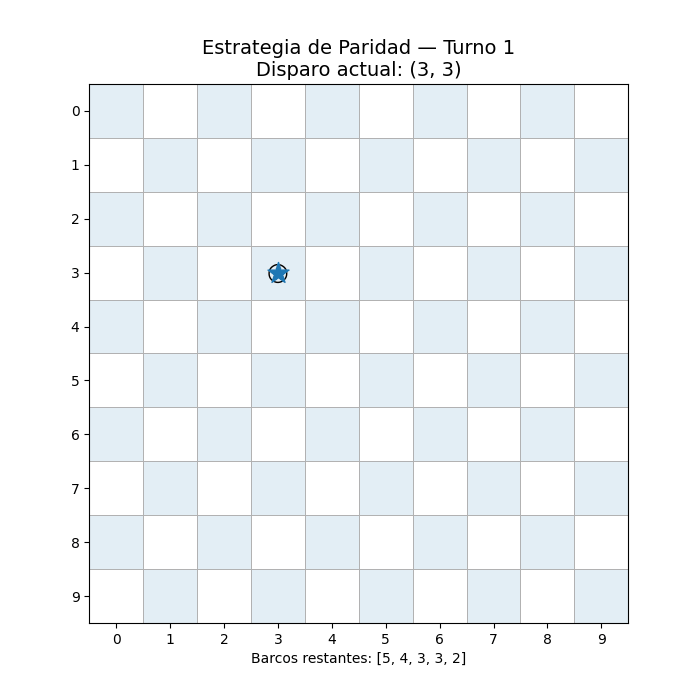

In [ ]:
# ============================================================
# 12.1 EJEMPLO: FUNCIONAMIENTO DE LA ESTRATEGIA DE PARIDAD
# ============================================================
flota_paridad = generar_flota_valida()                                        #Genera una flota válida para el ejemplo.
estado_paridad = crear_estado_partida()                                        #Crea el estado observable inicial de la partida.

fotogramas_paridad = []                                                       #Almacena los estados sucesivos de la estrategia.


while not todos_los_barcos_hundidos(estado_paridad):                           #Continúa hasta hundir todos los barcos.

    celda_disparo = seleccionar_disparo_paridad(estado_paridad)                #Selecciona el siguiente disparo utilizando Paridad.

    if celda_disparo is None:                                                  #Comprueba si quedan celdas disponibles.
        break                                                                  #Finaliza si todo el tablero fue disparado.

    disparar(celda_disparo, flota_paridad, estado_paridad)                     #Ejecuta el disparo seleccionado por la estrategia.
    validar_estado_partida(estado_paridad)                                     #Valida el nuevo estado observable.

    fotogramas_paridad.append({                                                #Guarda una copia del estado después del disparo.
        "turno": len(estado_paridad["D_t"]),
        "disparo": celda_disparo,
        "D_t": estado_paridad["D_t"].copy(),
        "M_t": estado_paridad["M_t"].copy(),
        "A_t": estado_paridad["A_t"].copy(),
        "S_t": estado_paridad["S_t"].copy(),
        "R_t": estado_paridad["R_t"].copy()
    })


fig, ax = plt.subplots(figsize=(7, 7))                                         #Crea el tablero utilizado por la animación.


def actualizar_paridad(frame):                                                #Actualiza únicamente la representación gráfica del GIF.

    ax.clear()                                                                 #Limpia el fotograma anterior.

    datos = fotogramas_paridad[frame]                                         #Obtiene la información del turno actual.

    ax.set_xlim(-0.5, TAMANO_TABLERO - 0.5)                                   #Define los límites horizontales.
    ax.set_ylim(TAMANO_TABLERO - 0.5, -0.5)                                   #Define los límites verticales.
    ax.set_xticks(range(TAMANO_TABLERO))                                       #Muestra las columnas del tablero.
    ax.set_yticks(range(TAMANO_TABLERO))                                       #Muestra las filas del tablero.
    ax.set_xticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)              #Define los límites verticales de las celdas.
    ax.set_yticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)              #Define los límites horizontales de las celdas.
    ax.grid(which="minor", linewidth=0.7)                                      #Dibuja la cuadrícula.
    ax.tick_params(which="minor", bottom=False, left=False)                    #Oculta las marcas auxiliares.
    ax.set_aspect("equal")                                                     #Mantiene las celdas cuadradas.

    for fila in range(TAMANO_TABLERO):                                         #Recorre las filas del tablero.
        for columna in range(TAMANO_TABLERO):                                  #Recorre las columnas del tablero.
            if (fila + columna) % 2 == 0:                                      #Identifica las celdas pertenecientes al patrón de paridad.
                ax.add_patch(                                                  #Marca visualmente las celdas de paridad.
                    plt.Rectangle(
                        (columna - 0.5, fila - 0.5),
                        1, 1,
                        alpha=0.12
                    )
                )

    for fila, columna in datos["M_t"]:                                         #Recorre los disparos cuyo resultado fue agua.
        ax.text(columna, fila, "○", ha="center", va="center", fontsize=18)     #Representa cada disparo fallido.

    for fila, columna in datos["A_t"]:                                         #Recorre los impactos activos.
        ax.text(
            columna, fila, "X",
            ha="center", va="center",
            fontsize=18, fontweight="bold"
        )

    for fila, columna in datos["S_t"]:                                         #Recorre las celdas pertenecientes a barcos hundidos.
        ax.text(columna, fila, "■", ha="center", va="center", fontsize=17)     #Representa las celdas de barcos hundidos.

    fila, columna = datos["disparo"]                                           #Obtiene la celda seleccionada en el turno actual.

    ax.scatter(                                                               #Destaca el disparo realizado en el fotograma actual.
        columna, fila,
        marker="*",
        s=250,
        zorder=5
    )

    ax.set_title(                                                              #Muestra el turno y la celda seleccionada.
        f"Estrategia de Paridad — Turno {datos['turno']}\n"
        f"Disparo actual: {datos['disparo']}",
        fontsize=14
    )

    ax.set_xlabel(f"Barcos restantes: {datos['R_t']}")                         #Muestra las longitudes de los barcos restantes.


animacion_paridad = FuncAnimation(                                            #Construye la animación completa.
    fig,
    actualizar_paridad,
    frames=len(fotogramas_paridad),
    interval=350,
    repeat=True
)


animacion_paridad.save(                                                       #Guarda la animación como archivo GIF.
    "estrategia_paridad.gif",
    writer=PillowWriter(fps=3)
)


plt.close(fig)                                                                 #Evita mostrar una figura estática adicional.

display(Image(filename="estrategia_paridad.gif"))

# 13. Estrategia Hunt/Target

En esta sección se implementa una estrategia heurística de dos fases: **Hunt** y **Target**.

Durante la fase **Hunt**, la estrategia busca localizar nuevos barcos utilizando la estrategia de Paridad. Esta fase se mantiene mientras no existan impactos activos que indiquen la presencia de un barco todavía no hundido.

Cuando aparece uno o más impactos activos, la estrategia cambia a la fase **Target**. En esta etapa se utilizan las celdas contenidas en $A_t$ para concentrar la búsqueda alrededor de las posiciones ya impactadas.

Los impactos activos se agrupan según conectividad ortogonal. Para cada grupo se analiza si existe una orientación identificable:

- si varios impactos se encuentran alineados horizontalmente, se priorizan las posibles prolongaciones a izquierda y derecha;
- si los impactos se encuentran alineados verticalmente, se priorizan las posibles prolongaciones superior e inferior;
- si todavía no existe una orientación clara, se consideran como candidatas las celdas ortogonalmente adyacentes a los impactos.

Las celdas que se encuentran fuera del tablero o que ya pertenecen a $D_t$ son descartadas.

Cuando existen varios grupos de impactos activos, se priorizan aquellos que contienen mayor cantidad de información, es decir, los grupos con más impactos conocidos.

Si no existen candidatos válidos en la fase Target, la estrategia regresa automáticamente a la fase Hunt mediante Paridad.


In [ ]:
# ============================================================
# 13. ESTRATEGIA HUNT/TARGET
# ============================================================

def obtener_candidatas_target(grupo_impactos, estado_partida):                 #Obtiene las celdas candidatas de la fase Target.
    D_t = estado_partida["D_t"]                                                #Obtiene el conjunto de disparos realizados.
    candidatas = []                                                            #Inicializa la lista de celdas candidatas.

    filas = {fila for fila, _ in grupo_impactos}                               #Obtiene las filas ocupadas por los impactos activos del grupo.
    columnas = {columna for _, columna in grupo_impactos}                      #Obtiene las columnas ocupadas por los impactos activos del grupo.

    if len(grupo_impactos) >= 2 and len(filas) == 1:                           #Verifica si existen dos o más impactos alineados horizontalmente.
        fila = next(iter(filas))                                               #Obtiene la fila común de los impactos alineados.
        columnas_ordenadas = sorted(columnas)                                  #Ordena las columnas de los impactos de izquierda a derecha.
        candidatas = [                                                         #Define como candidatas las dos posibles prolongaciones horizontales.
            (fila, columnas_ordenadas[0] - 1),
            (fila, columnas_ordenadas[-1] + 1)
        ]

    elif len(grupo_impactos) >= 2 and len(columnas) == 1:                      #Verifica si existen dos o más impactos alineados verticalmente.
        columna = next(iter(columnas))                                         #Obtiene la columna común de los impactos alineados.
        filas_ordenadas = sorted(filas)                                        #Ordena las filas de los impactos de arriba hacia abajo.
        candidatas = [                                                         #Define como candidatas las dos posibles prolongaciones verticales.
            (filas_ordenadas[0] - 1, columna),
            (filas_ordenadas[-1] + 1, columna)
        ]

    else:                                                                      #Ejecuta este caso cuando todavía no existe una orientación identificada.
        for impacto in grupo_impactos:                                         #Recorre cada impacto activo del grupo.
            candidatas.extend(obtener_vecinos_ortogonales(impacto))            #Agrega sus vecinos ortogonales como posibles objetivos.

    candidatas_validas = []                                                    #Inicializa la lista final de candidatas válidas.

    for celda in candidatas:                                                   #Recorre todas las celdas candidatas construidas.
        if not celda_dentro_tablero(celda):                                    #Verifica si la celda se encuentra fuera del tablero.
            continue                                                           #Descarta la celda inválida.

        if celda in D_t:                                                       #Verifica si la celda ya fue disparada anteriormente.
            continue                                                           #Descarta las celdas pertenecientes a D_t.

        if celda in candidatas_validas:                                        #Verifica si la candidata ya fue registrada.
            continue                                                           #Evita almacenar celdas duplicadas.

        candidatas_validas.append(celda)                                       #Agrega la celda porque cumple todas las condiciones.

    return candidatas_validas                                                  #Devuelve las celdas disponibles para la fase Target.


def seleccionar_disparo_hunt_target(estado_partida):                           #Selecciona el siguiente disparo mediante las fases Hunt y Target.
    grupos_impactos = agrupar_impactos_activos(estado_partida)                 #Obtiene los grupos de impactos activos disponibles.

    grupos_impactos.sort(                                                      #Ordena los grupos para priorizar aquellos con mayor información.
        key=lambda grupo: len(grupo),
        reverse=True
    )

    for grupo_impactos in grupos_impactos:                                     #Recorre los grupos de impactos activos ordenados.
        candidatas = obtener_candidatas_target(                                #Obtiene las posibles celdas de continuación del grupo actual.
            grupo_impactos,
            estado_partida
        )

        if candidatas:                                                         #Verifica si existen celdas válidas para continuar la fase Target.
            if REGLA_DESEMPATE == "aleatorio":                                 #Verifica si se utiliza desempate aleatorio.
                return random.choice(candidatas)                               #Selecciona aleatoriamente una candidata de Target.

            return min(candidatas)                                             #Selecciona lexicográficamente cuando el desempate es determinista.

    return seleccionar_disparo_paridad(estado_partida)                         #Regresa a la fase Hunt mediante Paridad cuando no existen impactos activos.

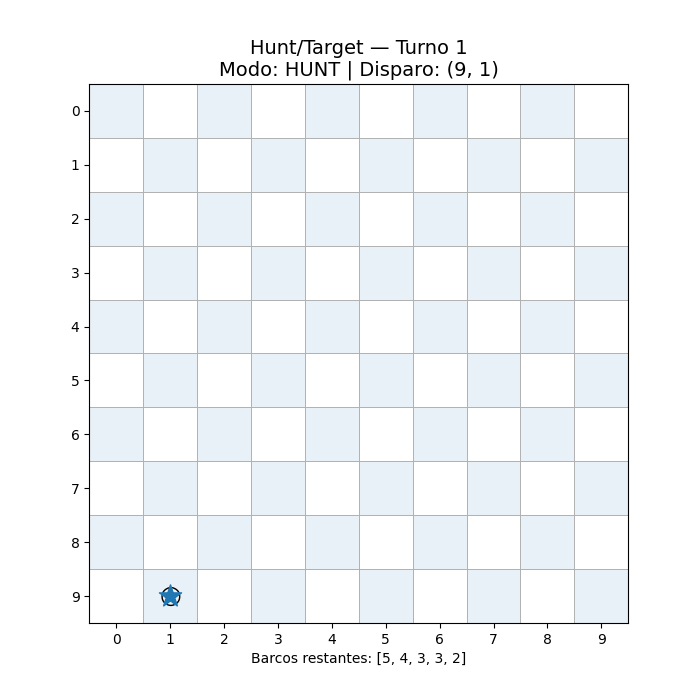

In [ ]:
# ============================================================
# 13.1 EJEMPLO: FUNCIONAMIENTO DE LA ESTRATEGIA HUNT/TARGET
# ============================================================

flota_ht = generar_flota_valida()                                              #Genera una flota válida para el ejemplo.
estado_ht = crear_estado_partida()                                              #Crea el estado observable inicial de la partida.

fotogramas_ht = []                                                             #Almacena los estados sucesivos de Hunt/Target.


while not todos_los_barcos_hundidos(estado_ht):                                #Continúa mientras existan barcos activos en R_t.

    grupos_antes = agrupar_impactos_activos(estado_ht)                         #Obtiene los impactos activos antes de seleccionar el disparo.

    if grupos_antes:                                                           #Verifica si existen impactos activos.
        modo = "TARGET"                                                        #La estrategia se encuentra en fase Target.

        grupos_antes.sort(                                                     #Ordena los grupos igual que la estrategia Hunt/Target.
            key=lambda grupo: len(grupo),
            reverse=True
        )

        grupo_objetivo = grupos_antes[0]                                       #Obtiene el grupo de impactos con mayor prioridad.
        candidatas_target = obtener_candidatas_target(                         #Obtiene las candidatas Target del grupo prioritario.
            grupo_objetivo,
            estado_ht
        )

    else:                                                                      #Ejecuta este caso cuando no existen impactos activos.
        modo = "HUNT"                                                          #La estrategia se encuentra en fase Hunt.
        grupo_objetivo = set()                                                 #No existe un grupo de impactos objetivo.
        candidatas_target = []                                                 #No existen candidatas Target.

    celda_disparo = seleccionar_disparo_hunt_target(estado_ht)                 #Selecciona el siguiente disparo usando Hunt/Target.

    if celda_disparo is None:                                                  #Verifica si todavía existen celdas disponibles.
        break                                                                  #Finaliza si no quedan posibles disparos.

    disparar(celda_disparo, flota_ht, estado_ht)                               #Ejecuta el disparo seleccionado por Hunt/Target.
    validar_estado_partida(estado_ht)                                          #Valida el nuevo estado observable.

    fotogramas_ht.append({                                                     #Guarda una copia del estado correspondiente al turno.
        "turno": len(estado_ht["D_t"]),
        "modo": modo,
        "disparo": celda_disparo,
        "grupo": grupo_objetivo.copy(),
        "candidatas": candidatas_target.copy(),
        "D_t": estado_ht["D_t"].copy(),
        "M_t": estado_ht["M_t"].copy(),
        "A_t": estado_ht["A_t"].copy(),
        "S_t": estado_ht["S_t"].copy(),
        "R_t": estado_ht["R_t"].copy()
    })


fig, ax = plt.subplots(figsize=(7, 7))                                         #Crea el tablero utilizado por la animación.


def actualizar_hunt_target(frame):                                             #Actualiza únicamente la representación gráfica del GIF.

    ax.clear()                                                                 #Limpia el fotograma anterior.

    datos = fotogramas_ht[frame]                                               #Obtiene la información correspondiente al turno actual.

    ax.set_xlim(-0.5, TAMANO_TABLERO - 0.5)                                   #Define los límites horizontales.
    ax.set_ylim(TAMANO_TABLERO - 0.5, -0.5)                                   #Define los límites verticales.
    ax.set_xticks(range(TAMANO_TABLERO))                                       #Muestra las columnas del tablero.
    ax.set_yticks(range(TAMANO_TABLERO))                                       #Muestra las filas del tablero.
    ax.set_xticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)              #Define los límites verticales de las celdas.
    ax.set_yticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)              #Define los límites horizontales de las celdas.
    ax.grid(which="minor", linewidth=0.7)                                      #Dibuja la cuadrícula.
    ax.tick_params(which="minor", bottom=False, left=False)                    #Oculta las marcas auxiliares.
    ax.set_aspect("equal")                                                     #Mantiene las celdas cuadradas.


    if datos["modo"] == "HUNT":                                                #Comprueba si el turno fue seleccionado mediante Hunt.

        for fila in range(TAMANO_TABLERO):                                     #Recorre todas las filas del tablero.
            for columna in range(TAMANO_TABLERO):                              #Recorre todas las columnas del tablero.

                if (fila + columna) % 2 == 0:                                  #Identifica las celdas pertenecientes al patrón de Paridad.
                    ax.add_patch(                                              #Sombrea las celdas utilizadas durante Hunt.
                        plt.Rectangle(
                            (columna - 0.5, fila - 0.5),
                            1, 1,
                            alpha=0.10
                        )
                    )


    if datos["modo"] == "TARGET":                                              #Comprueba si el turno fue seleccionado mediante Target.

        for fila, columna in datos["candidatas"]:                              #Recorre las candidatas calculadas por Target.
            ax.scatter(
                columna, fila,
                marker="s",
                s=170,
                facecolors="none",
                edgecolors="black",
                linewidths=2,
                zorder=3
            )


    for fila, columna in datos["M_t"]:                                         #Recorre los disparos cuyo resultado fue agua.
        ax.text(
            columna, fila, "○",
            ha="center", va="center",
            fontsize=18
        )


    for fila, columna in datos["A_t"]:                                         #Recorre los impactos activos.
        ax.text(
            columna, fila, "X",
            ha="center", va="center",
            fontsize=18,
            fontweight="bold"
        )


    for fila, columna in datos["S_t"]:                                         #Recorre las celdas pertenecientes a barcos hundidos.
        ax.text(
            columna, fila, "■",
            ha="center", va="center",
            fontsize=17
        )


    fila, columna = datos["disparo"]                                           #Obtiene la celda disparada durante el turno.

    ax.scatter(                                                               #Destaca el disparo realizado en el turno actual.
        columna, fila,
        marker="*",
        s=280,
        zorder=5
    )


    ax.set_title(                                                              #Muestra el turno y la fase utilizada por Hunt/Target.
        f"Hunt/Target — Turno {datos['turno']}\n"
        f"Modo: {datos['modo']} | Disparo: {datos['disparo']}",
        fontsize=14
    )

    ax.set_xlabel(f"Barcos restantes: {datos['R_t']}")                         #Muestra las longitudes de los barcos restantes.


animacion_ht = FuncAnimation(                                                  #Construye la animación completa.
    fig,
    actualizar_hunt_target,
    frames=len(fotogramas_ht),
    interval=350,
    repeat=True
)


animacion_ht.save(                                                             #Guarda la animación como archivo GIF.
    "estrategia_hunt_target.gif",
    writer=PillowWriter(fps=3)
)


plt.close(fig)                                                                 #Evita mostrar una figura estática adicional.

display(Image(filename="estrategia_hunt_target.gif"))

## 14. Interfaz común de las estrategias

En esta sección se define una interfaz única para ejecutar cualquiera de las estrategias implementadas durante la simulación de una partida.

La función recibe el nombre de la estrategia y el estado observable actual, y delega la selección del siguiente disparo al procedimiento correspondiente.

Para las estrategias de Paridad y Hunt/Target, la interfaz utiliza directamente el estado observable de la partida. En el caso de la estrategia de Conteo, extrae explícitamente los conjuntos $D_t$, $M_t$, $A_t$, $S_t$ y el multiconjunto $R_t$, necesarios para construir el mapa $C_t(v)$ y seleccionar una celda perteneciente a su máximo.

Esta capa común permite que el motor de simulación pueda trabajar con distintas políticas sin modificar su lógica interna. De esta manera, todas las estrategias se evalúan bajo las mismas reglas, estructura de estado y dinámica de juego.

La separación entre el motor y las políticas de decisión también facilita la comparación experimental y la incorporación de nuevas estrategias sin alterar el funcionamiento general del proyecto.

In [ ]:
# ============================================================
# 14. INTERFAZ COMÚN DE LAS ESTRATEGIAS
# ============================================================

def seleccionar_disparo(nombre_estrategia, estado_partida):                                  #Selecciona el siguiente disparo según la estrategia indicada.

    if nombre_estrategia == "paridad":                                                        #Verifica si debe ejecutarse la estrategia de Paridad.
        return seleccionar_disparo_paridad(estado_partida)                                    #Devuelve la celda seleccionada mediante Paridad.

    if nombre_estrategia == "hunt_target":                                                     #Verifica si debe ejecutarse la estrategia Hunt/Target.
        return seleccionar_disparo_hunt_target(estado_partida)                                 #Devuelve la celda seleccionada mediante Hunt/Target.

    if nombre_estrategia == "conteo":                                                          #Verifica si debe ejecutarse la estrategia C_t(v).

        D_t = estado_partida["D_t"]                                                            #Obtiene las celdas que ya recibieron disparos.
        M_t = estado_partida["M_t"]                                                            #Obtiene las celdas conocidas como agua.
        A_t = estado_partida["A_t"]                                                            #Obtiene los impactos activos.
        S_t = estado_partida["S_t"]                                                            #Obtiene las celdas de barcos ya hundidos.
        R_t = estado_partida["R_t"]                                                            #Obtiene las longitudes de los barcos restantes.

        celda, C_t = seleccionar_disparo_conteo(                                              #Calcula el argmax del mapa de conteo C_t(v).
            D_t,
            M_t,
            A_t,
            S_t,
            R_t,
            ENCAJES_POR_LONGITUD
        )

        return celda                                                                           #Devuelve únicamente la celda elegida por la estrategia.

    raise ValueError(                                                                          #Detiene la ejecución si el nombre de estrategia no existe.
        f"Estrategia no reconocida: {nombre_estrategia}"
    )

## 15. Simulación de una partida completa

En esta sección se implementa el motor encargado de ejecutar una partida completa de Batalla Naval utilizando una estrategia determinada.

Para cada simulación se crea una copia independiente de la configuración original de la flota, evitando que una estrategia modifique los datos utilizados posteriormente por otra. A continuación se inicializa el estado observable de la partida y se comienza un ciclo de disparos que continúa hasta hundir todos los barcos.

En cada turno, la estrategia selecciona una celda utilizando únicamente la información contenida en el estado observable. El motor ejecuta el disparo sobre la flota real, actualiza los conjuntos $D_t$, $M_t$, $A_t$, $S_t$ y $R_t$, y valida que las relaciones internas del estado continúen siendo consistentes.

Cada disparo queda registrado en un historial que conserva:

- el número consecutivo del disparo;
- la celda seleccionada;
- el resultado observado: `agua`, `tocado` o `hundido`.

La partida termina cuando $R_t$ queda vacío, es decir, cuando todos los barcos han sido hundidos.

Como resultado, la simulación devuelve un resumen que incluye la estrategia utilizada, el número total de disparos requeridos, la cantidad de barcos hundidos, el número de disparos únicos y el historial completo de la partida.

Esta función constituye el vínculo entre el motor del juego y las estrategias, y será posteriormente utilizada como unidad básica dentro de las simulaciones de Monte Carlo.

In [ ]:
# ============================================================
# 15. SIMULACIÓN DE UNA PARTIDA COMPLETA
# ============================================================

def copiar_flota(flota):                                                       #Crea una copia independiente de una configuración de flota.
    nueva_flota = []                                                           #Inicializa la lista que almacenará la copia de los barcos.

    for barco in flota:                                                        #Recorre cada barco de la configuración original.
        nueva_flota.append({                                                   #Agrega una copia independiente del barco actual.
            "id_barco": barco["id_barco"],                                     #Conserva el identificador interno del barco.
            "longitud": barco["longitud"],                                     #Conserva la longitud del barco.
            "orientacion": barco["orientacion"],                               #Conserva la orientación horizontal o vertical.
            "celdas": set(barco["celdas"])                                     #Copia las celdas ocupadas evitando compartir el mismo conjunto.
        })

    return nueva_flota                                                         #Devuelve una copia independiente de la flota.


def simular_partida(flota_original, nombre_estrategia):                              #Ejecuta una partida completa utilizando una estrategia determinada.
    flota = copiar_flota(flota_original)                                              #Crea una copia independiente de la flota verdadera para la simulación.
    estado_partida = crear_estado_partida()                                           #Inicializa el estado observable D_t, M_t, A_t, S_t y R_t.
    historial = []                                                                    #Inicializa el historial de disparos realizados durante la partida.

    while not todos_los_barcos_hundidos(estado_partida):                              #Continúa mientras existan longitudes de barcos pendientes en R_t.
        celda = seleccionar_disparo(                                                  #Solicita a la estrategia una nueva celda usando solo información observable.
            nombre_estrategia,
            estado_partida
        )

        if celda is None:                                                             #Verifica que la estrategia haya encontrado una celda disponible.
            raise RuntimeError("La estrategia no encontró una celda válida.")         #Detiene la partida si no existe una selección válida.

        resultado = disparar(                                                         #Ejecuta el disparo utilizando la flota real únicamente dentro del motor del juego.
            celda,
            flota,
            estado_partida
        )
        validar_estado_partida(estado_partida)                                        #Verifica que el estado observable sea consistente.

        historial.append({                                                            #Registra la información observable correspondiente al disparo realizado.
            "numero_disparo": len(historial) + 1,                                     #Almacena el número consecutivo del disparo.
            "celda": celda,                                                           #Almacena la coordenada seleccionada.
            "resultado": resultado                                                    #Almacena el resultado agua, tocado o hundido.
        })

        if len(historial) > TAMANO_TABLERO ** 2:                                      #Verifica que la partida no exceda el número total de celdas del tablero.
            raise RuntimeError("La partida superó el máximo de 100 disparos.")        #Detecta posibles errores de repetición o terminación.

    return {                                                                          #Construye el resumen final de la partida simulada.
        "estrategia": nombre_estrategia,                                              #Registra el nombre de la estrategia evaluada.
        "total_disparos": len(historial),                                             #Registra el número total de disparos necesarios para hundir la flota.
        "barcos_hundidos": len(FLOTA_ESTANDAR) - len(estado_partida["R_t"]),           #Calcula cuántos barcos fueron hundidos durante la partida.
        "disparos_unicos": len(estado_partida["D_t"]),                                 #Registra la cantidad de celdas distintas que fueron disparadas.
        "historial": historial                                                        #Conserva el historial completo de la partida.
    }

### 15.1 Ejemplo de comparación de las estrategias sobre una misma flota

El siguiente ejemplo compara el desarrollo de una partida completa utilizando las tres estrategias implementadas.
Este ejemplo ilustra el comportamiento de las estrategias en una única partida. Por tanto, que una estrategia requiera menos disparos en esta configuración particular no implica que sea superior en términos generales.

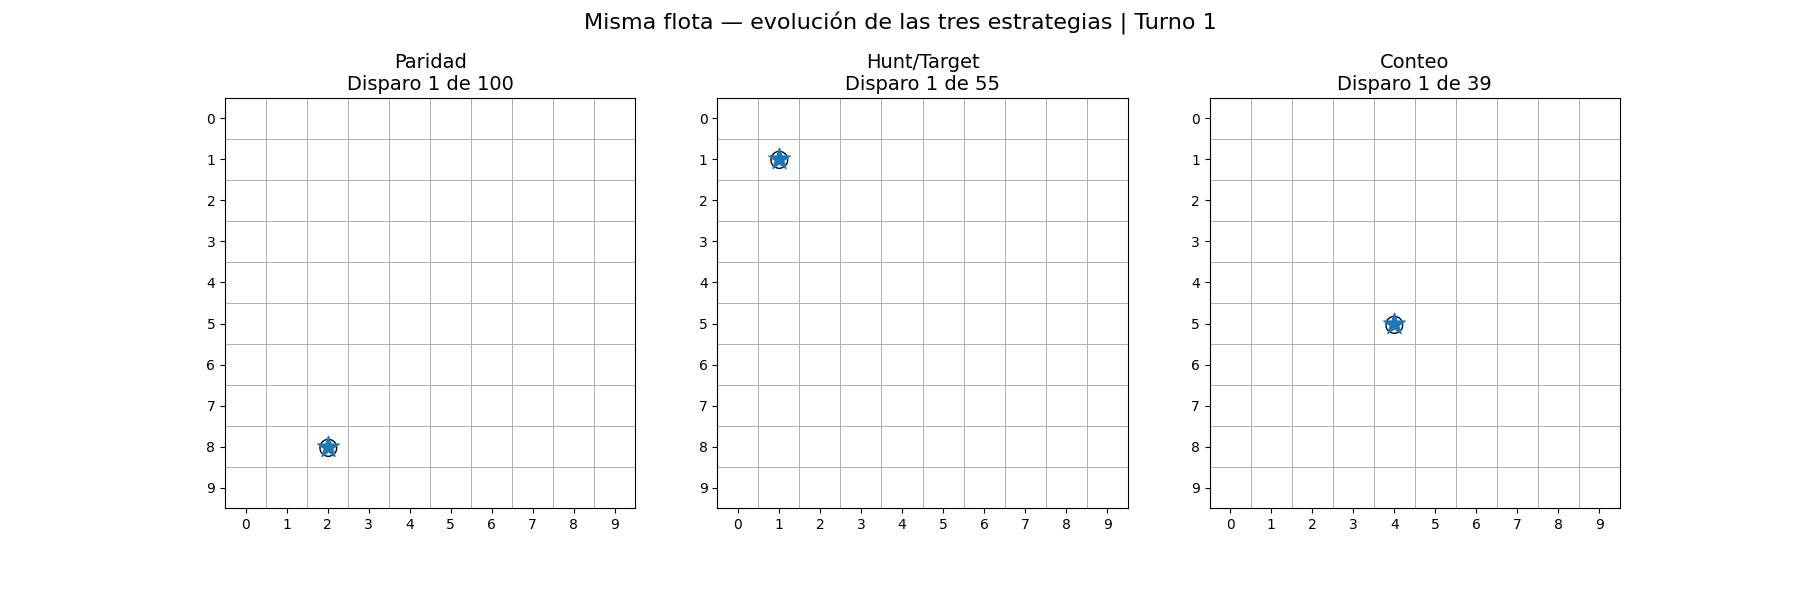

In [ ]:
# ============================================================
# 15.1 EJEMPLO: COMPARACIÓN DE UNA PARTIDA ENTRE LAS TRES ESTRATEGIAS
# ============================================================


flota_comparacion = generar_flota_valida()                                    #Genera una única flota que será compartida por las tres estrategias.

resultado_paridad = simular_partida(                                           #Simula la partida completa utilizando Paridad.
    flota_comparacion,
    "paridad"
)

resultado_ht = simular_partida(                                                #Simula la misma flota utilizando Hunt/Target.
    flota_comparacion,
    "hunt_target"
)

resultado_conteo = simular_partida(                                            #Simula la misma flota utilizando Conteo.
    flota_comparacion,
    "conteo"
)

resultados_comparacion = [                                                     #Agrupa los tres resultados para construir la animación.
    resultado_paridad,
    resultado_ht,
    resultado_conteo
]

nombres_comparacion = [                                                        #Define los nombres que aparecerán sobre cada tablero.
    "Paridad",
    "Hunt/Target",
    "Conteo"
]

maximo_disparos = max(                                                         #Obtiene la duración de la partida más larga.
    resultado["total_disparos"]
    for resultado in resultados_comparacion
)


fig, axes = plt.subplots(1, 3, figsize=(18, 6))                                #Crea un tablero independiente para cada estrategia.


def actualizar_comparacion(frame):                                             #Actualiza únicamente la representación visual de cada turno.

    numero_disparos = frame + 1                                                #Convierte el número del fotograma en cantidad de disparos mostrados.

    for ax, nombre, resultado in zip(                                          #Recorre simultáneamente las tres estrategias.
        axes,
        nombres_comparacion,
        resultados_comparacion
    ):

        ax.clear()                                                             #Limpia el tablero antes de dibujar el siguiente fotograma.

        historial = resultado["historial"]                                     #Obtiene el historial real generado por simular_partida().
        disparos_mostrados = historial[:numero_disparos]                       #Conserva únicamente los disparos realizados hasta este fotograma.

        ax.set_xlim(-0.5, TAMANO_TABLERO - 0.5)                               #Define los límites horizontales del tablero.
        ax.set_ylim(TAMANO_TABLERO - 0.5, -0.5)                               #Define los límites verticales del tablero.
        ax.set_xticks(range(TAMANO_TABLERO))                                   #Muestra las columnas del tablero.
        ax.set_yticks(range(TAMANO_TABLERO))                                   #Muestra las filas del tablero.
        ax.set_xticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)          #Define los límites verticales de las celdas.
        ax.set_yticks(np.arange(-0.5, TAMANO_TABLERO, 1), minor=True)          #Define los límites horizontales de las celdas.
        ax.grid(which="minor", linewidth=0.7)                                  #Dibuja la cuadrícula del tablero.
        ax.tick_params(which="minor", bottom=False, left=False)                #Oculta las marcas auxiliares.
        ax.set_aspect("equal")                                                 #Mantiene las celdas cuadradas.

        for disparo in disparos_mostrados:                                     #Recorre los disparos ya realizados por la estrategia.

            fila, columna = disparo["celda"]                                   #Obtiene la posición disparada.
            resultado_disparo = disparo["resultado"]                           #Obtiene el resultado real devuelto por disparar().

            if resultado_disparo == "agua":                                    #Comprueba si el disparo fue agua.
                simbolo = "○"                                                  #Define el símbolo utilizado para agua.
                tamano = 17                                                    #Define el tamaño del símbolo.

            elif resultado_disparo == "tocado":                                #Comprueba si el disparo produjo un impacto.
                simbolo = "X"                                                  #Define el símbolo utilizado para un impacto.
                tamano = 17                                                    #Define el tamaño del símbolo.

            else:                                                              #Ejecuta este caso cuando el resultado fue hundido.
                simbolo = "■"                                                  #Define el símbolo utilizado para el disparo que hundió el barco.
                tamano = 16                                                    #Define el tamaño del símbolo.

            ax.text(                                                           #Representa el resultado del disparo sobre el tablero.
                columna,
                fila,
                simbolo,
                ha="center",
                va="center",
                fontsize=tamano,
                fontweight="bold" if resultado_disparo != "agua" else "normal"
            )

        if numero_disparos <= len(historial):                                  #Comprueba si la estrategia todavía estaba jugando en este fotograma.

            fila_actual, columna_actual = historial[                           #Obtiene la celda correspondiente al disparo actual.
                numero_disparos - 1
            ]["celda"]

            ax.scatter(                                                        #Destaca con una estrella el disparo realizado en el turno actual.
                columna_actual,
                fila_actual,
                marker="*",
                s=260,
                zorder=5
            )

            ax.set_title(                                                      #Muestra el progreso actual de la estrategia.
                f"{nombre}\n"
                f"Disparo {numero_disparos} de {resultado['total_disparos']}",
                fontsize=14
            )

        else:                                                                  #Ejecuta este caso cuando la estrategia ya terminó su partida.

            ax.set_title(                                                      #Mantiene visible el resultado final mientras las demás continúan.
                f"{nombre}\n"
                f"FINALIZADA — {resultado['total_disparos']} disparos",
                fontsize=14
            )


    fig.suptitle(                                                              #Muestra el número de turno global de la comparación.
        f"Misma flota — evolución de las tres estrategias | Turno {numero_disparos}",
        fontsize=16
    )


animacion_comparacion = FuncAnimation(                                         #Construye la animación a partir de los historiales reales.
    fig,
    actualizar_comparacion,
    frames=maximo_disparos,
    interval=300,
    repeat=True
)


animacion_comparacion.save(                                                    #Guarda la comparación como archivo GIF.
    "comparacion_estrategias.gif",
    writer=PillowWriter(fps=3)
)


plt.close(fig)                                                                 #Evita mostrar adicionalmente una figura estática.

display(Image(filename="comparacion_estrategias.gif"))

## 16. Benchmark inicial de tiempo por estrategia

En esta sección se realiza una medición preliminar del costo computacional asociado a cada estrategia.

El objetivo es estimar cuánto tiempo requiere, en promedio, completar una partida utilizando Paridad, Hunt/Target y Conteo, antes de ejecutar experimentos de Monte Carlo de mayor tamaño.

Para cada estrategia se simula un conjunto reducido de partidas independientes y se registran dos métricas principales:

- el tiempo promedio de ejecución por partida;
- el número promedio de disparos necesarios para hundir toda la flota.

Esta medición permite hacer el diagnóstico de si alguna estrategia presenta un costo computacional significativamente mayor y evaluar si es necesario optimizar su implementación antes de escalar el número de simulaciones.


In [ ]:
# ============================================================
# 16. ENCHMARK INICIAL DE TIEMPO POR ESTRATEGIA
# ============================================================

NUM_PARTIDAS_BENCHMARK = 100                                                    #Define un número "pequeño" de partidas para medir rendimiento.


for estrategia in ["paridad", "hunt_target", "conteo"]:                         #Recorre las tres estrategias implementadas.

    tiempo_inicio = time.perf_counter()                                         #Registra el instante de inicio de la medición.

    disparos_partidas = []                                                      #Inicializa una lista para guardar los disparos de cada partida.

    for _ in range(NUM_PARTIDAS_BENCHMARK):                                     #Ejecuta varias partidas para obtener una medición estable.

        flota_prueba = generar_flota_valida()                                   #Genera una nueva flota válida para cada partida.

        resultado = simular_partida(                                            #Simula una partida completa utilizando la estrategia evaluada.
            flota_prueba,
            estrategia
        )

        disparos_partidas.append(resultado["total_disparos"])                   #Guarda el número total de disparos requeridos.

    tiempo_total = time.perf_counter() - tiempo_inicio                          #Calcula el tiempo total empleado por la estrategia.

    tiempo_promedio = tiempo_total / NUM_PARTIDAS_BENCHMARK                    #Calcula el tiempo promedio por partida.

    promedio_disparos = sum(disparos_partidas) / NUM_PARTIDAS_BENCHMARK        #Calcula el promedio de disparos utilizado.

    print(f"\nEstrategia: {estrategia}")                                        #Muestra el nombre de la estrategia evaluada.
    print(f"Tiempo total: {tiempo_total:.4f} s")                                #Muestra el tiempo requerido para todas las partidas.
    print(f"Tiempo promedio por partida: {tiempo_promedio:.6f} s")              #Muestra el costo computacional promedio por partida.
    print(f"Promedio de disparos: {promedio_disparos:.2f}")                     #Muestra el desempeño promedio preliminar.


Estrategia: paridad
Tiempo total: 0.5396 s
Tiempo promedio por partida: 0.005396 s
Promedio de disparos: 96.31

Estrategia: hunt_target
Tiempo total: 0.1931 s
Tiempo promedio por partida: 0.001931 s
Promedio de disparos: 51.78

Estrategia: conteo
Tiempo total: 2.9208 s
Tiempo promedio por partida: 0.029208 s
Promedio de disparos: 46.45


# 17. Simulación de Monte Carlo para la comparación de estrategias

En esta sección se implementa el procedimiento de simulación utilizado para comparar el desempeño de las estrategias consideradas en el proyecto.

Cada repetición del experimento parte de una configuración válida de la flota generada aleatoriamente. Sobre esa misma configuración se ejecutan las estrategias de Paridad, Hunt/Target y Conteo, de manera que todas enfrenten exactamente el mismo escenario.

Este diseño permite controlar la variabilidad asociada a la ubicación de los barcos y hace que las diferencias observadas entre estrategias puedan atribuirse principalmente a la política de selección de disparos.

Para cada partida se registra como variable principal de respuesta el número total de disparos necesarios para hundir completamente la flota.

El procedimiento se repite un número determinado de veces, generando así una muestra de resultados para cada estrategia. Esta información será utilizada posteriormente para calcular estadísticas descriptivas, comparar distribuciones y realizar las pruebas estadísticas definidas en el análisis experimental.

La utilización de una semilla aleatoria permite reproducir exactamente las configuraciones generadas y, por tanto, repetir el experimento bajo las mismas condiciones.

In [ ]:
# ============================================================
# 17. SIMULACIÓN DE MONTE CARLO PARA LA COMPARACIÓN DE ESTRATEGIAS
# ============================================================


ESTRATEGIAS = ["paridad", "hunt_target", "conteo"]                              #Define las estrategias que serán comparadas.


def ejecutar_simulacion_montecarlo(numero_partidas, semilla=42):              #Ejecuta la simulación de Monte Carlo utilizando la misma flota para todas las estrategias.
    random.seed(semilla)                                                        #Fija la semilla para poder reproducir exactamente el experimento.

    resultados = []                                                             #Inicializa la estructura donde se almacenará cada observación.

    for id_partida in range(numero_partidas):                                   #Recorre cada escenario independiente del experimento.

        flota_base = generar_flota_valida()                                     #Genera una única flota que compartirán las tres estrategias.

        for estrategia in ESTRATEGIAS:                                          #Evalúa cada estrategia sobre exactamente la misma flota.

            flota_estrategia = copy.deepcopy(flota_base)                        #Crea una copia independiente para evitar contaminación entre estrategias.

            resultado = simular_partida(                                        #Ejecuta una partida completa.
                flota_estrategia,
                estrategia
            )

            resultados.append({                                                 #Guarda la observación correspondiente a esta estrategia y escenario.
                "id_partida": id_partida,                                       #Identifica el escenario común utilizado por las estrategias.
                "estrategia": estrategia,                                       #Identifica la estrategia evaluada.
                "total_disparos": resultado["total_disparos"]                   #Guarda la variable principal de respuesta de la tesis.
            })

    return pd.DataFrame(resultados)                                             #Devuelve los resultados en formato tabular.

## 18. Validación de la comparabilidad entre estrategias

En esta sección se verifica que la comparación entre estrategias se haya construido bajo condiciones equivalentes.

Para ello se comprueba que cada configuración de flota haya sido evaluada por todas las estrategias consideradas y que cada una disponga del mismo número de observaciones.

Posteriormente, los resultados se reorganizan de manera que cada fila represente una misma configuración de flota y cada columna corresponda a una estrategia distinta. Esta estructura permite comparar directamente el número de disparos requeridos por cada política sobre exactamente el mismo escenario.

A partir de esta organización se calculan diferencias entre estrategias, en particular:

- Conteo frente a Hunt/Target.
- Conteo frente a Paridad.

Estas diferencias permiten cuantificar, para una misma configuración de barcos, cuánto cambia el número de disparos requerido al utilizar una estrategia en lugar de otra.

Esta validación es importante porque garantiza que las comparaciones posteriores no mezclen escenarios distintos y que las diferencias observadas reflejen realmente el comportamiento de las estrategias.

In [ ]:
# ============================================================
# 18 SIMULACIÓN PILOTO
# ============================================================

N_PILOTO = 100                                                                 #Número de configuraciones utilizadas en la simulación piloto.

resultados_piloto = ejecutar_simulacion_montecarlo(                            #Ejecuta una simulación preliminar para estimar variabilidad y validar el diseño.
    numero_partidas=N_PILOTO,                                                  #Utiliza un número reducido de configuraciones antes de la simulación definitiva.
    semilla=42                                                                 #Semilla.
)

resumen_piloto = resultados_piloto.groupby(                                    #Agrupa los resultados según la estrategia utilizada.
    "estrategia"
)["total_disparos"].agg(                                                       #Resume la variable principal de respuesta.
    ["count", "mean", "std", "min", "max"]
)

resumen_piloto                                                                  #Muestra las estadísticas descriptivas de la simulación piloto.

,count,mean,std,min,max
estrategia,,,,,
conteo,100,45.54,8.727548,26,67
hunt_target,100,53.18,7.600346,37,66
paridad,100,95.24,4.826526,73,100


In [ ]:
# ============================================================
# 18.1 Validación de la comparabilidad entre estrategias
# ============================================================

conteo_por_partida = resultados_piloto.groupby("id_partida")["estrategia"].nunique()           #Cuenta cuántas estrategias fueron evaluadas en cada escenario.

assert conteo_por_partida.eq(len(ESTRATEGIAS)).all()                                           #Comprueba que cada flota haya sido evaluada por las tres estrategias.


conteo_por_estrategia = resultados_piloto["estrategia"].value_counts()                          #Cuenta cuántas observaciones tiene cada estrategia.

assert conteo_por_estrategia.nunique() == 1                                                     #Comprueba que todas las estrategias tengan exactamente el mismo número de partidas.


resultados_pareados = resultados_piloto.pivot(                                                  #Transforma los resultados para dejar una fila por flota.
    index="id_partida",                                                                          #Utiliza el identificador de partida como unidad experimental.
    columns="estrategia",                                                                        #Coloca cada estrategia en una columna diferente.
    values="total_disparos"                                                                      #Utiliza el número de disparos como variable de respuesta.
)


resultados_pareados["conteo_vs_hunt_target"] = (                                                #Calcula la diferencia pareada entre Conteo y Hunt/Target.
    resultados_pareados["conteo"]
    - resultados_pareados["hunt_target"]
)

resultados_pareados["conteo_vs_paridad"] = (                                                    #Calcula la diferencia pareada entre Conteo y Paridad.
    resultados_pareados["conteo"]
    - resultados_pareados["paridad"]
)


print("Número de escenarios:", len(resultados_pareados))                                        #Muestra el número total de flotas comparadas.

print(
    "\nDiferencia promedio Conteo - Hunt/Target:",
    resultados_pareados["conteo_vs_hunt_target"].mean()
)                                                                                               #Muestra cuánto cambia en promedio el número de disparos frente a Hunt/Target.

print(
    "Diferencia promedio Conteo - Paridad:",
    resultados_pareados["conteo_vs_paridad"].mean()
)                                                                                               #Muestra cuánto cambia en promedio el número de disparos frente a Paridad.

print("\nDiseño pareado validado correctamente.")                                               #Confirma que el experimento conserva el emparejamiento.

Número de escenarios: 100

Diferencia promedio Conteo - Hunt/Target: -7.64
Diferencia promedio Conteo - Paridad: -49.7

Diseño pareado validado correctamente.


## 19. Determinación del tamaño de simulación $N_{\text{sim}}$

En esta sección se determina el número de simulaciones necesarias para ejecutar el experimento definitivo con un nivel de precisión previamente establecido.

A partir de los resultados obtenidos en una muestra piloto, se estima la desviación estándar del número de disparos para cada estrategia. Con esta información se calcula el tamaño de muestra requerido para estimar la media con un nivel de confianza del $95\%$ y un error máximo admisible de $0.25$ disparos.

El tamaño requerido para cada estrategia se obtiene mediante

$$
N=\left(\frac{z_{0.975}\,\sigma}{E}\right)^2,
$$

donde $\sigma$ corresponde a la desviación estándar estimada en la prueba piloto, $E$ es el error máximo permitido y $z_{0.975}=1.96$ es el valor crítico asociado a un intervalo de confianza del $95\%$.

Como todas las estrategias deben ser evaluadas sobre el mismo número de configuraciones, se selecciona como $N_{\text{sim}}$ el mayor tamaño calculado entre ellas.

De esta manera, el número de simulaciones del experimento final se establece mediante un criterio de precisión estadística y no de forma arbitraria.

In [ ]:
# ============================================================
# 19. DETERMINACIÓN DEL TAMAÑO DE SIMULACIÓN N_sim
# ============================================================



ERROR_OBJETIVO = 0.25                                                           #error máximo deseado en disparos para estimar la media.

Z_95 = 1.96                                                                     #valor crítico aproximado para un nivel de confianza del 95 %.


desviaciones = resultados_piloto.groupby("estrategia")["total_disparos"].std() #Calcula la desviación estándar piloto de cada estrategia.


n_requeridos = (                                                                #Calcula el tamaño requerido para cada estrategia.
    (Z_95 * desviaciones / ERROR_OBJETIVO) ** 2
).apply(math.ceil)                                                               #Redondea cada tamaño hacia arriba.


N_sim = int(n_requeridos.max())                                                  #Selecciona el mayor tamaño para garantizar precisión en las tres estrategias.


print("Tamaño requerido por estrategia:")                                       #Muestra los tamaños calculados individualmente.
print(n_requeridos)

print(f"\nN_sim seleccionado: {N_sim}")                                          #Muestra el tamaño definitivo propuesto para el experimento.

Tamaño requerido por estrategia:
estrategia
conteo         4682
hunt_target    3551
paridad        1432
Name: total_disparos, dtype: int64

N_sim seleccionado: 4682


# 20. Simulación de Monte Carlo

En esta sección se ejecuta la simulación principal del estudio utilizando el tamaño $N_{\text{sim}}$ determinado previamente.

Para cada configuración generada se evalúan las estrategias consideradas bajo las mismas condiciones experimentales, registrando como variable principal el número total de disparos necesarios para hundir completamente la flota.

Durante la ejecución también se mide el tiempo total requerido por la simulación, con el fin de disponer de una referencia del costo computacional asociado al experimento completo.

Una vez finalizadas las simulaciones, los resultados se agrupan por estrategia y se calculan estadísticas descriptivas básicas, entre ellas:

- número de observaciones;
- media;
- desviación estándar;
- mediana;
- mínimo;
- máximo.


In [ ]:
# ============================================================
# 20. SIMULACIÓN DE MONTERCARLO
# ============================================================

tiempo_inicio_montecarlo = time.perf_counter()                                  #Registra el instante de inicio del experimento definitivo.

resultados_montecarlo = ejecutar_simulacion_montecarlo(                           #Ejecuta el experimento pareado con el tamaño de simulación calculado.
    numero_partidas=N_sim,                                                      #Utiliza el número de escenarios determinado mediante el estudio piloto.
    semilla=42                                                                  #Fija la semilla para garantizar reproducibilidad.
)

tiempo_total_montecarlo = (                                                     #Calcula el tiempo total requerido por el experimento.
    time.perf_counter() - tiempo_inicio_montecarlo
)

resumen_montecarlo = resultados_montecarlo.groupby(                             #Agrupa los resultados según la estrategia evaluada.
    "estrategia"
)["total_disparos"].agg(                                                        #Resume la variable principal de respuesta.
    ["count", "mean", "std", "median", "min", "max"]
)

print(resumen_montecarlo)                                                       #Muestra las estadísticas descriptivas principales.

print(
    f"\nTiempo total del experimento: "
    f"{tiempo_total_montecarlo:.2f} segundos"
)                                                                                #Muestra el costo computacional total.

             count       mean       std  median  min  max
estrategia                                               
conteo        4682  46.105938  8.845942    46.0   24   72
hunt_target   4682  52.155062  8.210297    53.0   22   68
paridad       4682  95.510679  4.450827    97.0   68  100

Tiempo total del experimento: 106.85 segundos


### 20.1 Visualización final de los resultados de Monte Carlo

La siguiente figura resume gráficamente los resultados obtenidos en el experimento definitivo de Monte Carlo.

La línea horizontal en cero representa igualdad entre las estrategias; valores negativos indican que Conteo necesitó menos disparos en la configuración correspondiente y valores positivos indican que necesitó más.


/tmp/ipykernel_4680/1165576293.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(                                                               #Representa la distribución de disparos de las tres estrategias.
/tmp/ipykernel_4680/1165576293.py:87: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(                                                              #Representa la distribución de las diferencias pareadas.


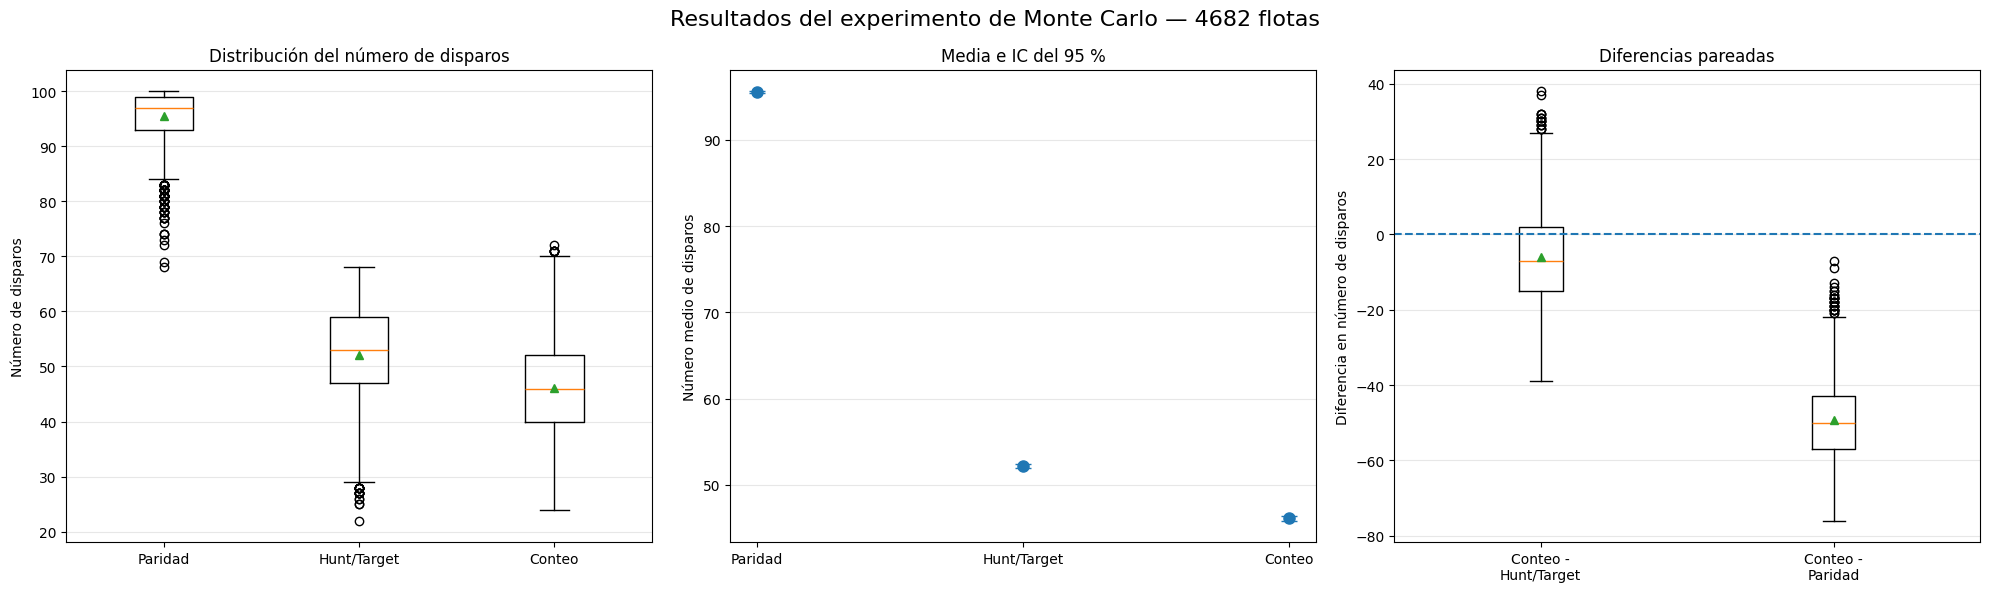

In [ ]:
# ============================================================
# 20.1 VISUALIZACIÓN FINAL DE LOS RESULTADOS DE MONTE CARLO
# ============================================================

resultados_pareados_final = resultados_montecarlo.pivot(                       #Organiza los resultados dejando una fila por flota simulada.
    index="id_partida",
    columns="estrategia",
    values="total_disparos"
)

resultados_pareados_final["conteo_vs_hunt_target"] = (                         #Calcula la diferencia pareada Conteo - Hunt/Target.
    resultados_pareados_final["conteo"]
    - resultados_pareados_final["hunt_target"]
)

resultados_pareados_final["conteo_vs_paridad"] = (                             #Calcula la diferencia pareada Conteo - Paridad.
    resultados_pareados_final["conteo"]
    - resultados_pareados_final["paridad"]
)


fig, axes = plt.subplots(1, 3, figsize=(20, 6))                                #Crea los tres paneles de la visualización final.


# ------------------------------------------------------------
# 1. DISTRIBUCIÓN DEL NÚMERO DE DISPAROS
# ------------------------------------------------------------

datos_boxplot = [                                                              #Organiza los disparos de cada estrategia para construir el boxplot.
    resultados_montecarlo.loc[
        resultados_montecarlo["estrategia"] == estrategia,
        "total_disparos"
    ].values
    for estrategia in ESTRATEGIAS
]

axes[0].boxplot(                                                               #Representa la distribución de disparos de las tres estrategias.
    datos_boxplot,
    labels=["Paridad", "Hunt/Target", "Conteo"],
    showmeans=True
)

axes[0].set_title("Distribución del número de disparos")                       #Define el título del primer panel.
axes[0].set_ylabel("Número de disparos")                                       #Define la variable representada en el eje vertical.
axes[0].grid(axis="y", alpha=0.3)                                              #Agrega una cuadrícula horizontal auxiliar.


# ------------------------------------------------------------
# 2. MEDIA E INTERVALO DE CONFIANZA DEL 95 %
# ------------------------------------------------------------

resumen_visual = resultados_montecarlo.groupby(                               #Calcula las estadísticas necesarias para representar las medias.
    "estrategia"
)["total_disparos"].agg(
    ["mean", "std", "count"]
).reindex(ESTRATEGIAS)

resumen_visual["error_95"] = (                                                 #Calcula el margen de error del intervalo de confianza del 95 %.
    1.96
    * resumen_visual["std"]
    / np.sqrt(resumen_visual["count"])
)

axes[1].errorbar(                                                              #Representa cada media junto con su intervalo de confianza.
    ["Paridad", "Hunt/Target", "Conteo"],
    resumen_visual["mean"],
    yerr=resumen_visual["error_95"],
    fmt="o",
    capsize=6,
    markersize=8
)

axes[1].set_title("Media e IC del 95 %")                                       #Define el título del segundo panel.
axes[1].set_ylabel("Número medio de disparos")                                 #Define la variable representada.
axes[1].grid(axis="y", alpha=0.3)                                              #Agrega una cuadrícula horizontal auxiliar.


# ------------------------------------------------------------
# 3. DIFERENCIAS PAREADAS
# ------------------------------------------------------------

datos_diferencias = [                                                         #Organiza las diferencias obtenidas sobre las mismas flotas.
    resultados_pareados_final["conteo_vs_hunt_target"].values,
    resultados_pareados_final["conteo_vs_paridad"].values
]

axes[2].boxplot(                                                              #Representa la distribución de las diferencias pareadas.
    datos_diferencias,
    labels=[
        "Conteo -\nHunt/Target",
        "Conteo -\nParidad"
    ],
    showmeans=True
)

axes[2].axhline(0, linestyle="--", linewidth=1.5)                              #Marca el punto donde ambas estrategias requieren los mismos disparos.
axes[2].set_title("Diferencias pareadas")                                     #Define el título del tercer panel.
axes[2].set_ylabel("Diferencia en número de disparos")                        #Define la interpretación del eje vertical.
axes[2].grid(axis="y", alpha=0.3)                                             #Agrega una cuadrícula horizontal auxiliar.


plt.suptitle(                                                                 #Define el título general de la comparación experimental.
    f"Resultados del experimento de Monte Carlo — {N_sim} flotas",
    fontsize=16
)

plt.tight_layout()                                                            #Ajusta automáticamente el espacio entre los paneles.
plt.show()                                                                     #Muestra la visualización final.

# 21. Análisis estadístico comparativo

En esta sección se comparan los resultados obtenidos por las estrategias utilizando el carácter emparejado del diseño experimental.

Dado que las tres estrategias se ejecutan sobre las mismas configuraciones de flota, es posible comparar directamente su desempeño partida por partida. Para dos estrategias $A$ y $B$, se define la diferencia:

$$
\Delta_i^{(A,B)} = T_i^{(A)} - T_i^{(B)}
$$

donde $T_i^{(A)}$ y $T_i^{(B)}$ representan el número de disparos requeridos por cada estrategia sobre la misma configuración $i$.

La diferencia media se calcula mediante:

$$
\overline{\Delta}^{(A,B)}
=
\frac{1}{N_{\mathrm{sim}}}
\sum_{i=1}^{N_{\mathrm{sim}}}
\Delta_i^{(A,B)}
$$

Si $\overline{\Delta}^{(A,B)} < 0$, la estrategia $A$ requiere en promedio menos disparos que la estrategia $B$. Si es positiva, ocurre lo contrario.

Para cuantificar la incertidumbre asociada a esta diferencia se construye un intervalo de confianza del 95 %:

$$
\overline{\Delta}
\pm
t_{0.975,N_{\mathrm{sim}}-1}
\frac{s_{\Delta}}{\sqrt{N_{\mathrm{sim}}}}
$$

donde $s_{\Delta}$ corresponde a la desviación estándar de las diferencias observadas.

También se calcula directamente el ahorro promedio de disparos obtenido por Conteo de Encajes Consistentes respecto de cada estrategia de referencia:

$$
A_i^{(B)}
=
T_i^{(B)}
-
T_i^{(\mathrm{Conteo})}
$$

Un valor positivo representa un ahorro de disparos a favor de Conteo.

De esta manera, la comparación no se limita a observar las medias generales de las estrategias, sino que permite cuantificar la magnitud, variabilidad e incertidumbre de las diferencias observadas bajo exactamente las mismas configuraciones de flota.

In [ ]:
# ============================================================
# 21.ANÁLISIS ESTADÍSTICO COMPARATIVO
# ============================================================


resultados_pareados_final = resultados_montecarlo.pivot(                      # Deja una fila por configuración de flota.
    index="id_partida",                                                       # Utiliza cada flota como unidad experimental.
    columns="estrategia",                                                     # Coloca cada estrategia en una columna.
    values="total_disparos"                                                   # Número total de disparos requeridos.
)


comparaciones = [                                                             # Define las comparaciones entre estrategias.
    ("conteo", "hunt_target"),
    ("conteo", "paridad"),
    ("hunt_target", "paridad")
]


print("COMPARACIONES EMPAREJADAS ENTRE ESTRATEGIAS")


for estrategia_a, estrategia_b in comparaciones:                              # Recorre cada par de estrategias.

    diferencias = (                                                           # Calcula Δ_i^(A,B) para cada configuración.
        resultados_pareados_final[estrategia_a]
        - resultados_pareados_final[estrategia_b]
    )

    n = len(diferencias)                                                      # Número de configuraciones comparadas.

    diferencia_media = diferencias.mean()                                     # Calcula la diferencia media Δ̄.

    desviacion_diferencias = diferencias.std(ddof=1)                          # Calcula s_Δ.

    error_estandar = desviacion_diferencias / np.sqrt(n)                      # Error estándar de la diferencia media.

    t_critico = t.ppf(0.975, df=n - 1)                                        # Valor crítico para un IC del 95 %.

    limite_inferior = diferencia_media - t_critico * error_estandar           # Límite inferior del IC 95 %.

    limite_superior = diferencia_media + t_critico * error_estandar           # Límite superior del IC 95 %.


    print(f"\n{estrategia_a} vs {estrategia_b}")

    print(
        f"Diferencia media (A - B): "
        f"{diferencia_media:.4f} disparos"
    )

    print(
        f"Desviación estándar de las diferencias: "
        f"{desviacion_diferencias:.4f}"
    )

    print(
        f"IC 95 % de la diferencia media: "
        f"[{limite_inferior:.4f}, {limite_superior:.4f}]"
    )


# ============================================================
# AHORRO PROMEDIO DE CONTEO
# ============================================================

print("\nAHORRO PROMEDIO DE CONTEO")


for estrategia_referencia in ["hunt_target", "paridad"]:

    ahorro = (                                                                # Calcula A_i^(B) = T_i^(B) - T_i^(Conteo).
        resultados_pareados_final[estrategia_referencia]
        - resultados_pareados_final["conteo"]
    )

    ahorro_medio = ahorro.mean()                                              # Número promedio de disparos ahorrados.

    print(
        f"Conteo frente a {estrategia_referencia}: "
        f"{ahorro_medio:.4f} disparos ahorrados en promedio"
    )

COMPARACIONES EMPAREJADAS ENTRE ESTRATEGIAS

conteo vs hunt_target
Diferencia media (A - B): -6.0491 disparos
Desviación estándar de las diferencias: 12.0040
IC 95 % de la diferencia media: [-6.3931, -5.7052]

conteo vs paridad
Diferencia media (A - B): -49.4047 disparos
Desviación estándar de las diferencias: 10.0104
IC 95 % de la diferencia media: [-49.6916, -49.1179]

hunt_target vs paridad
Diferencia media (A - B): -43.3556 disparos
Desviación estándar de las diferencias: 9.2616
IC 95 % de la diferencia media: [-43.6210, -43.0903]

AHORRO PROMEDIO DE CONTEO
Conteo frente a hunt_target: 6.0491 disparos ahorrados en promedio
Conteo frente a paridad: 49.4047 disparos ahorrados en promedio


## 22. Intervalos de confianza y tamaño del efecto

En esta sección se complementan las pruebas de significancia estadística con medidas que permitan cuantificar la magnitud de las diferencias observadas entre estrategias.

Para cada comparación se calcula la diferencia de disparos partida a partida sobre las mismas configuraciones de flota. A partir de estas diferencias se estima su media y se construye un intervalo de confianza del $95\%$.

El intervalo se obtiene mediante

$$
\bar{d} \pm t_{0.975,n-1}\frac{s_d}{\sqrt{n}},
$$

donde $\bar{d}$ es la diferencia media, $s_d$ es la desviación estándar de las diferencias y $n$ es el número de escenarios comparados.

Además, se calcula un tamaño del efecto estandarizado para datos pareados:

$$
d=\frac{\bar{d}}{s_d}.
$$

Esta medida permite expresar la magnitud de la diferencia entre estrategias en unidades de desviación estándar, complementando la información proporcionada por los valores $p$.

De esta manera, el análisis no se limita a establecer si existe una diferencia estadísticamente significativa, sino que también permite evaluar cuán grande es dicha diferencia en términos prácticos.

In [ ]:
# ============================================================
# 22. INTERVALOS DE CONFIANZA Y TAMAÑO DEL EFECTO
# ============================================================

def resumen_diferencia_pareada(serie_1, serie_2, nombre_1, nombre_2):           #Resume una diferencia pareada entre dos estrategias.

    diferencias = serie_1 - serie_2                                             #Calcula la diferencia partida a partida entre ambas estrategias.

    n = len(diferencias)                                                        #Obtiene el número total de pares comparados.

    media_diferencia = diferencias.mean()                                       #Calcula la diferencia media en disparos.

    desviacion_diferencia = diferencias.std(ddof=1)                             #Calcula la desviación estándar de las diferencias pareadas.

    error_estandar = desviacion_diferencia / np.sqrt(n)                         #Calcula el error estándar de la diferencia media.

    t_critico = t.ppf(0.975, df=n - 1)                                          #Obtiene el valor crítico para un intervalo de confianza del 95 %.

    limite_inferior = media_diferencia - t_critico * error_estandar             #Calcula el límite inferior del intervalo de confianza.

    limite_superior = media_diferencia + t_critico * error_estandar             #Calcula el límite superior del intervalo de confianza.

    d_pareado = media_diferencia / desviacion_diferencia                        #Calcula el tamaño del efecto estandarizado para datos pareados.

    print(f"\n{nombre_1} vs {nombre_2}")                                        #Muestra las estrategias que están siendo comparadas.

    print(f"Diferencia media: {media_diferencia:.4f} disparos")                 #Muestra la magnitud promedio de la diferencia.

    print(
        f"IC 95 %: [{limite_inferior:.4f}, {limite_superior:.4f}]"
    )                                                                           #Muestra el intervalo de confianza de la diferencia media.

    print(f"d pareado: {d_pareado:.4f}")                                        #Muestra el tamaño del efecto estandarizado.


resumen_diferencia_pareada(                                                     #Compara Conteo frente a Hunt/Target.
    resultados_pareados_final["conteo"],
    resultados_pareados_final["hunt_target"],
    "conteo",
    "hunt_target"
)

resumen_diferencia_pareada(                                                     #Compara Conteo frente a Paridad.
    resultados_pareados_final["conteo"],
    resultados_pareados_final["paridad"],
    "conteo",
    "paridad"
)

resumen_diferencia_pareada(                                                     #Compara Hunt/Target frente a Paridad.
    resultados_pareados_final["hunt_target"],
    resultados_pareados_final["paridad"],
    "hunt_target",
    "paridad"
)


conteo vs hunt_target
Diferencia media: -6.0491 disparos
IC 95 %: [-6.3931, -5.7052]
d pareado: -0.5039

conteo vs paridad
Diferencia media: -49.4047 disparos
IC 95 %: [-49.6916, -49.1179]
d pareado: -4.9353

hunt_target vs paridad
Diferencia media: -43.3556 disparos
IC 95 %: [-43.6210, -43.0903]
d pareado: -4.6812


## 23. Reducción porcentual promedio de disparos

En esta sección se expresa la diferencia de desempeño entre estrategias en términos relativos, utilizando como referencia el número promedio de disparos requerido por cada una.

Para dos estrategias $A$ y $B$, donde $B$ se utiliza como referencia, la reducción porcentual se calcula mediante

$$
\text{Reducción porcentual}
=
\frac{\bar{x}_B-\bar{x}_A}{\bar{x}_B}\times 100,
$$

donde $\bar{x}_A$ y $\bar{x}_B$ representan el número promedio de disparos de cada estrategia.

Se calculan las reducciones correspondientes a:

- Conteo frente a Hunt/Target.
- Conteo frente a Paridad.
- Hunt/Target frente a Paridad.

Esta medida complementa las diferencias absolutas en número de disparos y facilita la interpretación práctica de la mejora obtenida por una estrategia respecto a otra.

Un valor positivo indica que la primera estrategia requiere, en promedio, un menor número de disparos que la estrategia utilizada como referencia.

In [ ]:
# ============================================================
# 23. REDUCCIÓN PORCENTUAL PROMEDIO DE DISPAROS
# ============================================================

media_conteo = resultados_pareados_final["conteo"].mean()                                      #Calcula el promedio de disparos de la estrategia Conteo.

media_hunt_target = resultados_pareados_final["hunt_target"].mean()                            #Calcula el promedio de disparos de Hunt/Target.

media_paridad = resultados_pareados_final["paridad"].mean()                                    #Calcula el promedio de disparos de Paridad.


reduccion_conteo_vs_hunt = (                                                                    #Calcula la reducción porcentual de Conteo respecto a Hunt/Target.
    (media_hunt_target - media_conteo)
    / media_hunt_target
) * 100


reduccion_conteo_vs_paridad = (                                                                 #Calcula la reducción porcentual de Conteo respecto a Paridad.
    (media_paridad - media_conteo)
    / media_paridad
) * 100


reduccion_hunt_vs_paridad = (                                                                   #Calcula la reducción porcentual de Hunt/Target respecto a Paridad.
    (media_paridad - media_hunt_target)
    / media_paridad
) * 100


print(f"Conteo vs Hunt/Target: {reduccion_conteo_vs_hunt:.2f} % menos disparos")                #Muestra la mejora relativa de Conteo frente a Hunt/Target.

print(f"Conteo vs Paridad: {reduccion_conteo_vs_paridad:.2f} % menos disparos")                 #Muestra la mejora relativa de Conteo frente a Paridad.

print(f"Hunt/Target vs Paridad: {reduccion_hunt_vs_paridad:.2f} % menos disparos")              #Muestra la mejora relativa de Hunt/Target frente a Paridad.

Conteo vs Hunt/Target: 11.60 % menos disparos
Conteo vs Paridad: 51.73 % menos disparos
Hunt/Target vs Paridad: 45.39 % menos disparos


## 23.1 Tabla resumen final de resultados

En esta sección se consolidan las principales estadísticas descriptivas obtenidas en la simulación de Monte Carlo para cada estrategia.

Para cada política se reportan:

- número total de simulaciones;
- media del número de disparos;
- desviación estándar;
- mediana;
- mínimo;
- máximo.

Además, se incluyen dos medidas relativas de desempeño: la reducción porcentual de disparos respecto a Paridad y la reducción porcentual respecto a Hunt/Target.

Esta tabla permite reunir en una sola vista los resultados más importantes del experimento y facilita la comparación directa entre las estrategias.

La estrategia con menor media de disparos presenta un mejor desempeño en términos de eficiencia de búsqueda, mientras que las reducciones porcentuales permiten interpretar la magnitud de esa mejora respecto a las estrategias de referencia.

In [ ]:
# ============================================================
# 23.1 TABLA RESUMEN FINAL DE RESULTADOS
# ============================================================

tabla_resumen_final = resultados_montecarlo.groupby("estrategia")[              #Agrupa los resultados por estrategia.
    "total_disparos"
].agg(
    n="count",                                                                  #Cuenta el número de partidas simuladas.
    media="mean",                                                               #Calcula el promedio de disparos.
    desviacion="std",                                                           #Calcula la desviación estándar.
    mediana="median",                                                           #Calcula la mediana de disparos.
    minimo="min",                                                               #Obtiene el mínimo número de disparos.
    maximo="max"                                                                #Obtiene el máximo número de disparos.
).reset_index()


tabla_resumen_final["reduccion_vs_paridad_%"] = (                               #Calcula la reducción porcentual respecto a Paridad.
    (media_paridad - tabla_resumen_final["media"])
    / media_paridad
) * 100


tabla_resumen_final["reduccion_vs_hunt_target_%"] = (                           #Calcula la reducción porcentual respecto a Hunt/Target.
    (media_hunt_target - tabla_resumen_final["media"])
    / media_hunt_target
) * 100


tabla_resumen_final = tabla_resumen_final.round(2)                              #Redondea las métricas para facilitar su lectura.


tabla_resumen_final                                                             #Muestra la tabla resumen final.

,estrategia,n,media,desviacion,mediana,minimo,maximo,reduccion_vs_paridad_%,reduccion_vs_hunt_target_%
0,conteo,4682,46.11,8.85,46.0,24,72,51.73,11.60
1,hunt_target,4682,52.16,8.21,53.0,22,68,45.39,0.00
2,paridad,4682,95.51,4.45,97.0,68,100,0.00,-83.13


## 24.Distribución del número de disparos por estrategia

En esta sección se comparan las distribuciones del número total de disparos requeridos por cada estrategia.



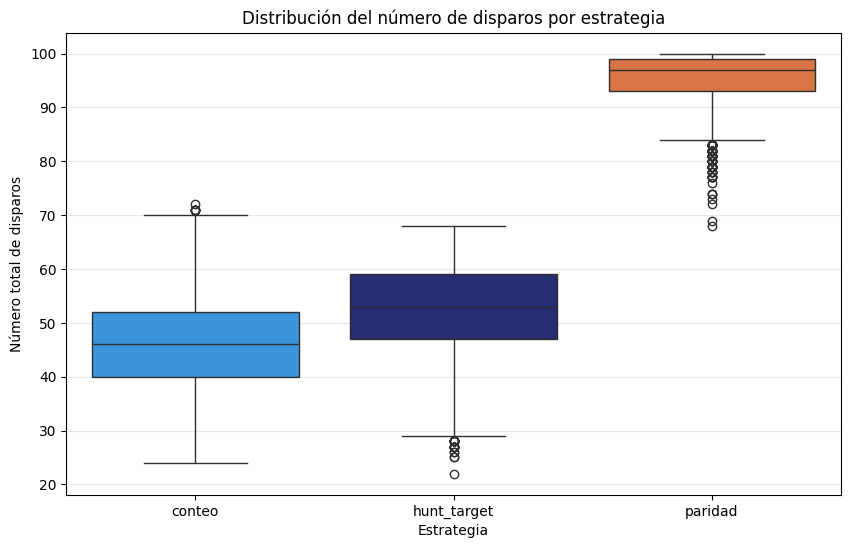

In [ ]:
# ============================================================
# 24. GRÁFICO DE DISTRIBUCIÓN DE DISPAROS POR ESTRATEGIA
# ============================================================

plt.figure(figsize=(10, 6))                                                    # Crea el área donde se dibujará el gráfico.

colores = {
    "conteo": "#2196F3",                                                       # Azul claro.
    "hunt_target": "#1A237E",                                                  # Azul oscuro.
    "paridad": "#F26B2B"                                                       # Naranja.
}

sns.boxplot(                                                                   # Construye un diagrama de cajas para comparar las distribuciones.
    data=resultados_montecarlo,                                                # Utiliza los resultados completos del experimento.
    x="estrategia",                                                            # Coloca cada estrategia como categoría en el eje horizontal.
    y="total_disparos",                                                        # Utiliza el número de disparos como variable analizada.
    order=["conteo", "hunt_target", "paridad"],                                # Mantiene el mismo orden visual.
    palette=colores,                                                           # Asigna un color específico a cada estrategia.
    hue="estrategia",
    legend=False
)

plt.title("Distribución del número de disparos por estrategia")                 # Define el título principal del gráfico.

plt.xlabel("Estrategia")                                                       # Define la etiqueta del eje horizontal.

plt.ylabel("Número total de disparos")                                         # Define la etiqueta del eje vertical.

plt.grid(axis="y", alpha=0.3)                                                  # Añade una cuadrícula horizontal para facilitar la comparación.

plt.show()                                                                     # Muestra el gráfico.

## 25. Promedio de disparos por estrategia con intervalo de confianza del 95 %

En esta sección se compara el número promedio de disparos requerido por cada estrategia, incorporando además un intervalo de confianza del $95\%$ para cada media estimada.

Para cada estrategia se calcula la media, la desviación estándar, el error estándar y el correspondiente margen de error. El intervalo de confianza se construye mediante la distribución $t$ de Student, utilizando

$$
\bar{x} \pm t_{0.975,n-1}\frac{s}{\sqrt{n}},
$$

donde $\bar{x}$ representa la media del número de disparos, $s$ la desviación estándar y $n$ el número de simulaciones.

La representación gráfica permite comparar directamente las medias obtenidas por Conteo, Hunt/Target y Paridad, mostrando al mismo tiempo la incertidumbre asociada a cada estimación.



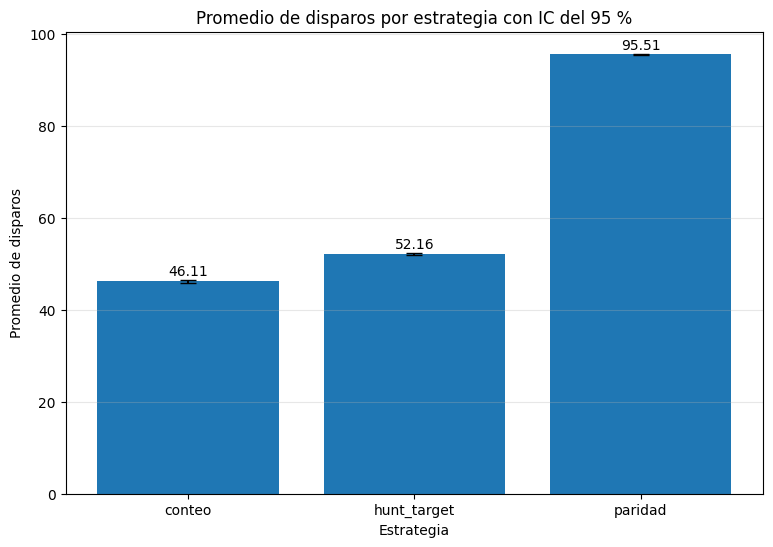

In [ ]:
# ============================================================
# 25. GRÁFICO DE MEDIA DE DISPAROS CON IC DEL 95 %
# ============================================================


resumen_grafico = resultados_montecarlo.groupby("estrategia")[                  #Agrupa las partidas según la estrategia utilizada.
    "total_disparos"
].agg(
    media="mean",                                                               #Calcula el promedio de disparos.
    desviacion="std",                                                           #Calcula la desviación estándar.
    n="count"                                                                   #Cuenta el número de partidas simuladas.
).reset_index()


resumen_grafico["error_estandar"] = (                                           #Calcula el error estándar de la media para cada estrategia.
    resumen_grafico["desviacion"]
    / np.sqrt(resumen_grafico["n"])
)


resumen_grafico["t_critico"] = resumen_grafico["n"].apply(                      #Calcula el valor crítico correspondiente al IC del 95 %.
    lambda n: t.ppf(0.975, df=n - 1)
)


resumen_grafico["margen_error"] = (                                             #Calcula el margen de error del intervalo de confianza.
    resumen_grafico["t_critico"]
    * resumen_grafico["error_estandar"]
)


orden_estrategias = [                                                           #Define el orden lógico de presentación de las estrategias.
    "conteo",
    "hunt_target",
    "paridad"
]


resumen_grafico["estrategia"] = pd.Categorical(                                #Convierte la estrategia en una categoría ordenada.
    resumen_grafico["estrategia"],
    categories=orden_estrategias,
    ordered=True
)


resumen_grafico = resumen_grafico.sort_values("estrategia")                    #Ordena las estrategias según el orden definido.


plt.figure(figsize=(9, 6))                                                      #Crea el área donde se dibujará el gráfico.


plt.bar(                                                                        #Construye una barra para la media de cada estrategia.
    resumen_grafico["estrategia"].astype(str),
    resumen_grafico["media"],
    yerr=resumen_grafico["margen_error"],
    capsize=6
)


plt.title("Promedio de disparos por estrategia con IC del 95 %")                #Define el título del gráfico.

plt.xlabel("Estrategia")                                                        #Define la etiqueta del eje horizontal.

plt.ylabel("Promedio de disparos")                                              #Define la etiqueta del eje vertical.

plt.grid(axis="y", alpha=0.3)                                                   #Añade líneas horizontales para facilitar la comparación.


for indice, fila in resumen_grafico.reset_index(drop=True).iterrows():          #Recorre cada estrategia para mostrar su media sobre la barra.

    plt.text(                                                                   #Añade el valor numérico encima de cada barra.
        indice,
        fila["media"] + fila["margen_error"] + 1,
        f'{fila["media"]:.2f}',
        ha="center"
    )


plt.show()                                                                      #Muestra el gráfico.

## 25.1 Distribución de la ventaja de Conteo frente a Hunt/Target

En esta sección se analiza, para cada misma configuración de flota, la diferencia en el número de disparos entre las estrategias Conteo y Hunt/Target.

La diferencia se define como

$$
d_i = \text{Conteo}_i - \text{Hunt/Target}_i,
$$

donde $i$ identifica una configuración específica de la flota.

Por tanto:

- un valor negativo indica que Conteo necesitó menos disparos;
- un valor igual a cero representa un empate;
- un valor positivo indica que Hunt/Target necesitó menos disparos.

El histograma permite observar la distribución completa de estas diferencias y evaluar si la ventaja de Conteo se presenta de forma consistente a lo largo de las simulaciones.

Además, se calcula el porcentaje de partidas en las que Conteo fue mejor, el porcentaje de empates y el porcentaje de partidas en las que Hunt/Target obtuvo un menor número de disparos.


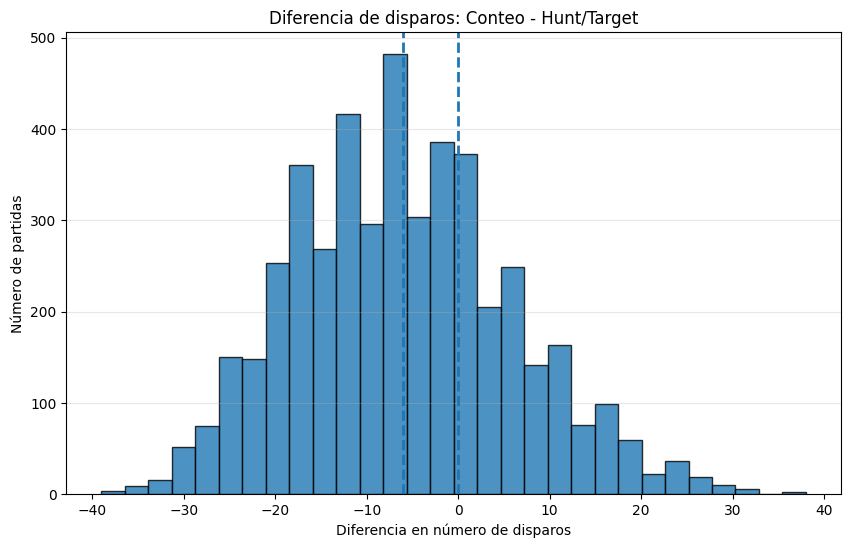

Conteo fue mejor en: 68.80 % de las partidas
Empataron en: 2.95 % de las partidas
Hunt/Target fue mejor en: 28.26 % de las partidas


In [ ]:
# ============================================================
# 25.1 DISTRIBUCIÓN DE LA VENTAJA PAREADA DE CONTEO
# ============================================================

import matplotlib.pyplot as plt                                                 #Importa las herramientas necesarias para construir el gráfico.


diferencias_conteo_hunt = (                                                     #Calcula la diferencia de disparos para cada misma configuración de flota.
    resultados_pareados_final["conteo"]
    - resultados_pareados_final["hunt_target"]
)


porcentaje_conteo_mejor = (                                                     #Calcula el porcentaje de partidas donde Conteo necesitó menos disparos.
    (diferencias_conteo_hunt < 0).mean()
    * 100
)


porcentaje_empate = (                                                           #Calcula el porcentaje de partidas donde ambas estrategias empataron.
    (diferencias_conteo_hunt == 0).mean()
    * 100
)


porcentaje_hunt_mejor = (                                                       #Calcula el porcentaje de partidas donde Hunt/Target necesitó menos disparos.
    (diferencias_conteo_hunt > 0).mean()
    * 100
)


plt.figure(figsize=(10, 6))                                                     #Crea el área destinada al gráfico.


plt.hist(                                                                       #Construye el histograma de diferencias pareadas.
    diferencias_conteo_hunt,
    bins=30,
    edgecolor="black",
    alpha=0.8
)


plt.axvline(                                                                    #Marca el punto donde ambas estrategias requieren exactamente los mismos disparos.
    x=0,
    linestyle="--",
    linewidth=2
)


plt.axvline(                                                                    #Marca la diferencia promedio observada en el experimento.
    x=diferencias_conteo_hunt.mean(),
    linestyle="--",
    linewidth=2
)


plt.title("Diferencia de disparos: Conteo - Hunt/Target")               #Define el título del gráfico.

plt.xlabel("Diferencia en número de disparos")                                  #Define el significado del eje horizontal.

plt.ylabel("Número de partidas")                                                #Define el significado del eje vertical.

plt.grid(axis="y", alpha=0.3)                                                   #Añade líneas horizontales para facilitar la lectura.

plt.show()                                                                      #Muestra el gráfico.


print(f"Conteo fue mejor en: {porcentaje_conteo_mejor:.2f} % de las partidas")  #Muestra la frecuencia en que Conteo superó a Hunt/Target.

print(f"Empataron en: {porcentaje_empate:.2f} % de las partidas")               #Muestra la frecuencia de empates.

print(f"Hunt/Target fue mejor en: {porcentaje_hunt_mejor:.2f} % de las partidas") #Muestra la frecuencia en que Hunt/Target superó a Conteo.

## 26. Costo computacional por estrategia

En esta sección se evalúa el tiempo de ejecución requerido por cada estrategia con el fin de complementar el análisis de eficiencia en número de disparos.

Para realizar una comparación justa, se genera previamente un mismo conjunto de configuraciones de flota y cada estrategia se ejecuta exactamente sobre esos mismos escenarios.

Para cada política se mide:

- el tiempo total requerido para completar el conjunto de partidas;
- el tiempo promedio de ejecución por partida.

Además, se utiliza la estrategia de Paridad como referencia para calcular un factor de costo computacional relativo. Este factor indica cuántas veces tarda una estrategia respecto al tiempo promedio requerido por Paridad.


In [ ]:
# ============================================================
# 26. COSTO COMPUTACIONAL POR ESTRATEGIA
# ============================================================

NUM_FLOTAS_TIEMPO = 500                                                        #Define un número suficiente de partidas para medir tiempos estables.


flotas_tiempo = [                                                              #Genera previamente las mismas flotas para todas las estrategias.
    generar_flota_valida()                                                     #Genera una configuración válida de la flota.
    for _ in range(NUM_FLOTAS_TIEMPO)                                          #Repite la generación para el número de escenarios definido.
]


resultados_tiempo = []                                                         #Inicializa la estructura donde se almacenarán los tiempos.


for estrategia in ESTRATEGIAS:                                                 #Recorre cada una de las estrategias evaluadas.

    tiempo_inicio = time.perf_counter()                                        #Registra el instante inicial de la ejecución.

    for flota_base in flotas_tiempo:                                           #Recorre exactamente las mismas flotas para cada estrategia.

        flota_estrategia = copy.deepcopy(flota_base)                           #Crea una copia independiente de la configuración original.

        simular_partida(                                                       #Ejecuta una partida completa con la estrategia actual.
            flota_estrategia,
            estrategia
        )

    tiempo_total = time.perf_counter() - tiempo_inicio                         #Calcula el tiempo total requerido por la estrategia.

    tiempo_promedio = tiempo_total / NUM_FLOTAS_TIEMPO                         #Calcula el tiempo promedio requerido por partida.

    resultados_tiempo.append({                                                 #Guarda las métricas computacionales obtenidas.
        "estrategia": estrategia,
        "tiempo_total_s": tiempo_total,
        "tiempo_promedio_s": tiempo_promedio
    })


df_tiempos = pd.DataFrame(resultados_tiempo)                                   #Convierte los resultados de tiempo en una tabla.


tiempo_base = df_tiempos.loc[                                                  #Obtiene el tiempo promedio de Paridad como referencia.
    df_tiempos["estrategia"] == "paridad",
    "tiempo_promedio_s"
].iloc[0]


df_tiempos["factor_vs_paridad"] = (                                            #Calcula cuántas veces más costosa es cada estrategia respecto a Paridad.
    df_tiempos["tiempo_promedio_s"]
    / tiempo_base
)


df_tiempos.round(6)                                                            #Muestra la tabla final de costo computacional.

,estrategia,tiempo_total_s,tiempo_promedio_s,factor_vs_paridad
0,paridad,1.364902,0.002730,1.000000
1,hunt_target,0.602232,0.001204,0.441228
2,conteo,9.665843,0.019332,7.081714


## 27. Relación entre eficacia estratégica y costo computacional

En esta sección se integran las métricas de desempeño dentro del juego con las métricas de tiempo de ejecución, con el objetivo de analizar el compromiso entre eficacia estratégica y costo computacional.

Para cada estrategia se consideran conjuntamente:

- el número promedio de disparos;
- la desviación estándar;
- el tiempo promedio de ejecución por partida;
- el costo computacional relativo respecto a Hunt/Target;
- el número de disparos ahorrados frente a Hunt/Target.

Esta comparación permite evaluar si una reducción en el número de disparos viene acompañada de un incremento significativo en el tiempo de cómputo.

Hunt/Target se utiliza como referencia porque representa una estrategia heurística más sofisticada que Paridad y constituye un punto de comparación natural frente a la estrategia de Conteo.

De esta manera, el análisis no se limita a identificar qué estrategia requiere menos disparos, sino que también permite valorar el costo adicional necesario para alcanzar esa mejora.

In [ ]:
# ============================================================
# 27. TRADE-OFF: EFICACIA ESTRATÉGICA VS COSTO COMPUTACIONAL
# ============================================================

tabla_tradeoff = tabla_resumen_final.merge(                                    #Une las métricas estratégicas con las métricas de tiempo.
    df_tiempos,                                                                #Utiliza la tabla obtenida en el benchmark computacional.
    on="estrategia",                                                           #Relaciona ambas tablas mediante el nombre de la estrategia.
    how="left"                                                                 #Conserva todas las estrategias de la tabla principal.
)


tabla_tradeoff["tiempo_promedio_ms"] = (                                       #Convierte el tiempo promedio por partida de segundos a milisegundos.
    tabla_tradeoff["tiempo_promedio_s"]
    * 1000
)


media_hunt = tabla_tradeoff.loc[                                                #Obtiene la media de disparos de Hunt/Target como referencia competitiva.
    tabla_tradeoff["estrategia"] == "hunt_target",
    "media"
].iloc[0]


tiempo_hunt = tabla_tradeoff.loc[                                               #Obtiene el tiempo promedio de Hunt/Target.
    tabla_tradeoff["estrategia"] == "hunt_target",
    "tiempo_promedio_ms"
].iloc[0]


tabla_tradeoff["disparos_ahorrados_vs_hunt"] = (                               #Calcula cuántos disparos ahorra cada estrategia frente a Hunt/Target.
    media_hunt
    - tabla_tradeoff["media"]
)


tabla_tradeoff["factor_tiempo_vs_hunt"] = (                                    #Calcula el costo computacional relativo respecto a Hunt/Target.
    tabla_tradeoff["tiempo_promedio_ms"]
    / tiempo_hunt
)


tabla_tradeoff = tabla_tradeoff[[                                               #Selecciona las columnas relevantes para presentar el trade-off.
    "estrategia",
    "media",
    "desviacion",
    "tiempo_promedio_ms",
    "factor_tiempo_vs_hunt",
    "disparos_ahorrados_vs_hunt"
]].round(3)                                                                    #Redondea los resultados para facilitar su interpretación.


tabla_tradeoff                                                                 #Muestra la tabla final de eficacia y costo computacional.

,estrategia,media,desviacion,tiempo_promedio_ms,factor_tiempo_vs_hunt,disparos_ahorrados_vs_hunt
0,conteo,46.11,8.85,19.332,16.050,6.05
1,hunt_target,52.16,8.21,1.204,1.000,0.00
2,paridad,95.51,4.45,2.730,2.266,-43.35


##28. Convergencia de las medias de Monte Carlo

En esta sección se analiza la estabilidad de las estimaciones obtenidas mediante simulación de Monte Carlo a medida que aumenta el número de partidas consideradas.

Para cada estrategia se calcula el promedio acumulado de disparos utilizando distintos tamaños de muestra, desde valores pequeños hasta el tamaño definitivo $N_{\text{sim}}$.

El objetivo es observar cómo evoluciona la estimación de la media y verificar si esta se estabiliza conforme aumenta el número de simulaciones.

Si las medias presentan variaciones cada vez menores para valores grandes de $N$, se obtiene evidencia de convergencia numérica y de que el tamaño de simulación seleccionado es suficiente para producir resultados estables.

La representación gráfica permite comparar simultáneamente las trayectorias de Conteo, Hunt/Target y Paridad, mientras que la tabla final muestra los valores estimados para cada tamaño de muestra considerado.

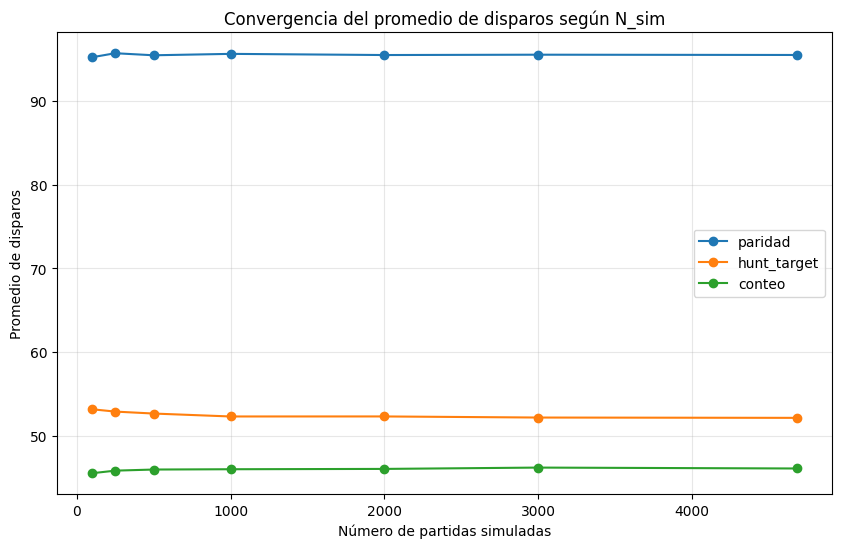

estrategia,conteo,hunt_target,paridad
n,,,
100,45.540,53.180,95.240
250,45.848,52.904,95.720
500,45.980,52.670,95.474
1000,46.016,52.320,95.643
2000,46.055,52.324,95.504
3000,46.213,52.193,95.544
4682,46.106,52.155,95.511


In [ ]:
# ============================================================
# 28. CONVERGENCIA DE LAS MEDIAS DE MONTE CARLO
# ============================================================

TAMANOS_CONVERGENCIA = [100, 250, 500, 1000, 2000, 3000, N_sim]                #Define distintos tamaños acumulados para estudiar la estabilidad de las medias.


resultados_convergencia = []                                                    #Inicializa la estructura donde se almacenarán las medias acumuladas.


for estrategia in ESTRATEGIAS:                                                 #Recorre cada estrategia incluida en el experimento.

    datos_estrategia = resultados_montecarlo[                                  #Selecciona únicamente las observaciones correspondientes a la estrategia actual.
        resultados_montecarlo["estrategia"] == estrategia
    ].sort_values("id_partida")                                                #Ordena las partidas para calcular medias acumuladas de forma reproducible.


    for n in TAMANOS_CONVERGENCIA:                                             #Recorre cada tamaño de simulación definido.

        media_n = datos_estrategia.iloc[:n][                                   #Selecciona las primeras n configuraciones simuladas.
            "total_disparos"
        ].mean()                                                               #Calcula la media obtenida utilizando únicamente esas n partidas.

        resultados_convergencia.append({                                       #Guarda el resultado correspondiente al tamaño y estrategia actuales.
            "n": n,
            "estrategia": estrategia,
            "media_disparos": media_n
        })


df_convergencia = pd.DataFrame(                                                #Convierte los resultados de convergencia en una tabla.
    resultados_convergencia
)


plt.figure(figsize=(10, 6))                                                    #Crea el área donde se dibujará el gráfico.


for estrategia in ESTRATEGIAS:                                                 #Recorre cada estrategia para construir su curva de convergencia.

    datos = df_convergencia[                                                   #Selecciona los resultados correspondientes a la estrategia actual.
        df_convergencia["estrategia"] == estrategia
    ]

    plt.plot(                                                                  #Dibuja la evolución de la media conforme aumenta N.
        datos["n"],
        datos["media_disparos"],
        marker="o",
        label=estrategia
    )


plt.title("Convergencia del promedio de disparos según N_sim")                  #Define el título del gráfico.

plt.xlabel("Número de partidas simuladas")                                     #Define el eje horizontal como tamaño de simulación.

plt.ylabel("Promedio de disparos")                                             #Define el eje vertical como estimación de la media.

plt.legend()                                                                   #Identifica las curvas correspondientes a cada estrategia.

plt.grid(alpha=0.3)                                                            #Añade una cuadrícula para facilitar la interpretación.

plt.show()                                                                     #Muestra el gráfico.


df_convergencia.pivot(                                                         #Construye una tabla para inspeccionar numéricamente la convergencia.
    index="n",
    columns="estrategia",
    values="media_disparos"
).round(3)

## 29. Robustez del experimento

En esta sección se evalúa si los resultados obtenidos dependen de una elección particular de la semilla aleatoria utilizada para generar las configuraciones de flota, posteriormente se evaluaran las estrategias frente a otros cambios.

El objetivo es verificar si el orden relativo de desempeño

$$
\text{Conteo} < \text{Hunt/Target} < \text{Paridad}
$$

se mantiene de forma consistente cuando cambian las configuraciones aleatorias generadas.



In [ ]:
# ============================================================
# 29. ROBUSTEZ DEL EXPERIMENTO FRENTE A LA SEMILLA
# ============================================================

SEMILLAS_ROBUSTEZ = [11, 23, 37, 51, 89]                                       #Define varias semillas independientes para repetir el experimento.

N_ROBUSTEZ = 1000                                                              #Define un tamaño intermedio para evaluar estabilidad sin repetir todo N_sim.


resultados_robustez = []                                                       #Inicializa la estructura donde se almacenarán los resultados.


for semilla in SEMILLAS_ROBUSTEZ:                                              #Recorre cada semilla seleccionada.

    resultados_semilla = ejecutar_simulacion_montecarlo(                         #Ejecuta nuevamente el experimento pareado.
        numero_partidas=N_ROBUSTEZ,                                            #Utiliza el número de partidas definido para robustez.
        semilla=semilla                                                        #Utiliza la semilla actual.
    )

    resumen_semilla = resultados_semilla.groupby(                              #Agrupa los resultados por estrategia.
        "estrategia"
    )["total_disparos"].mean()                                                 #Calcula el promedio de disparos para cada estrategia.

    resultados_robustez.append({                                               #Guarda las medias obtenidas con la semilla actual.
        "semilla": semilla,
        "conteo": resumen_semilla["conteo"],
        "hunt_target": resumen_semilla["hunt_target"],
        "paridad": resumen_semilla["paridad"]
    })


df_robustez = pd.DataFrame(resultados_robustez)                                #Convierte los resultados de robustez en una tabla.


df_robustez["ranking_correcto"] = (                                            #Comprueba que el orden esperado se mantenga en cada repetición.
    (df_robustez["conteo"] < df_robustez["hunt_target"])
    & (df_robustez["hunt_target"] < df_robustez["paridad"])
)


print(df_robustez.round(2))                                                     #Muestra los resultados obtenidos para cada semilla.

print(
    "\nRanking Conteo < Hunt/Target < Paridad en:",
    f"{df_robustez['ranking_correcto'].mean() * 100:.1f} % de las semillas"
)                                                                               #Muestra el porcentaje de repeticiones donde se conserva el ranking.

   semilla  conteo  hunt_target  paridad  ranking_correcto
0       11   46.15        51.66    95.51              True
1       23   46.02        52.14    95.14              True
2       37   46.33        51.67    95.66              True
3       51   46.57        51.88    95.41              True
4       89   45.73        51.64    95.82              True

Ranking Conteo < Hunt/Target < Paridad en: 100.0 % de las semillas


## 29.1  Análisis de sensibilidad: cambios de reglas, distribución y desempate

Esta sección evalúa la robustez de las tres estrategias frente a otras modificaciones en las condiciones del experimento.

Se consideran cuatro escenarios: base, sin adyacencia entre barcos, distribución sesgada hacia los bordes y desempate determinista.

Para cada escenario se ejecutan 1.000 simulaciones por estrategia, utilizando las mismas flotas para garantizar comparaciones emparejadas.

Se calculan las medias de disparos, medidas de dispersión, intervalos de confianza del 95 %, tiempos de ejecución y diferencias entre estrategias, con el propósito de determinar si Conteo mantiene su ventaja bajo las nuevas condiciones.


In [ ]:
# ============================================================
# 29.1 ANÁLISIS DE SENSIBILIDAD
# Escenarios: base, sin adyacencia, sesgo hacia bordes, desempate determinista.
# ============================================================
from scipy.stats import t as distribucion_t
from time import perf_counter

# Para el informe definitivo, usar N_SENSIBILIDAD = N_sim.
# Con 1000 réplicas por escenario se puede hacer primero una prueba de ejecución.
N_SENSIBILIDAD = 1000
SEMILLA_SENSIBILIDAD = 2026

ESCENARIOS_SENSIBILIDAD = {
    "Base": {"adyacencia": True, "distribucion": "secuencial", "desempate": "aleatorio"},
    "Sin adyacencia": {"adyacencia": False, "distribucion": "secuencial", "desempate": "aleatorio"},
    "Sesgo a bordes": {"adyacencia": True, "distribucion": "bordes", "desempate": "aleatorio"},
    "Desempate determinista": {"adyacencia": True, "distribucion": "secuencial", "desempate": "determinista"},
}

# Todas las colocaciones posibles de cada longitud; se reutilizan durante la simulación.
COLOCACIONES_SENSIBILIDAD = {}
for longitud in set(FLOTA_ESTANDAR):
    opciones = []
    for orientacion in ORIENTACIONES:
        filas = range(TAMANO_TABLERO if orientacion == "H" else TAMANO_TABLERO-longitud+1)
        columnas = range(TAMANO_TABLERO-longitud+1 if orientacion == "H" else TAMANO_TABLERO)
        for fila in filas:
            for columna in columnas:
                celdas = generar_celdas_barco(fila, columna, longitud, orientacion)
                opciones.append((orientacion, celdas))
    COLOCACIONES_SENSIBILIDAD[longitud] = opciones

def flota_escenario(adyacencia=True, distribucion="secuencial", max_reinicios=1000):
    """Muestreo secuencial de colocaciones; NO uniforme sobre flotas completas."""
    for _ in range(max_reinicios):
        flota, ocupadas = [], set()
        for id_barco, longitud in enumerate(FLOTA_ESTANDAR):
            opciones = []
            for orientacion, celdas in COLOCACIONES_SENSIBILIDAD[longitud]:
                if not celdas.isdisjoint(ocupadas):
                    continue
                if not adyacencia and any(
                    abs(f-f2) <= 1 and abs(c-c2) <= 1
                    for f,c in celdas for f2,c2 in ocupadas
                ):
                    continue
                opciones.append((orientacion, celdas))
            if not opciones:
                break
            if distribucion == "bordes":
                # Peso ilustrativo: mayor probabilidad para colocaciones cercanas al borde.
                pesos = [1.0 + 4.0 * sum(
                    min(f,c,TAMANO_TABLERO-1-f,TAMANO_TABLERO-1-c) == 0
                    for f,c in celdas
                ) / longitud for _, celdas in opciones]
                orientacion, celdas = random.choices(opciones, weights=pesos, k=1)[0]
            elif distribucion == "secuencial":
                orientacion, celdas = random.choice(opciones)
            else:
                raise ValueError(f"Distribución no reconocida: {distribucion}")
            flota.append({"id_barco": id_barco, "longitud": longitud,
                          "orientacion": orientacion, "celdas": set(celdas)})
            ocupadas.update(celdas)
        if len(flota) == len(FLOTA_ESTANDAR):
            return flota
    raise RuntimeError("No se pudo construir una flota válida tras varios reinicios")

registros_sensibilidad = []
regla_desempate_original = REGLA_DESEMPATE
try:
    for indice, (nombre, config) in enumerate(ESCENARIOS_SENSIBILIDAD.items()):
        random.seed(SEMILLA_SENSIBILIDAD + 10000*indice)
        REGLA_DESEMPATE = config["desempate"]
        print(f"Ejecutando {nombre}: {N_SENSIBILIDAD} flotas...")
        for id_partida in range(N_SENSIBILIDAD):
            flota = flota_escenario(config["adyacencia"], config["distribucion"])
            # Una única flota compartida por las tres estrategias en cada réplica.
            for estrategia in ESTRATEGIAS:
                inicio = perf_counter()
                resultado = simular_partida(flota, estrategia)  # Copia la flota internamente.
                tiempo = perf_counter() - inicio
                registros_sensibilidad.append({
                    "escenario": nombre, "id_partida": id_partida,
                    "estrategia": estrategia, "total_disparos": resultado["total_disparos"],
                    "tiempo_segundos": tiempo,
                })
finally:
    REGLA_DESEMPATE = regla_desempate_original

resultados_sensibilidad = pd.DataFrame(registros_sensibilidad)
assert len(resultados_sensibilidad) == len(ESCENARIOS_SENSIBILIDAD)*N_SENSIBILIDAD*len(ESTRATEGIAS)
assert resultados_sensibilidad.groupby(["escenario", "id_partida"])["estrategia"].nunique().eq(3).all()

# Estadísticas por estrategia y escenario, con IC t bilateral al 95 %.
def resumir_sensibilidad(grupo):
    x = grupo["total_disparos"]
    n = len(x)
    media, desv = x.mean(), x.std(ddof=1)
    margen = distribucion_t.ppf(.975, n-1)*desv/np.sqrt(n)
    return pd.Series({"n": n, "media": media, "varianza": x.var(ddof=1),
                      "desviacion": desv, "mediana": x.median(),
                      "ic95_inf": media-margen, "ic95_sup": media+margen,
                      "tiempo_medio_s": grupo["tiempo_segundos"].mean()})

resumen_sensibilidad = (resultados_sensibilidad
    .groupby(["escenario", "estrategia"])
    .apply(resumir_sensibilidad).reset_index())

# Ahorro positivo = la estrategia de referencia necesita másd disparos que Conteo.
comparaciones_sensibilidad = []
for escenario, grupo in resultados_sensibilidad.groupby("escenario"):
    pares = grupo.pivot(index="id_partida", columns="estrategia", values="total_disparos")
    for referencia in ["hunt_target", "paridad"]:
        diferencias = pares[referencia] - pares["conteo"]
        n = len(diferencias)
        media, desv = diferencias.mean(), diferencias.std(ddof=1)
        margen = distribucion_t.ppf(.975, n-1)*desv/np.sqrt(n)
        comparaciones_sensibilidad.append({
            "escenario": escenario, "referencia": referencia, "n": n,
            "ahorro_medio_conteo": media, "ic95_inf": media-margen,
            "ic95_sup": media+margen,
            "conteo_gana_pct": 100*(diferencias > 0).mean(),
            "empate_pct": 100*(diferencias == 0).mean(),
        })

diferencias_sensibilidad = pd.DataFrame(comparaciones_sensibilidad)
print("\nESTADÍSTICAS POR ESCENARIO Y ESTRATEGIA")
display(resumen_sensibilidad.round(3))
print("\nDIFERENCIAS EMPAREJADAS (ahorro positivo favorece a Conteo)")
display(diferencias_sensibilidad.round(3))


Ejecutando Base: 1000 flotas...
Ejecutando Sin adyacencia: 1000 flotas...
Ejecutando Sesgo a bordes: 1000 flotas...
Ejecutando Desempate determinista: 1000 flotas...

ESTADÍSTICAS POR ESCENARIO Y ESTRATEGIA


/tmp/ipykernel_4680/4099234530.py:107: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(resumir_sensibilidad).reset_index())


,escenario,estrategia,n,media,varianza,desviacion,mediana,ic95_inf,ic95_sup,tiempo_medio_s
0,Base,conteo,1000.0,45.960,79.005,8.888,45.5,45.408,46.512,0.017
1,Base,hunt_target,1000.0,51.661,67.976,8.245,52.5,51.149,52.173,0.001
2,Base,paridad,1000.0,95.835,18.568,4.309,97.0,95.568,96.102,0.003
3,Desempate determinista,conteo,1000.0,46.054,81.190,9.011,46.0,45.495,46.613,0.019
4,Desempate determinista,hunt_target,1000.0,55.342,49.539,7.038,56.0,54.905,55.779,0.001
5,Desempate determinista,paridad,1000.0,93.108,33.141,5.757,94.0,92.751,93.465,0.003
6,Sesgo a bordes,conteo,1000.0,48.670,70.023,8.368,48.0,48.151,49.189,0.021
7,Sesgo a bordes,hunt_target,1000.0,51.329,74.257,8.617,52.0,50.794,51.864,0.001
8,Sesgo a bordes,paridad,1000.0,95.685,19.443,4.409,97.0,95.411,95.959,0.003
9,Sin adyacencia,conteo,1000.0,47.071,62.551,7.909,46.0,46.580,47.562,0.019



DIFERENCIAS EMPAREJADAS (ahorro positivo favorece a Conteo)


,escenario,referencia,n,ahorro_medio_conteo,ic95_inf,ic95_sup,conteo_gana_pct,empate_pct
0,Base,hunt_target,1000,5.701,4.939,6.463,66.5,2.7
1,Base,paridad,1000,49.875,49.261,50.489,100.0,0.0
2,Desempate determinista,hunt_target,1000,9.288,8.649,9.927,79.2,2.7
3,Desempate determinista,paridad,1000,47.054,46.449,47.659,100.0,0.0
4,Sesgo a bordes,hunt_target,1000,2.659,1.904,3.414,59.1,2.3
5,Sesgo a bordes,paridad,1000,47.015,46.435,47.595,100.0,0.0
6,Sin adyacencia,hunt_target,1000,6.474,5.788,7.160,69.7,3.4
7,Sin adyacencia,paridad,1000,48.503,47.936,49.070,100.0,0.0


### 29.2 Visualización del análisis de sensibilidad

Esta sección presenta gráficamente los resultados obtenidos en los distintos escenarios experimentales.

Se comparan las medias de disparos, los intervalos de confianza del 95 %, los ahorros emparejados y el orden de desempeño de las estrategias.

Las visualizaciones permiten identificar si Conteo de Encajes Consistentes continúa siendo la estrategia más eficiente y cómo varía su ventaja cuando se modifican las condiciones del experimento.

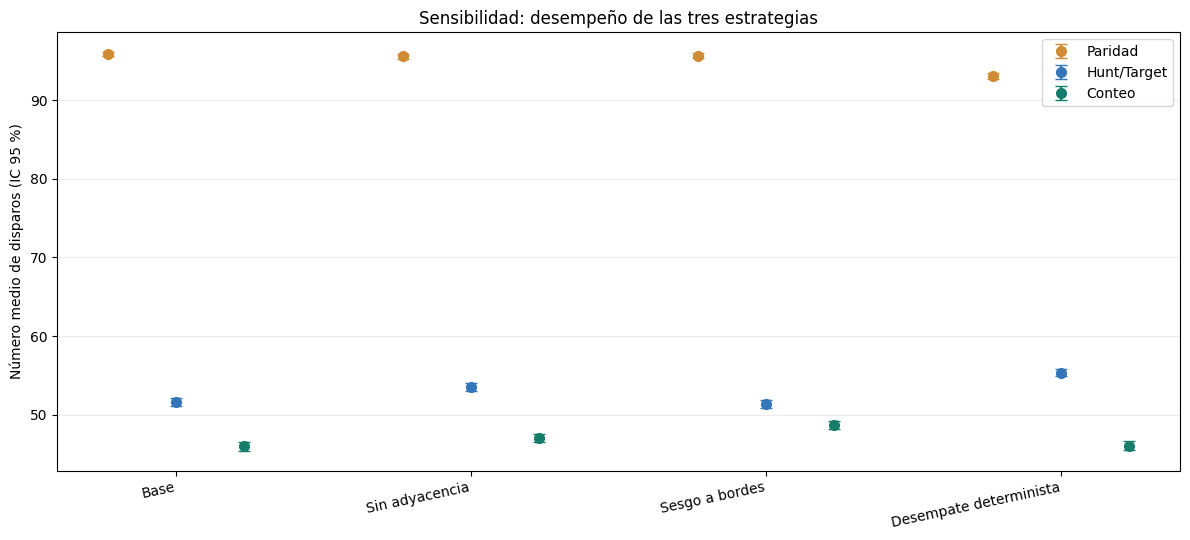

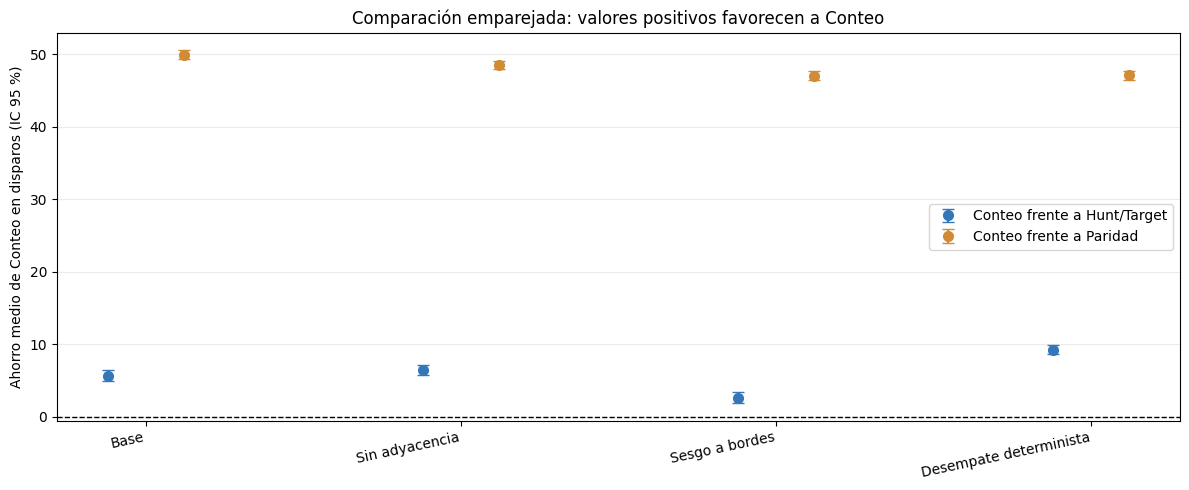

ORDEN DE DESEMPEÑO POR ESCENARIO (menor media = mejor)


estrategia,conteo,hunt_target,paridad,mejor_por_media,gana_conteo
escenario,,,,,
Base,45.96,51.66,95.84,Conteo,True
Sin adyacencia,47.07,53.54,95.57,Conteo,True
Sesgo a bordes,48.67,51.33,95.68,Conteo,True
Desempate determinista,46.05,55.34,93.11,Conteo,True


Nota: el ranking por medias no equivale por sí solo a significancia estadística.
Nota: el muestreo secuencial utilizado aquí no garantiza uniformidad entre flotas completas.


In [ ]:
# ============================================================
# 29.2 VISUALIZACIÓN DEL ANÁLISIS DE SENSIBILIDAD
# ============================================================
if "resumen_sensibilidad" not in globals() or "diferencias_sensibilidad" not in globals():
    raise RuntimeError("Ejecuta primero la sección 'Análisis de sensibilidad'.")

orden = list(ESCENARIOS_SENSIBILIDAD)
etiquetas = {"conteo": "Conteo", "hunt_target": "Hunt/Target", "paridad": "Paridad"}
colores = {"conteo": "#167d6b", "hunt_target": "#3476b8", "paridad": "#d08b34"}

# Figura 1: media e intervalo de confianza al 95 % por escenario.
fig, ax = plt.subplots(figsize=(12, 5.5))
pos = np.arange(len(orden))
for j, estrategia in enumerate(ESTRATEGIAS):
    datos = (resumen_sensibilidad[resumen_sensibilidad["estrategia"] == estrategia]
             .set_index("escenario").loc[orden])
    x = pos + (j-1)*.23
    y = datos["media"].to_numpy()
    err = np.vstack([y-datos["ic95_inf"].to_numpy(), datos["ic95_sup"].to_numpy()-y])
    ax.errorbar(x, y, yerr=err, fmt="o", capsize=4, markersize=7,
                color=colores[estrategia], label=etiquetas[estrategia])
ax.set_xticks(pos, orden, rotation=12, ha="right")
ax.set_ylabel("Número medio de disparos (IC 95 %)")
ax.set_title("Sensibilidad: desempeño de las tres estrategias")
ax.grid(axis="y", alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

# Figura 2: ahorro medio emparejado de Conteo con IC 95 %.
fig, ax = plt.subplots(figsize=(12, 5))
for j, referencia in enumerate(["hunt_target", "paridad"]):
    datos = (diferencias_sensibilidad[diferencias_sensibilidad["referencia"] == referencia]
             .set_index("escenario").loc[orden])
    x = pos + (j-.5)*.24
    y = datos["ahorro_medio_conteo"].to_numpy()
    err = np.vstack([y-datos["ic95_inf"].to_numpy(), datos["ic95_sup"].to_numpy()-y])
    ax.errorbar(x, y, yerr=err, fmt="o", capsize=4, markersize=7,
                color=colores[referencia], label=f"Conteo frente a {etiquetas[referencia]}")
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xticks(pos, orden, rotation=12, ha="right")
ax.set_ylabel("Ahorro medio de Conteo en disparos (IC 95 %)")
ax.set_title("Comparación emparejada: valores positivos favorecen a Conteo")
ax.grid(axis="y", alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

# Tabla de ranking: el menor promedio es el mejor en cada escenario.
tabla_ranking = resumen_sensibilidad.pivot(index="escenario", columns="estrategia", values="media").loc[orden]
tabla_ranking["mejor_por_media"] = tabla_ranking[ESTRATEGIAS].idxmin(axis=1).map(etiquetas)
tabla_ranking["gana_conteo"] = tabla_ranking["mejor_por_media"].eq("Conteo")
print("ORDEN DE DESEMPEÑO POR ESCENARIO (menor media = mejor)")
display(tabla_ranking.round(2))
print("Nota: el ranking por medias no equivale por sí solo a significancia estadística.")
print("Nota: el muestreo secuencial utilizado aquí no garantiza uniformidad entre flotas completas.")


## 30. Conclusiones

Los resultados obtenidos permiten concluir que la estrategia basada en el conteo de encajes consistentes presenta el mejor desempeño entre las estrategias evaluadas en términos del número de disparos necesarios para hundir completamente la flota.

En la simulación definitiva, realizada sobre $N_{\text{sim}}=4682$ configuraciones de flota, los promedios obtenidos fueron:

- Conteo: $46.11$ disparos.
- Hunt/Target: $52.16$ disparos.
- Paridad: $95.51$ disparos.

En términos relativos, la estrategia de Conteo requirió aproximadamente un $11.60\%$ menos de disparos que Hunt/Target y un $51.73\%$ menos que Paridad.

En particular, la diferencia media entre Conteo y Hunt/Target fue de $-6.05$ disparos, con un intervalo de confianza del $95\%$ aproximadamente igual a

$$
[-6.39,\,-5.71],
$$

y un tamaño del efecto pareado de aproximadamente $d=-0.50$.

Además, Conteo necesitó menos disparos que Hunt/Target en aproximadamente el $68.80\%$ de las configuraciones evaluadas, mientras que ambas estrategias empataron en cerca del $2.95\%$ de los casos.

Los análisis de robustez mostraron que sin importar modificaciones en las reglas, se mantuvo el orden:

$$
\text{Conteo} < \text{Hunt/Target} < \text{Paridad}
$$

El análisis de sensibilidad mostró que Conteo de Encajes Consistentes mantuvo el menor número promedio de disparos en los cuatro escenarios evaluados; La mayor ventaja de Conteo frente a Hunt/Target se presentó con desempate determinista de 9,29 disparos de ahorro promedio, mientras que la menor ocurrió con sesgo hacia los bordes 2,66 disparos. Asimismo, el estudio de convergencia mostró que las medias se estabilizan progresivamente al aumentar el número de simulaciones, respaldando la elección de $N_{\text{sim}}$ y la estabilidad numérica de los resultados.

Esta mejora en eficiencia estratégica tiene, sin embargo, un costo computacional. La estrategia de Conteo requiere un mayor tiempo de ejecución que Hunt/Target y Paridad debido a la construcción y evaluación de los encajes consistentes en cada estado de la partida.

En conjunto, los resultados muestran que incorporar explícitamente la información disponible mediante el mapa de conteo $C_t(v)$ permite realizar una búsqueda considerablemente más eficiente que las estrategias heurísticas consideradas, a cambio de un mayor esfuerzo computacional.

De esta manera, el experimento respalda la utilidad del enfoque probabilístico propuesto para la toma de decisiones en Batalla Naval y permite cuantificar tanto su ventaja estratégica como el costo necesario para obtenerla.